# LLM Model Scoring Analysis
## Standard Deviation Based Performance Evaluation

This notebook implements a comprehensive model scoring system for LLMs using data from the **Artificial Analysis** API, combining intelligence, speed, reliability, and cost efficiency across multiple scoring schemes and real-world evaluation costs.

---

### Table of Contents

Sections are code cells, so they are listed in **notebook order** with their section numbers and titles (use the notebook outline to jump).

1. Import Required Libraries
2. Load Model Performance Data
    - 2.1b OpenRouter Throughput Fallback (live telemetry, strict matching, source-tagged)
    - 2.1 Inspect API Data Structure
    - 2.2 Catalog Cross-Check: OpenRouter vs Artificial Analysis
    - 2.3 Watch-List Spotlight: DeepSeek / Inception-Mercury
3. Filter Models by Intelligence Threshold
4. Efficiency Analysis
    - 3.1 Intelligence to Cost Ratio
    - 3.2 Ratio with Intelligence Exponent (Intel² / Cost)
    - 3.3 Throughput-weighted Intelligence Efficiency (Additive)
    - 3.4 Multiplicative Intelligence Efficiency (√Throughput × Intel)
    - 3.4b Two Rankings: measured-only vs expanded (imputation flagged)
    - 3.4b Methodology Notes: Reliability, Matching, and Two Rankings
    - 3.4c Exponential Speed-Utility Metric (saturating, not sqrt)
    - Free-Model Catalog Prep (free-model IDs + catalog patch)
    - 3.7 Free Models: Raw Performance Metrics (no cost factor)
    - 3.8 AA Intelligence >= 44 (Above-44): Cost-Normalized Comparison
    - 3.9 Formula Reference: AA Intelligence Index >= 44
    - 3.10 AA Intelligence >= 44 (Above-44): Weighted-Average-Price Comparison (OpenRouter effective pricing)
5. Comparison: Std Dev vs Existing Metrics
    - 4.1 Curve Scoring (0-100) Comparison
    - 4.1b Vision Models Comparison
    - 4.2 Correlation Analysis
    - 4.3 Detailed Scoring Breakdown
    - 4.4 Practical Recommendations
6. Evaluation Suite Cost (executes after §5 in the notebook)
    - 3.5 Fetch AA Evaluation Suite Cost
    - 3.6 Multiplicative Efficiency with Eval Cost
7. Appendix: Resume Benchmarks
    - V2 Enhanced Resume Parsing Benchmark
    - V3 Resume Writing Benchmark (17 models)
    - V3 Percentile vs Full Field
8. OpenRouter Routing Stealth Test ("dumb provider" detection)

> **Numbering note:** the list follows the notebook's own headings. The efficiency subsections keep their `3.x` labels even though they sit under top-level section 4 here, and `3.5`/`3.6` are numbered as part of §3 but execute after §5. The stealth-test markdown heading reads `## 5.` while it is the eighth top-level section in this list.

---

### What We're Doing Here

1. **Base Metric Calculation**: `((intelligence + speed) × (1 - hallucination_rate)) / cost`

2. **Efficiency Metrics**:
   - **Additive (3.3)**: `(Throughput + Intel²) × (1-Hall) / Cost`
   - **Multiplicative (3.4)**: `(√Throughput × Intel) × (1-Hall) / Cost`
   - **Eval-Cost Multiplicative (3.6)**: same formula using evaluation-suite cost

3. **Category Comparisons**:
   - **Free models (3.7)**: raw performance only; no cost denominator
   - **AA Intelligence >= 44 (3.8)**: cost-normalized comparison ("Above-44" — 44.0+ rounds up to 45, matching the displayed 45+ elite tier)
   - **AA Intelligence >= 44, weighted prices (3.10)**: same formulas, but the cost denominator is OpenRouter's *Weighted Average Input/Output* price — the average price actually paid per 1M tokens over the past day (caching + provider discounts factored in), not the listed price

4. **Evaluation Suite Cost (3.5)**: estimated USD cost to run the full Intelligence Index benchmark, including verbosity.

5. **Standard Deviation Scoring**: models scored by distance from mean performance.

6. **Ranking Comparisons**: side-by-side scoring-method comparisons.


---

### Data Quality Rules (2026-10 audit)

- **Missing ≠ zero**: AA speed values `<=0` are treated as missing.
- **Family imputation**: missing throughput/reliability uses family medians computed before filtering.
- **True NaNs stay NaN**: models without sufficient data are excluded visibly rather than scored as zero.
- **OpenRouter fallback**: rescued throughput is tagged `Throughput_Source` (`openrouter-live` or `openrouter-snapshot`).
- **Category comparisons**: free-model plots do not use cost; above-45 plots divide by positive cost.

---

### Known Limitations

- Evaluation-suite costs use a cached snapshot plus a best-effort live scrape.
- OpenRouter throughput telemetry is intermittent and may fall back to a point-in-time snapshot.
- The reliability value is an IFBench/HLE-derived proxy.

---

### Data Sources

#### Artificial Analysis
Independent LLM benchmarking platform testing models across intelligence, performance, price, and speed.

**Key Scores:**
- **Intelligence Index v4.0** — composite of GDPval-AA, Terminal-Bench Hard, SciCode, GPQA, HLE, IFBench, AA-Omniscience, AA-LCR, and related evaluations.
- **Performance** — throughput, TTFT, context window, and price per token.

**The API**: `https://artificialanalysis.ai/api/v2/data/llms/models`

#### OpenRouter
Pricing fallback and provider performance telemetry when available.

**Weighted Average pricing** (used in 3.10): `GET /api/frontend/v1/stats/effective-pricing?permaslug=<canonical-slug>&shape=v7&variant=standard` returns `weightedInputPrice` / `weightedOutputPrice` — the traffic-weighted average price actually paid per 1M tokens over the past day. The `permaslug` comes from `GET /api/frontend/v1/catalog/models` (field `permaslug`, the date-suffixed canonical slug).

#### AA Evaluation Suite Cost
Estimated cost to run the full Intelligence Index evaluation suite, including model verbosity.

## 1. Import Required Libraries
Import pandas, matplotlib, seaborn, numpy, and other necessary libraries for data manipulation and visualization.

In [1]:
from dotenv import load_dotenv
load_dotenv()  # reads .env (keys are never hardcoded)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

# API Configuration
import os
API_KEY = os.getenv("ARTIFICIAL_ANALYSIS_KEY")
BASE_URL = "https://artificialanalysis.ai/api/v2/data/llms/models"

## 2. Load Model Performance Data
Load the GDPval-AA leaderboard data containing model names, intelligence ratings, performance metrics, and pricing information from Artificial Analysis API.

In [2]:
# ============================================================================
# 2. LOAD AA DATA + CORE METRICS + OPENROUTER PRICE FALLBACK
# ============================================================================
# Reliability: IFBench and HLE are kept as SEPARATE columns. The composite uses
# IFBench only — HLE is never substituted, so a rank cannot move because a
# model's *available benchmark* changed rather than its reliability.
#
# Price fallback: strict, version-aware matching (Jaccard >= 0.85 + exact
# version-token agreement). No substring matching, so "v4" never matches
# "v4.1". Every match records Price_Source / Price_Match_Key / Jaccard.
# ============================================================================

import re as _pre

def fetch_aa_data():
    """Fetch and flatten the AA models endpoint; fall back to local CSV."""
    try:
        r = requests.get(BASE_URL, headers={'x-api-key': API_KEY}, timeout=60)
        r.raise_for_status()
        data = r.json()
        if isinstance(data, dict) and isinstance(data.get('data'), list):
            return pd.json_normalize(data['data'], sep='_')
        if isinstance(data, list):
            return pd.json_normalize(data, sep='_')
        if isinstance(data, dict) and 'models' in data:
            return pd.json_normalize(data['models'], sep='_')
        print('Unexpected API shape; falling back to local CSV.')
    except Exception as e:
        print(f'AA fetch failed ({e}); falling back to local CSV.')
    return pd.read_csv('ai_models_extracted.csv')


df = fetch_aa_data()
if 'name' in df.columns:
    df.rename(columns={'name': 'Model'}, inplace=True)
df_orig = df.copy()          # unfiltered snapshot for later cells

# ── Core metrics ────────────────────────────────────────────────────────────
df['AA_Intelligence_Index'] = pd.to_numeric(
    df.get('evaluations_artificial_analysis_intelligence_index'), errors='coerce')
df['GDPval_AA'] = df['AA_Intelligence_Index']
df['TerminalBench_Hard'] = pd.to_numeric(
    df.get('evaluations_artificial_analysis_coding_index'), errors='coerce').fillna(0)
df['AA_Omniscience_Index'] = pd.to_numeric(
    df.get('evaluations_mmlu_pro'), errors='coerce').fillna(0)

# ── Reliability: two benchmarks, two columns, no substitution ───────────────
_IFB = pd.to_numeric(df.get('evaluations_ifbench'), errors='coerce')
_HLE = pd.to_numeric(df.get('evaluations_hle'), errors='coerce')
df['IFBench_Score'] = _IFB
df['HLE_Score'] = _HLE
df['Reliability_IFBench'] = _IFB.clip(lower=0.0, upper=1.0)   # used by composite
df['Reliability_HLE'] = _HLE.clip(lower=0.0, upper=1.0)       # reference only
df['Reliability_Factor'] = df['Reliability_IFBench']
df['Reliability_Source'] = np.where(
    df['Reliability_IFBench'].notna(), 'ifbench',
    np.where(df['Reliability_HLE'].notna(), 'missing (HLE available, not used)', 'missing'))
df['AA_Hallucination_Rate'] = 1 - df['Reliability_Factor']    # legacy alias

print('=' * 78)
print('RELIABILITY (IFBench and HLE kept separate — no substitution)')
print('=' * 78)
print(f"  IFBench available : {int(df['Reliability_IFBench'].notna().sum())}/{len(df)}")
print(f"  HLE available     : {int(df['Reliability_HLE'].notna().sum())}/{len(df)}")
print(f"  Both available    : {int((df['Reliability_IFBench'].notna() & df['Reliability_HLE'].notna()).sum())}")
print(f"  IFBench missing   : {int(df['Reliability_IFBench'].isna().sum())} "
      f"(excluded from measured-only, flagged in expanded)")
print('=' * 78)

# ── Blended price (3:1 input:output) ────────────────────────────────────────
df['Price_Input_1M'] = pd.to_numeric(
    df.get('pricing_price_1m_input_tokens'), errors='coerce').fillna(0)
df['Price_Output_1M'] = pd.to_numeric(
    df.get('pricing_price_1m_output_tokens'), errors='coerce').fillna(0)
_derived = (df['Price_Input_1M'] * 3 + df['Price_Output_1M']) / 4
_api_blend = pd.to_numeric(df.get('pricing_price_1m_blended_3_to_1'), errors='coerce').fillna(0)
df['Price_Blended_USD_per_1M'] = _derived.where(_derived > 0, _api_blend)
df['Cost_to_Run_Index'] = df['AA_Intelligence_Index'] * df['Price_Blended_USD_per_1M']

# ── OpenRouter price map ────────────────────────────────────────────────────
print('\n' + '=' * 78)
print('OPENROUTER PRICE FALLBACK (strict, version-aware)')
print('=' * 78)

or_price_map = {}
_or_key = os.getenv('OPENROUTER_API_KEY_1')
if _or_key:
    try:
        _or = requests.get('https://openrouter.ai/api/v1/models',
                           headers={'Authorization': f'Bearer {_or_key}'}, timeout=30)
        _or.raise_for_status()
        for m in (_or.json().get('data') or []):
            try:
                pi = float((m.get('pricing') or {}).get('prompt', 0) or 0)
                po = float((m.get('pricing') or {}).get('completion', 0) or 0)
            except (TypeError, ValueError):
                continue
            if pi <= 0 and po <= 0:
                continue
            blended = (pi * 3 + po) / 4 * 1_000_000
            for key in {str(m.get('name', '')).lower().strip(),
                        str(m.get('id', '')).lower().strip(),
                        str(m.get('id', '')).lower().rsplit('/', 1)[-1]}:
                if key:
                    or_price_map[key] = blended
        print(f'Loaded {len(or_price_map)} OpenRouter price entries')
    except Exception as e:
        print(f'OpenRouter fetch failed: {e}')
else:
    print('No OPENROUTER_API_KEY_1; skipping price fallback')

# ── Strict version-aware matcher ────────────────────────────────────────────
_PTOK = _pre.compile(r'[a-z]+|\d+(?:\.\d+)*')      # keeps 4.1, 5.5 whole
_PSTOP = {'the', 'a', 'of', 'in', 'on', 'z', 'ai', 'preview', 'beta', 'latest',
          'max', 'high', 'xhigh', 'medium', 'low', 'default', 'fallback',
          'reasoning', 'effort', 'adaptive', 'non', 'free', 'batch', 'nitro',
          'chat', 'instruct', 'model', 'models', 'exp'}

def _ptokens(s):
    s = _pre.sub(r'\([^)]*\)', ' ', str(s or '').lower())
    s = _pre.sub(r'(\d)-(\d)', r'\1.\2', s)        # v4-1 -> v4.1 (slug vs name)
    return set(_PTOK.findall(s)) - _PSTOP

def _pjacc(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

_or_price_index = [(k, v, _ptokens(k)) for k, v in or_price_map.items()]

def find_openrouter_price(model_name, min_j=0.85):
    """Strict match: Jaccard >= min_j AND exact version-token agreement.

    Returns (price, matched_key, jaccard) or None. No substring fallback.
    """
    if not isinstance(model_name, str):
        return None
    q = _ptokens(model_name)
    if not q:
        return None
    q_ver = {t for t in q if any(c.isdigit() for c in t)}
    best = (None, None, 0.0)
    for key, price, toks in _or_price_index:
        if q_ver and not q_ver.issubset({t for t in toks if any(c.isdigit() for c in t)}):
            continue                                # v4 must not match v4.1
        j = _pjacc(q, toks)
        if j > best[2]:
            best = (price, key, j)
    return best if best[2] >= min_j else None

# Explicit, auditable overrides for models AA prices at $0
MANUAL_PRICE_MAP = {
    'minimax-m3': 1.50, 'minimax-m2.7': 1.20, 'minimax-m2.5': 1.00,
    'minimax-m2.1': 0.80, 'mimo-v2.5-pro': 2.00, 'mimo-v2-pro': 1.50,
    'mimo-v2-omni': 1.50, 'mimo-v2-omni-0327': 1.50, 'mimo-v2-flash': 0.50,
    'gemini 3.5 flash': 0.00, 'gemini 3.6 flash': 0.00, 'gemini 3 flash': 0.00,
    'gemini 3.1 flash-lite': 0.15, 'gemini 3.5 flash-lite': 0.00,
    'step 3.7 flash': 0.00, 'step 3.5 flash': 0.00, 'gpt-5.4 mini': 0.00,
    'gpt-5.4 nano': 0.00, 'gpt-5 mini': 0.00, 'jt-4.1 flash': 1.50,
    'jt-35b-flash': 1.00, 'ling 3.0 flash': 0.00, 'ling 2.6 flash': 0.00,
    'motif 3': 2.00, 'g9v3': 1.50, 'grok 4.1 fast': 0.50,
}

# ── Apply fallbacks with provenance ─────────────────────────────────────────
df['Price_Source'] = np.where(df['Price_Blended_USD_per_1M'] > 0, 'aa', 'missing')
df['Price_Match_Key'] = None
df['Price_Match_Jaccard'] = np.nan

_n_before = int((df['Price_Blended_USD_per_1M'] <= 0).sum())
_n_or = _n_manual = 0
_rejected = []

for idx, row in df.iterrows():
    if row['Price_Blended_USD_per_1M'] > 0:
        continue
    hit = find_openrouter_price(row['Model'])
    if hit and hit[0] > 0:
        price, key, j = hit
        df.at[idx, 'Price_Blended_USD_per_1M'] = price
        df.at[idx, 'Price_Source'] = 'openrouter'
        df.at[idx, 'Price_Match_Key'] = key
        df.at[idx, 'Price_Match_Jaccard'] = round(j, 3)
        _n_or += 1
        continue
    name_lower = str(row['Model']).lower()
    for map_key, map_price in MANUAL_PRICE_MAP.items():
        if map_key in name_lower:
            df.at[idx, 'Price_Blended_USD_per_1M'] = map_price
            df.at[idx, 'Price_Source'] = 'manual'
            df.at[idx, 'Price_Match_Key'] = map_key
            _n_manual += 1
            break
    else:
        _rejected.append(row['Model'])

df['Cost_to_Run_Index'] = df['AA_Intelligence_Index'] * df['Price_Blended_USD_per_1M']

print(f'Unpriced before fallback : {_n_before}')
print(f'Filled: {_n_or} strict-OR + {_n_manual} manual = {_n_or + _n_manual}')
print(f'Still unpriced           : {int((df["Price_Blended_USD_per_1M"] <= 0).sum())} '
      f'(excluded from cost rankings, not guessed)')
if _rejected:
    print(f'No confident match ({len(_rejected)}), first 10:')
    for _n in _rejected[:10]:
        print(f'  {_n}')
print('=' * 78 + '\n')

print(df[['Model', 'AA_Intelligence_Index', 'Reliability_IFBench',
          'Reliability_HLE', 'Price_Blended_USD_per_1M', 'Price_Source']].head())


RELIABILITY (IFBench and HLE kept separate — no substitution)
  IFBench available : 451/709
  HLE available     : 670/709
  Both available    : 447
  IFBench missing   : 258 (excluded from measured-only, flagged in expanded)

OPENROUTER PRICE FALLBACK (strict, version-aware)
Loaded 1320 OpenRouter price entries
Unpriced before fallback : 283
Filled: 31 strict-OR + 15 manual = 46
Still unpriced           : 238 (excluded from cost rankings, not guessed)
No confident match (237), first 10:
  Muse Wonder Full (Max)
  Muse Spark
  K2 Horizon 375B A23B
  Qwen3.6 Max Preview
  Nex-N2-Pro (Based on Qwen3.5-397B-A17B)
  K2 Horizon MoVA 36B A4B
  Solar Open2 250B
  Ling-3.0-flash-Fin
  KAT Coder Pro V2
  A.X-K2

                                       Model  AA_Intelligence_Index  \
0    Claude Opus 5.5 (Max, Default Fallback)                   57.6   
1  Claude Sonnet 5.5 (Max, Default Fallback)                   56.0   
2  Claude Opus 5.5 (Xhigh, Default Fallback)                   56.0   
3   

In [3]:
# ============================================================================
# 2.1b OPENROUTER THROUGHPUT FALLBACK — live telemetry, strict matching
# ============================================================================
# AA returns a literal 0 tok/s for models it never speed-benchmarked, so they
# drop out of the efficiency charts. OpenRouter exposes per-provider telemetry
# on the authenticated endpoints route:
#     GET /api/v1/models/{id}/endpoints  ->  throughput_last_30m.p50
#
# Matching is strict (Jaccard >= 0.8, version tokens whole, provider prefixes
# ignored) because a loose matcher produced false positives such as
#   AA "DeepSeek V4 Flash 0420" -> OR "deepseek-v4.1-flash"
#   AA "Claude Opus 5"          -> OR "claude-opus-5.5"
# Telemetry is intermittent, so a snapshot of direct measurements is the
# fallback. Every rescued value is tagged in Throughput_Source.
# ============================================================================

import re as _re2
import time as _time

# exact OpenRouter id -> median p50 tok/s across reporting providers (2026-10-16)
OR_TPUT_SNAPSHOT = {
    'google/gemini-4-argon': 87.0, 'openai/gpt-5.4': 82.5,
    'qwen/qwen3.8-max': 34.0, 'anthropic/claude-opus-4.8': 147.0,
    'anthropic/claude-opus-4.7': 83.0, 'google/gemini-3.8-flash': 138.0,
    'google/gemini-3.7-flash': 105.0, 'openai/gpt-5.3-codex': 85.0,
    'meta/muse-spark-1.2': 110.0, 'x-ai/grok-4.6': 63.0,
    'x-ai/grok-4.5': 56.0, 'z-ai/glm-5.2': 592.5,
}

_intel = pd.to_numeric(df.get('AA_Intelligence_Index'), errors='coerce')
_coding = pd.to_numeric(df.get('TerminalBench_Hard'), errors='coerce')
_price = pd.to_numeric(df.get('Price_Blended_USD_per_1M'), errors='coerce')
_aa_tput = pd.to_numeric(df.get('median_output_tokens_per_second'), errors='coerce')

if 'Throughput_Source' not in df.columns:
    df['Throughput_Source'] = np.where(_aa_tput > 0, 'aa', 'missing')

_targets = df[((_intel > 30) | (_coding > 55)) & (_price > 0)
              & ((_aa_tput.isna()) | (_aa_tput <= 0))]
print(f'Fallback candidates (Intel>30 or coding>55, price>0, no AA speed): {len(_targets)}')

_or_key = os.getenv('OPENROUTER_API_KEY_1')
_H = {'Authorization': f'Bearer {_or_key}'} if _or_key else {}
if not _or_key:
    print('  WARNING: OPENROUTER_API_KEY_1 not set; snapshot only.')

_TOKEN = _re2.compile(r'[a-z]+|\d+(?:\.\d+)*')     # keeps 4.1, 5.5 whole
_STOP = {'the', 'a', 'of', 'in', 'on'}

def _tokens(s):
    s = _re2.sub(r'\([^)]*\)', ' ', (s or '').lower())   # drop (Max), (Xhigh)
    return set(_TOKEN.findall(s)) - _STOP

def _jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

try:
    _or_all = requests.get('https://openrouter.ai/api/v1/models',
                           headers=_H, timeout=30).json().get('data', [])
except Exception as _e:
    _or_all = []
    print(f'  OpenRouter catalog fetch failed ({_e}); snapshot only.')

_or_index = [m for m in _or_all
             if not any(x in m.get('id', '') for x in (':free', ':batch', ':nitro'))
             and not m.get('id', '').startswith('~')]

def _match_or(aa_name, min_j=0.8):
    q = _tokens(aa_name)
    best, best_j = None, 0.0
    for m in _or_index:
        j = max(_jaccard(q, _tokens(m.get('id', '').split('/')[-1])),
                _jaccard(q, _tokens((m.get('name') or '').split(':', 1)[-1])))
        if j > best_j:
            best, best_j = m, j
    return (best, best_j) if best_j >= min_j else (None, best_j)

_rescued, _no_tel, _unmatched = [], [], []
for _i, _row in _targets.iterrows():
    _m, _j = _match_or(_row['Model'])
    if _m is None:
        _unmatched.append(_row['Model'])
        continue
    _mid = _m['id']
    _t, _src = None, None
    if _or_key:
        try:
            _resp = requests.get(f'https://openrouter.ai/api/v1/models/{_mid}/endpoints',
                                 headers=_H, timeout=10)
            if _resp.status_code == 200:
                _vals = sorted(e['throughput_last_30m']['p50']
                               for e in _resp.json().get('data', {}).get('endpoints', [])
                               if isinstance(e.get('throughput_last_30m'), dict)
                               and e['throughput_last_30m'].get('p50'))
                if _vals:
                    _t, _src = _vals[len(_vals) // 2], 'openrouter-live'
        except Exception:
            pass
        _time.sleep(0.15)
    if _t is None and _mid in OR_TPUT_SNAPSHOT:
        _t, _src = OR_TPUT_SNAPSHOT[_mid], 'openrouter-snapshot'
    if _t:
        df.at[_i, 'median_output_tokens_per_second'] = _t
        df.at[_i, 'Throughput_Source'] = _src
        _rescued.append((_row['Model'], _mid, _j, _t, _src))
    else:
        _no_tel.append(f"{_row['Model']} -> {_mid}")

_live = sum(1 for r in _rescued if r[4] == 'openrouter-live')
print(f'\nRescued {len(_rescued)}/{len(_targets)} '
      f'(live: {_live}, snapshot: {len(_rescued) - _live})')
for name, mid, j, t, src in sorted(_rescued, key=lambda r: -r[3]):
    print(f'  {name[:40]:40s} -> {mid:32s} J={j:.2f} {t:7.1f} tok/s  {src}')
if _no_tel:
    print(f'\nMatched but no telemetry ({len(_no_tel)}):')
    for line in _no_tel:
        print(f'  {line}')
if _unmatched:
    print(f'\nNo confident match ({len(_unmatched)}): ' + '; '.join(_unmatched))

# keep the raw frame used by the watch-list cell in sync
if 'df_orig' in globals() and isinstance(df_orig, pd.DataFrame) and df_orig.index.equals(df.index):
    df_orig['median_output_tokens_per_second'] = df['median_output_tokens_per_second']
    df_orig['Throughput_Source'] = df['Throughput_Source']
    print('Synced rescued throughput into df_orig.')


Fallback candidates (Intel>30 or coding>55, price>0, no AA speed): 73

Rescued 68/73 (live: 68, snapshot: 0)
  Muse Spark 1.1 (Xhigh)                   -> meta/muse-spark-1.1              J=1.00   287.5 tok/s  openrouter-live
  Muse Spark 1.2 (Xhigh)                   -> meta/muse-spark-1.2              J=1.00   267.0 tok/s  openrouter-live
  Gemini 3.6 Flash (High)                  -> google/gemini-3.6-flash          J=1.00   137.0 tok/s  openrouter-live
  Gemini 3.5 Flash (Medium)                -> google/gemini-3.5-flash          J=1.00   137.0 tok/s  openrouter-live
  Gemini 3.5 Flash (High)                  -> google/gemini-3.5-flash          J=1.00   137.0 tok/s  openrouter-live
  MiMo-V2.5-Pro (Reasoning)                -> xiaomi/mimo-v2.5-pro             J=1.00   126.0 tok/s  openrouter-live
  DeepSeek V4.1 Flash (Max)                -> deepseek/deepseek-v4.1-flash     J=1.00   125.0 tok/s  openrouter-live
  Muse Spark 1.3 (Max)                     -> meta/muse-spark-1.3       

## 2.1 Inspect API Data Structure
Examine a sample record from the API response to understand nested fields and normalize.

In [4]:
# ============================================================================
# 2.2 CATALOG CROSS-CHECK: OpenRouter vs Artificial Analysis
# ============================================================================
# The notebook otherwise only queries AA. If a model launches on OpenRouter
# before AA benchmarks it (or AA renames one), it silently never appears. This
# diffs both catalogs and reports:
#   1. OpenRouter models with no AA counterpart (cannot chart: no Intel/speed)
#   2. AA models with Intel > 30 dropped by the price<=0 filter
#   3. Watch-list vendors (DeepSeek / Inception / Mercury)
#   4. Throughput coverage, i.e. what 3.3/3.4 will exclude
#
# Matching is version-aware: symmetric Jaccard >= 0.85 AND exact agreement of
# version tokens, with v4-1 -> v4.1 normalization. This stops
#   deepseek/deepseek-v4-flash  ->  AA "DeepSeek V4.1 Flash 1017"   (wrong)
# while still accepting
#   deepseek/deepseek-v4.1-flash ->  AA "DeepSeek V4.1 Flash 1017"  (right)
# ============================================================================

import re as _xre

def _xtoks(s):
    s = _xre.sub(r'\([^)]*\)', ' ', (s or '').lower())
    s = _xre.sub(r'(\d)-(\d)', r'\1.\2', s)      # v4-1 -> v4.1 (slug vs name)
    return set(_xre.findall(r'[a-z]+|\d+(?:\.\d+)*', s))

_XSTOP = {'the', 'a', 'of', 'in', 'on', 'exp', 'preview', 'beta', 'latest',
          'batch', 'free', 'nitro', 'chat', 'instruct', 'model', 'models',
          'max', 'high', 'xhigh', 'medium', 'low', 'default', 'fallback',
          'reasoning', 'effort', 'adaptive', 'non', 'z', 'ai'}

def _xjacc(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

# `api_data` normally comes from an earlier diagnostic cell; fetch if absent.
if 'api_data' not in globals():
    try:
        _xr = requests.get(BASE_URL, headers={'x-api-key': API_KEY}, timeout=60)
        _xr.raise_for_status()
        api_data = _xr.json()
    except Exception as _xe:
        api_data = {'data': []}
        print(f'  AA catalog fetch failed ({_xe}); cross-check limited to df.')

_aa_records = api_data if isinstance(api_data, list) else api_data.get('data', [])
_aa_tok = [(m, (_xtoks(m.get('name')) | _xtoks(m.get('slug'))) - _XSTOP)
           for m in _aa_records]

def _versions(toks):
    return {t for t in toks if any(ch.isdigit() for ch in t)}

def _match_aa(or_model, min_j=0.85):
    """Version-aware match. Returns (record, jaccard).

    Requires symmetric Jaccard >= min_j (or the query is a subset of the AA
    tokens) AND exact agreement of version tokens.
    """
    q = (_xtoks(or_model.get('id', '').split('/')[-1])
         | _xtoks(or_model.get('name'))) - _XSTOP
    if not q:
        return None, 0.0
    q_ver = _versions(q)
    best, best_score = None, 0.0
    for rec, t in _aa_tok:
        if not t:
            continue
        if q_ver and not q_ver.issubset(_versions(t)):
            continue                              # v4 must not match v4.1
        score = _xjacc(q, t)
        if score >= min_j or (q.issubset(t) and len(q) >= 2):
            if score > best_score:
                best, best_score = rec, score
    return (best, best_score) if best is not None else (None, best_score)

# ── Fetch OpenRouter catalog ────────────────────────────────────────────────
try:
    _or_all = requests.get('https://openrouter.ai/api/v1/models', timeout=30).json().get('data', [])
    print(f'OpenRouter catalog: {len(_or_all)} models | AA catalog: {len(_aa_tok)} models')
except Exception as _e:
    _or_all = []
    print(f'OpenRouter catalog fetch failed: {_e}')

# ── 1. OpenRouter models with no AA counterpart ─────────────────────────────
_new_on_or, _matched = [], 0
for m in _or_all:
    mid = m.get('id', '')
    if mid.endswith(':free') or ':batch' in mid or ':nitro' in mid or mid.startswith('~'):
        continue                                  # aliases / variants
    hit, _ = _match_aa(m)
    if hit is None:
        _new_on_or.append(m)
    else:
        _matched += 1

print(f'\nMatched OpenRouter -> AA: {_matched} | Unmatched: {len(_new_on_or)}')
print('Unmatched = on OpenRouter but AA has NOT benchmarked them (no Intel/speed).')

# ── 2. Watch-list vendors ───────────────────────────────────────────────────
WATCH = ('deepseek', 'inception', 'mercury')
print('\n── WATCH LIST (DeepSeek / Inception / Mercury) ──')
for m in _or_all:
    mid = m.get('id', '').lower()
    if not any(w in mid for w in WATCH):
        continue
    hit, _ = _match_aa(m)
    if hit:
        ev = hit.get('evaluations') or {}
        intel = ev.get('artificial_analysis_intelligence_index')
        tput = hit.get('median_output_tokens_per_second')
        state = 'YES' if (intel or 0) > 30 else f'no (Intel {intel} <= 30)'
        print(f"  {m.get('id'):48s} AA='{hit.get('name')}' intel={intel} "
              f"tput={tput} | in charts: {state}")
    else:
        print(f"  {m.get('id'):48s} *** NOT IN AA — cannot chart yet ***")

# ── 3. AA models dropped by the price<=0 filter ─────────────────────────────
print('\n── AA models Intel > 30 dropped by the price<=0 filter ──')
_dropped = 0
if 'df' in globals() and isinstance(df, pd.DataFrame):
    _cand = df[pd.to_numeric(df.get('AA_Intelligence_Index'), errors='coerce') > 30]
    for _, r in _cand.iterrows():
        price = r.get('Price_Blended_USD_per_1M', 0)
        if pd.isna(price) or price <= 0:
            _dropped += 1
            print(f"  {r.get('Model')} (Intel={r.get('AA_Intelligence_Index')}) — no price")
    print(f'  Total silently dropped: {_dropped}')
else:
    print('  (run the data-load cell first)')

# ── 4. Throughput coverage ──────────────────────────────────────────────────
if 'df' in globals() and isinstance(df, pd.DataFrame):
    _t = pd.to_numeric(df.get('median_output_tokens_per_second'), errors='coerce')
    _hi = pd.to_numeric(df.get('AA_Intelligence_Index'), errors='coerce') > 30
    _no_t = _hi & ((_t.isna()) | (_t <= 0))
    print('\n── Throughput coverage (Intel > 30) ──')
    print(f'  With speed data: {int((_hi & (_t > 0)).sum())} | '
          f'Missing (excluded from 3.3/3.4): {int(_no_t.sum())}')

print('\n' + '=' * 78)


OpenRouter catalog: 467 models | AA catalog: 709 models

Matched OpenRouter -> AA: 62 | Unmatched: 295
Unmatched = on OpenRouter but AA has NOT benchmarked them (no Intel/speed).

── WATCH LIST (DeepSeek / Inception / Mercury) ──
  deepseek/deepseek-v4.1-flash-1017                AA='DeepSeek V4.1 Flash 1017 (Max)' intel=45.1 tput=159.264 | in charts: YES
  inception/mercury-3                              *** NOT IN AA — cannot chart yet ***
  ~deepseek/deepseek-pro-latest                    AA='DeepSeek V4 Pro 0813 (Max)' intel=36 tput=95.645 | in charts: YES
  ~deepseek/deepseek-flash-latest                  AA='DeepSeek V4.1 Flash (Max)' intel=39.5 tput=0 | in charts: YES
  deepseek/deepseek-v4.1-flash                     AA='DeepSeek V4.1 Flash (Max)' intel=39.5 tput=0 | in charts: YES
  deepseek/deepseek-v4.1-flash:batch               AA='DeepSeek V4.1 Flash (Max)' intel=39.5 tput=0 | in charts: YES
  inception/mercury-2.5                            *** NOT IN AA — cannot chart ye

WATCH-LIST SPOTLIGHT — DeepSeek / Inception-Mercury (all rows, real AA data)
Model                                     Intel     Tput    Price   Reliab        Eff  In charts?
----------------------------------------------------------------------------------------------------------------------
DeepSeek V4.1 Flash 1017 (Max)             45.1    159.3    0.525    43.3%      469.4  YES
DeepSeek V4.1 Flash (Max)                  39.5    125.0    0.521    39.2%      332.3  YES
DeepSeek V4 Pro 0813 (Max)                 36.0     95.6    1.980    41.0%       72.9  YES
DeepSeek V4 Flash Vision (Max)             34.8    160.8    0.660    34.5%      230.7  YES
DeepSeek V4 Flash 0731 (Max)               34.3     77.0    0.175    38.6%      663.9  YES
DeepSeek V4 Pro 0424 (Max)                 30.4     49.0    0.544    76.5%      299.1  YES
DeepSeek V4 Pro 0424 (High)                30.1     49.0    0.544    71.3%      276.1  YES
DeepSeek V4.1 Flash (Non-reasoning)        24.7      n/a    0.525    

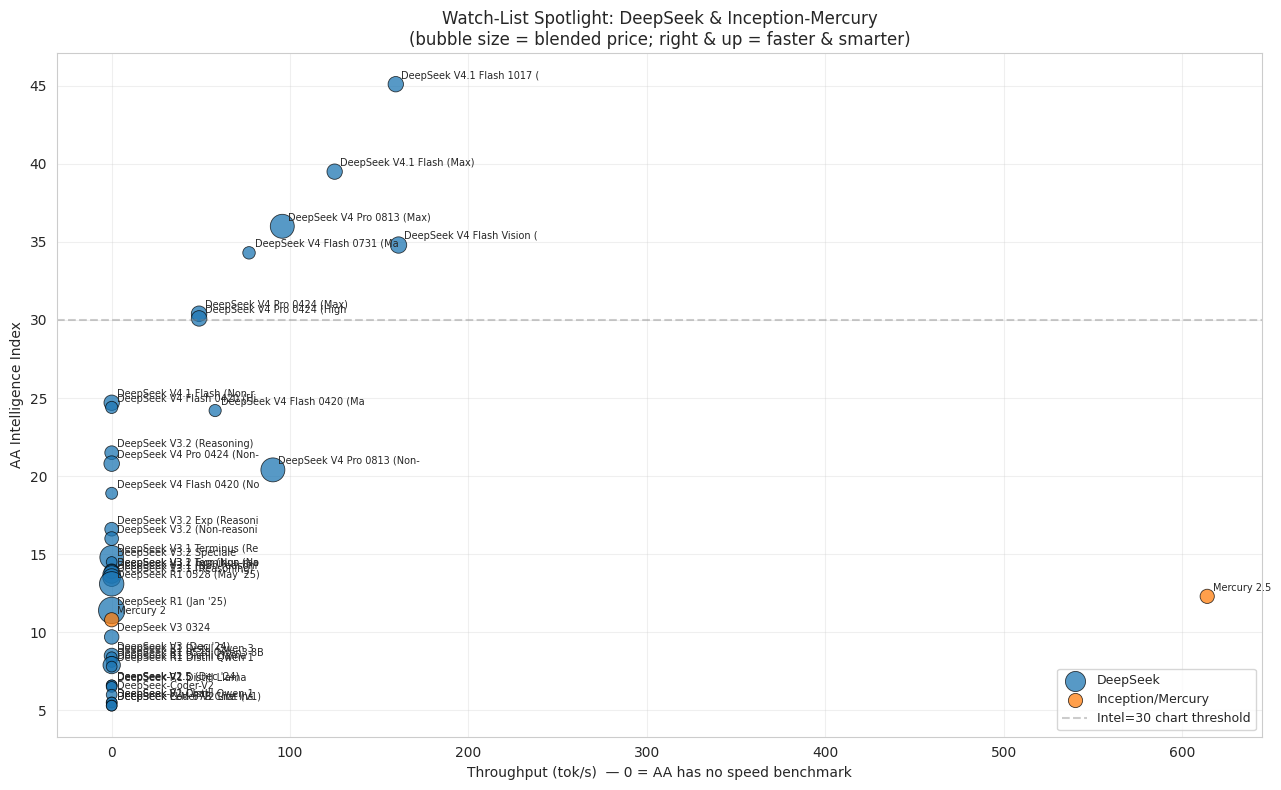


── STATUS OF REQUESTED MODELS ──
  ✅ DeepSeek V4.1 Flash    -> AA 'DeepSeek V4.1 Flash 1017 (Max)' | Intel=45.1 | Tput=159.264 | Price=$0.525/M
  ✅ DeepSeek V4 Pro        -> AA 'DeepSeek V4 Pro 0813 (Max)' | Intel=36.0 | Tput=95.645 | Price=$1.980/M
  ❌ DeepSeek V4.1 Pro      -> NOT FOUND (does not exist on OpenRouter or AA)


In [5]:
# ============================================================================
# 2.3 WATCH-LIST SPOTLIGHT: DeepSeek / Inception-Mercury — always visible
# ============================================================================
# The efficiency charts (3.1-3.6) show only the TOP-N by score, so a specific
# model the user cares about can fall below the cutoff and "disappear".
# This cell ALWAYS surfaces every DeepSeek and Inception/Mercury model with its
# real AA data + a dedicated plot, independent of rank or the Intel>30 filter.
#
# Naming note (verified against both catalogs 2026-10-16):
#   - "DeepSeek V4.1 Flash"  = deepseek/deepseek-v4.1-flash  (AA intel 39.5)  EXISTS
#   - "DeepSeek V4 Pro"      = deepseek/deepseek-v4-pro-0813 (AA intel 36.0)  EXISTS
#   - "DeepSeek V4.1 Pro"    = DOES NOT EXIST on OpenRouter or AA (no such model)
# ============================================================================

import re as _sre
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

# Rebuild from df_orig (raw AA data) so this cell works even if the appendix
# cells have overwritten the `df` variable with resume-benchmark data.
_src = df_orig.copy() if 'df_orig' in globals() else df.copy()
if 'Model' not in _src.columns and 'name' in _src.columns:
    _src = _src.rename(columns={'name': 'Model'})

# Recompute the derived columns this cell needs (same logic as the data-load cell)
_src['AA_Intelligence_Index'] = pd.to_numeric(
    _src.get('evaluations_artificial_analysis_intelligence_index'), errors='coerce')
_src['Price_Blended_USD_per_1M'] = pd.to_numeric(
    _src.get('pricing_price_1m_blended_3_to_1'), errors='coerce').fillna(0)
if 'evaluations_ifbench' in _src.columns:
    _src['AA_Hallucination_Rate'] = 1 - pd.to_numeric(_src['evaluations_ifbench'], errors='coerce')
    if 'evaluations_hle' in _src.columns:
        _src['AA_Hallucination_Rate'] = _src['AA_Hallucination_Rate'].fillna(
            1 - pd.to_numeric(_src['evaluations_hle'], errors='coerce'))
else:
    _src['AA_Hallucination_Rate'] = np.nan

# Pull every watch-list model
_watch_pat = _sre.compile(r'deepseek|inception|mercury', _sre.I)
_spot = _src[_src['Model'].astype(str).str.contains(_watch_pat, na=False)].copy()

if _spot.empty:
    print("No DeepSeek / Inception / Mercury models found in the AA data.")
else:
    # Real throughput: AA returns 0 for un-benchmarked rows -> treat as NaN
    _spot['Tput'] = pd.to_numeric(_spot.get('median_output_tokens_per_second'), errors='coerce')
    _spot['Tput'] = _spot['Tput'].where(_spot['Tput'] > 0, np.nan)
    _spot['Intel'] = pd.to_numeric(_spot['AA_Intelligence_Index'], errors='coerce')
    _spot['Price'] = pd.to_numeric(_spot['Price_Blended_USD_per_1M'], errors='coerce')
    _spot['Hall'] = pd.to_numeric(_spot.get('AA_Hallucination_Rate'), errors='coerce')
    _spot['Reliab'] = (1 - _spot['Hall']).clip(lower=0.0)

    # Multiplicative efficiency (same formula as 3.4) — NaN if no speed data
    _spot['Eff_Mult'] = (
        np.sqrt(_spot['Tput'].clip(lower=0.01)) * _spot['Intel'] * _spot['Reliab']
    ) / _spot['Price']

    # Chart eligibility: Intel>30 AND price>0 AND has speed data
    _spot['In_Charts'] = (
        (_spot['Intel'] > 30) & (_spot['Price'] > 0) & _spot['Tput'].notna()
    )

    _spot = _spot.sort_values('Intel', ascending=False)

    print("=" * 118)
    print("WATCH-LIST SPOTLIGHT — DeepSeek / Inception-Mercury (all rows, real AA data)")
    print("=" * 118)
    print(f"{'Model':<40} {'Intel':>6} {'Tput':>8} {'Price':>8} {'Reliab':>8} {'Eff':>10}  In charts?")
    print("-" * 118)
    for _, r in _spot.iterrows():
        tput_s = f"{r['Tput']:.1f}" if pd.notna(r['Tput']) else "n/a"
        eff_s = f"{r['Eff_Mult']:.1f}" if pd.notna(r['Eff_Mult']) else "n/a"
        rel_s = f"{r['Reliab']:.1%}" if pd.notna(r['Reliab']) else "n/a"
        why = "YES" if r['In_Charts'] else (
            "no (Intel<=30)" if not (r['Intel'] > 30) else
            ("no (price<=0)" if not (r['Price'] > 0) else "no (no speed data)")
        )
        print(f"{r['Model']:<40} {r['Intel']:>6.1f} {tput_s:>8} {r['Price']:>8.3f} {rel_s:>8} {eff_s:>10}  {why}")

    # ── Dedicated plot: Intel vs Throughput, bubble = price, color = family ──
    _plot = _spot.dropna(subset=['Intel']).copy()
    if not _plot.empty:
        def _fam(n):
            n = str(n).lower()
            if 'deepseek' in n: return 'DeepSeek'
            if 'mercury' in n or 'inception' in n: return 'Inception/Mercury'
            return 'Other'
        _plot['Family'] = _plot['Model'].map(_fam)

        fig, ax = plt.subplots(figsize=(13, 8))
        for fam, g in _plot.groupby('Family'):
            x = g['Tput'].fillna(0)  # NaN speed -> park at 0 (left edge)
            ax.scatter(x, g['Intel'],
                       s=(g['Price'].fillna(0.5) * 120) + 60,
                       alpha=0.75, label=fam, edgecolors='black', linewidth=0.6)
            for _, r in g.iterrows():
                short = str(r['Model'])[:26]
                ax.annotate(short, (r['Tput'] if pd.notna(r['Tput']) else 0, r['Intel']),
                            xytext=(4, 4), textcoords='offset points', fontsize=7)

        ax.set_xlabel('Throughput (tok/s)  — 0 = AA has no speed benchmark')
        ax.set_ylabel('AA Intelligence Index')
        ax.set_title('Watch-List Spotlight: DeepSeek & Inception-Mercury\n(bubble size = blended price; right & up = faster & smarter)')
        ax.axhline(30, color='gray', ls='--', alpha=0.4, label='Intel=30 chart threshold')
        ax.grid(alpha=0.3)
        ax.legend(loc='lower right', fontsize=9)
        plt.tight_layout()
        plt.show()

    # ── Explicit status of the models the user asked about ──
    print("\n── STATUS OF REQUESTED MODELS ──")
    for want in ['DeepSeek V4.1 Flash', 'DeepSeek V4 Pro', 'DeepSeek V4.1 Pro']:
        hit = _spot[_spot['Model'].astype(str).str.contains(_sre.escape(want), case=False, na=False)]
        if len(hit):
            r = hit.iloc[0]
            print(f"  ✅ {want:<22} -> AA '{r['Model']}' | Intel={r['Intel']:.1f} | "
                  f"Tput={r['Tput'] if pd.notna(r['Tput']) else 'n/a'} | Price=${r['Price']:.3f}/M")
        else:
            print(f"  ❌ {want:<22} -> NOT FOUND (does not exist on OpenRouter or AA)")

## 3. Filter Models by Intelligence Threshold
Filter the dataset to include only models with an intelligence score above 35.

In [6]:
# Standard Model Filtering for Visualization
intelligence_threshold = 30
df_filtered = df[(df['AA_Intelligence_Index'] > intelligence_threshold) & (df['Price_Blended_USD_per_1M'] > 0)].copy()

# compute cost index if missing
if 'Cost_to_Run_Index' not in df_filtered.columns:
    df_filtered['Cost_to_Run_Index'] = df_filtered['AA_Intelligence_Index'] * df_filtered['Price_Blended_USD_per_1M']

# Ensure we have the top models including o3, gemini 3.1, and the requested qwen 3.5
# qwen_search = df_filtered[df_filtered['Model'].str.contains('Qwen 3.5|Qwen3.5', case=False, na=False)]
# print(f"Found {len(qwen_search)} Qwen 3.5 models")

# Sort and take top performers
df_filtered = df_filtered.sort_values('AA_Intelligence_Index', ascending=False).head(40)



print(f"Dataset filtered to Top {len(df_filtered)} models with Intelligence > {intelligence_threshold}.")
print(df_filtered[['Model', 'AA_Intelligence_Index', 'Price_Blended_USD_per_1M']].head(10))

Dataset filtered to Top 40 models with Intelligence > 30.
                                         Model  AA_Intelligence_Index  \
0      Claude Opus 5.5 (Max, Default Fallback)                   57.6   
1    Claude Sonnet 5.5 (Max, Default Fallback)                   56.0   
2    Claude Opus 5.5 (Xhigh, Default Fallback)                   56.0   
4                                Kimi K3.1 Pro                   55.1   
5     Claude Opus 5.5 (High, Default Fallback)                   53.6   
6     Claude Fable 5.1 (Max, Default Fallback)                   53.4   
7   Claude Fable 5.1 (Xhigh, Default Fallback)                   53.2   
8                            GPT-6 Astra (Max)                   52.7   
9                        Gemini 4 Argon (High)                   52.6   
10                           Muse Wonder (Max)                   52.4   

    Price_Blended_USD_per_1M  
0                        8.0  
1                        4.0  
2                        8.0  
4             

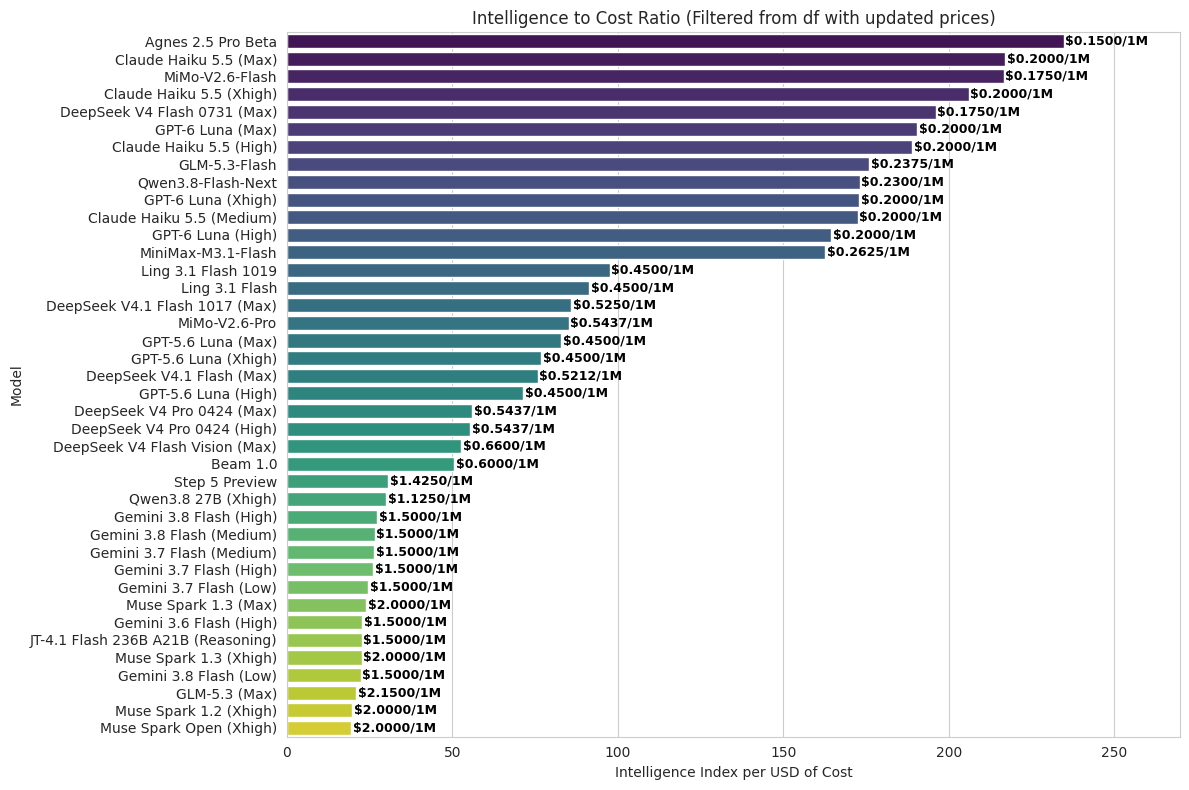

Chart shows 40 models with Intel > 30
  ✅ MiniMax-M3: Intel=42.7, Price=$0.2625, Ratio=162.7

Top 10 by Intel/Cost ratio:
                       Model  AA_Intelligence_Index  Price_Blended_USD_per_1M  Intelligence_to_Cost_Ratio
          Agnes 2.5 Pro Beta                   35.2                    0.1500                  234.666667
      Claude Haiku 5.5 (Max)                   43.4                    0.2000                  217.000000
             MiMo-V2.6-Flash                   37.9                    0.1750                  216.571429
    Claude Haiku 5.5 (Xhigh)                   41.2                    0.2000                  206.000000
DeepSeek V4 Flash 0731 (Max)                   34.3                    0.1750                  196.000000
            GPT-6 Luna (Max)                   38.1                    0.2000                  190.500000
     Claude Haiku 5.5 (High)                   37.8                    0.2000                  189.000000
               GLM-5.3-Flash  

In [7]:
# ## 3.1 Intelligence to Cost Ratio
# Re-filter directly from df (which has updated prices) so price fallbacks are included
INTEL_THRESHOLD = 30
df_plot_31 = df[(df['AA_Intelligence_Index'] > INTEL_THRESHOLD) & (df['Price_Blended_USD_per_1M'] > 0)].copy()
df_plot_31['Intelligence_to_Cost_Ratio'] = (
    df_plot_31['AA_Intelligence_Index'] / df_plot_31['Price_Blended_USD_per_1M']
)
df_plot_31 = df_plot_31.sort_values('Intelligence_to_Cost_Ratio', ascending=False).head(40)

plt.figure(figsize=(12, 8))
ax = sns.barplot(
    x='Intelligence_to_Cost_Ratio',
    y='Model',
    data=df_plot_31,
    palette='viridis'
)

# Add price labels to each bar
for i, (p, price) in enumerate(zip(ax.patches, df_plot_31['Price_Blended_USD_per_1M'])):
    ax.text(
        p.get_width() + 0.5, 
        p.get_y() + p.get_height()/2, 
        f'${price:.4f}/1M', 
        va='center', 
        fontsize=9, 
        fontweight='bold',
        color='black'
    )

plt.title('Intelligence to Cost Ratio (Filtered from df with updated prices)')
plt.xlabel('Intelligence Index per USD of Cost')
plt.ylabel('Model')
plt.xlim(0, df_plot_31['Intelligence_to_Cost_Ratio'].max() * 1.15)
plt.tight_layout()
plt.show()

print(f"Chart shows {len(df_plot_31)} models with Intel > {INTEL_THRESHOLD}")

# Quick sanity check: verify MiniMax-M3 is in the chart
m3 = df_plot_31[df_plot_31['Model'].str.contains('MiniMax-M3', case=False, na=False)]
if len(m3) > 0:
    r = m3.iloc[0]
    print(f"  ✅ MiniMax-M3: Intel={r['AA_Intelligence_Index']:.1f}, Price=${r['Price_Blended_USD_per_1M']:.4f}, Ratio={r['Intelligence_to_Cost_Ratio']:.1f}")
else:
    print("  ❌ MiniMax-M3 NOT in chart — checking df...")
    m3d = df[df['Model'].str.contains('MiniMax-M3', case=False, na=False)]
    if len(m3d) > 0:
        r = m3d.iloc[0]
        intel_ok = r['AA_Intelligence_Index'] > INTEL_THRESHOLD
        price_ok = r['Price_Blended_USD_per_1M'] > 0
        print(f"     In df: Intel={r['AA_Intelligence_Index']:.1f} (>30? {intel_ok}), Price=${r['Price_Blended_USD_per_1M']:.4f} (>0? {price_ok})")

# Also show notable models that would rank high
print(f"\nTop 10 by Intel/Cost ratio:")
print(df_plot_31[['Model','AA_Intelligence_Index','Price_Blended_USD_per_1M','Intelligence_to_Cost_Ratio']].head(10).to_string(index=False))

In [8]:
# ## 3.2 Ratio with Intelligence Exponent
# Reward higher intelligence by raising the index to the 2nd power before
# dividing by cost (Intel^2 / Cost). This makes increases at the top end count
# for more. (Note: earlier drafts used 1.5 — the code below uses squared.)

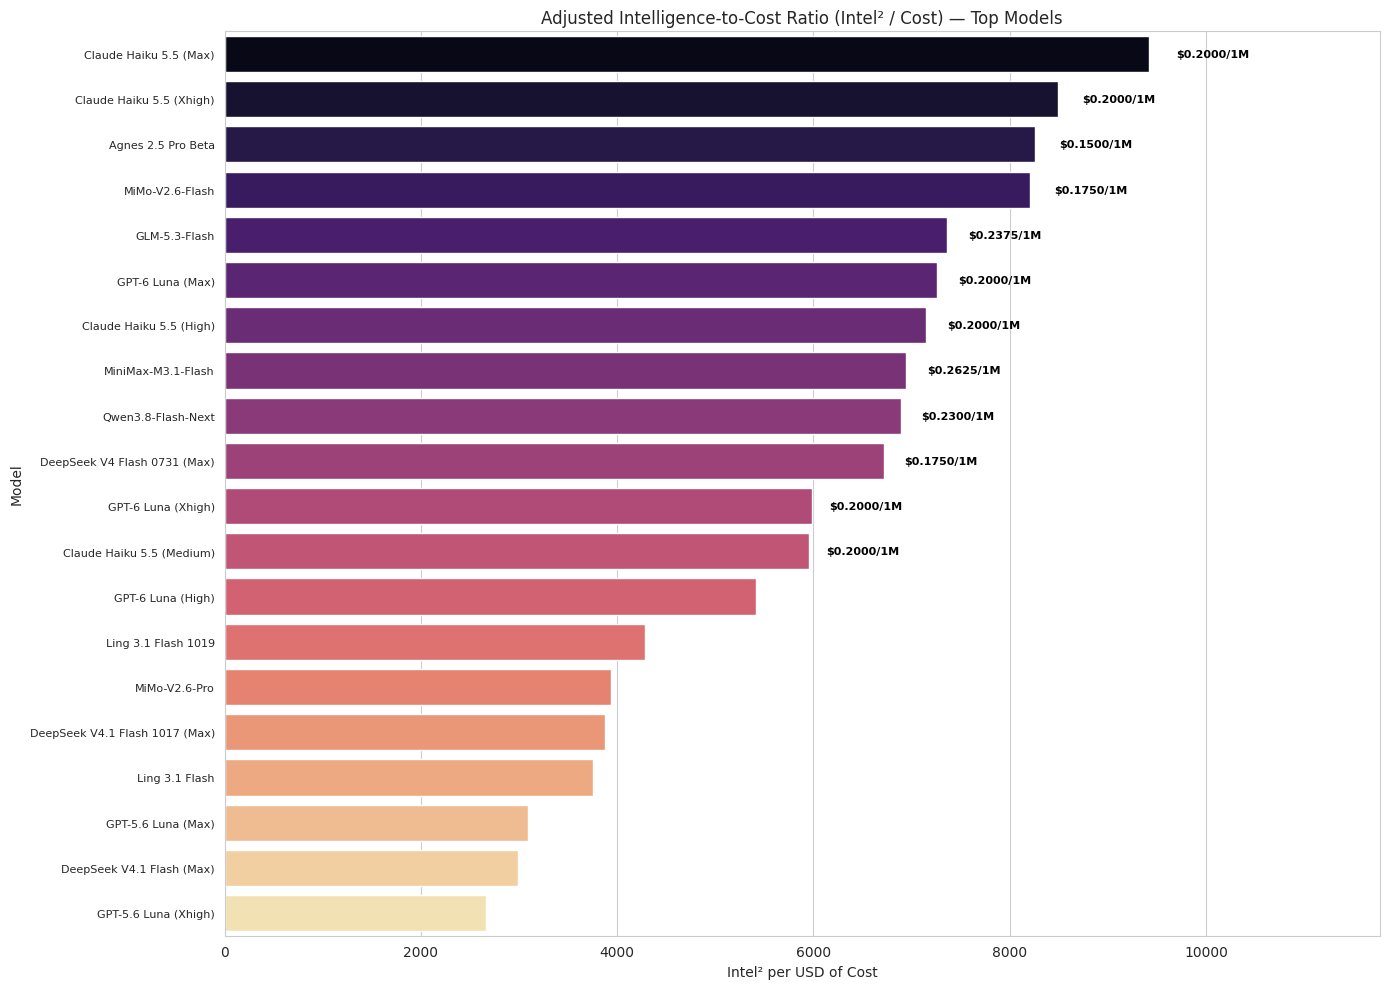

MiniMax-M3 in chart: ✅
  Intel²/Cost ratio = 6945.9


In [9]:
# ## 3.2 Ratio with Intelligence Exponent (Intel^2 / Cost)
# Re-filter from df to pick up updated prices
df_plot_32 = df[(df['AA_Intelligence_Index'] > 30) & (df['Price_Blended_USD_per_1M'] > 0)].copy()
df_plot_32['Intel_Adjusted_Ratio'] = (
    df_plot_32['AA_Intelligence_Index'] ** 2
) / df_plot_32['Price_Blended_USD_per_1M']
df_plot_32 = df_plot_32.sort_values('Intel_Adjusted_Ratio', ascending=False)

# Plot only the top N
TOP_N = 20
df_plot = df_plot_32.head(TOP_N).copy()

# Dynamic figure height so labels fit
fig_h = max(6, 0.35 * len(df_plot) + 3)
fig, ax = plt.subplots(figsize=(14, fig_h))

sns.barplot(
    x='Intel_Adjusted_Ratio',
    y='Model',
    data=df_plot,
    palette='magma',
    ax=ax
)

# Add price labels
LABEL_TOP_K = 12
for i, p in enumerate(ax.patches):
    if i >= LABEL_TOP_K:
        break
    price = df_plot.iloc[i]['Price_Blended_USD_per_1M']
    ax.text(
        p.get_width() + p.get_width() * 0.03,
        p.get_y() + p.get_height() / 2,
        f'${price:.4f}/1M',
        va='center',
        fontsize=8,
        fontweight='bold',
        color='black'
    )

ax.set_title('Adjusted Intelligence-to-Cost Ratio (Intel² / Cost) — Top Models')
ax.set_xlabel('Intel² per USD of Cost')
ax.set_ylabel('Model')
ax.tick_params(axis='y', labelsize=8)
xmax = float(df_plot['Intel_Adjusted_Ratio'].max())
ax.set_xlim(0, xmax * 1.25 if xmax > 0 else 1)
fig.tight_layout()
plt.show()

# Verify MiniMax-M3 presence
m3 = df_plot_32[df_plot_32['Model'].str.contains('MiniMax-M3', case=False, na=False)]
print(f"MiniMax-M3 in chart: {'✅' if len(m3) > 0 else '❌'}")
if len(m3) > 0:
    r = m3.iloc[0]
    print(f"  Intel²/Cost ratio = {r['Intel_Adjusted_Ratio']:.1f}")

Throughput: 122 with data (1 family-imputed), 3 still missing (kept as NaN)
Excluded 3 models with no throughput data (AA never benchmarked their speed).


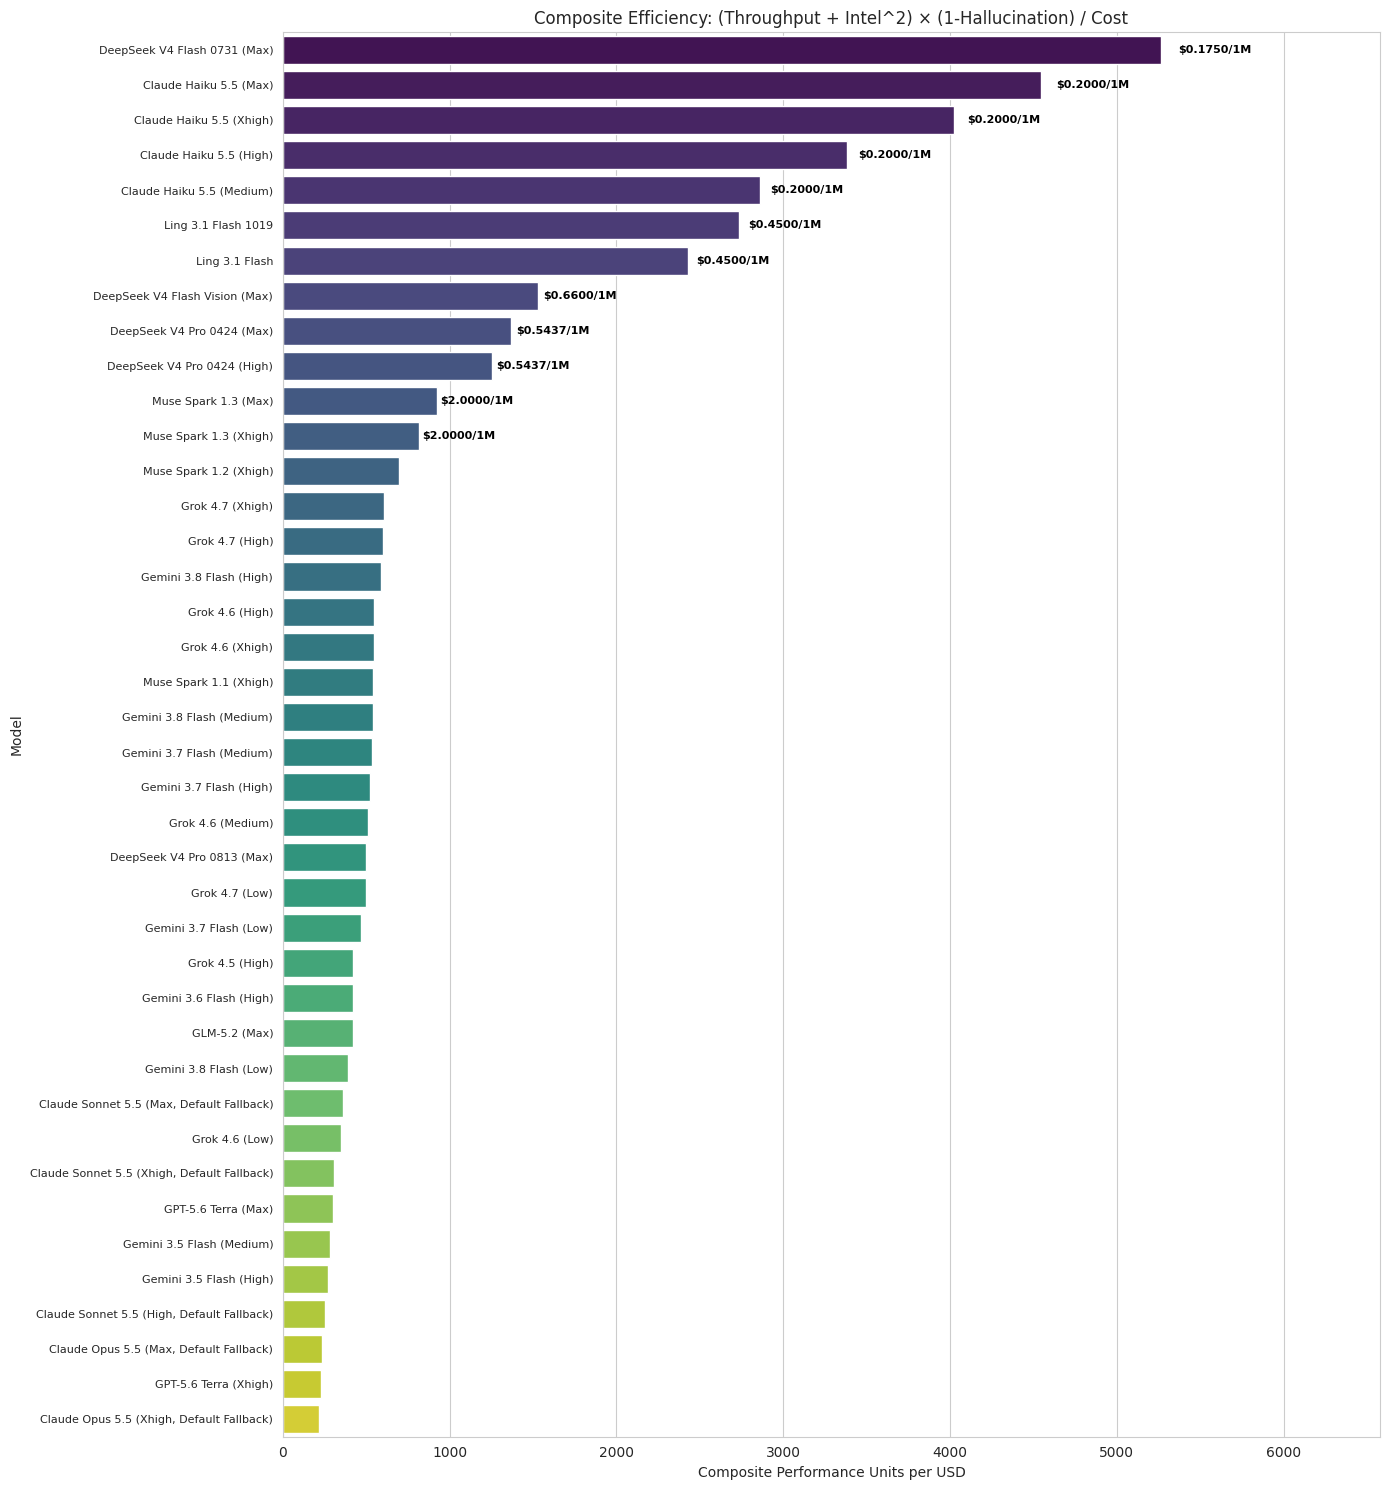

Top Models by Composite Efficiency (Intel > 30):
                         Model  Composite_Efficiency  Throughput  AA_Intelligence_Index  Intel_Power  AA_Hallucination_Rate  Price_Blended_USD_per_1M
  DeepSeek V4 Flash 0731 (Max)           5262.465306      77.000                   34.3      1176.49                    NaN                   0.17500
        Claude Haiku 5.5 (Max)           4546.649480     241.583                   43.4      1883.56                    NaN                   0.20000
      Claude Haiku 5.5 (Xhigh)           4021.216255     182.111                   41.2      1697.44                    NaN                   0.20000
       Claude Haiku 5.5 (High)           3382.804789     152.312                   37.8      1428.84                    NaN                   0.20000
     Claude Haiku 5.5 (Medium)           2862.294452     147.611                   34.5      1190.25                    NaN                   0.20000
           Ling 3.1 Flash 1019           2734.19254

In [10]:
# ## 3.3 Throughput-weighted Intelligence Efficiency (Additive)
# Composite: (Throughput + Intel^2) * (1 - hallucination) / blended_cost
# Re-filter from df to include all price-fallback models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
cost_col = 'Price_Blended_USD_per_1M'

# Work on ALL rows first (imputation population must match 3.4, so the same
# model gets the SAME family-median imputed values in both sections), then
# apply the Intel>30 / price>0 filter at the end.
_df = df.copy()

# Ensure Model column
if 'Model' not in _df.columns:
    if 'name' in _df.columns:
        _df = _df.rename(columns={'name': 'Model'})
    elif 'model' in _df.columns:
        _df = _df.rename(columns={'model': 'Model'})

# Coerce numeric
_df['AA_Intelligence_Index'] = pd.to_numeric(_df['AA_Intelligence_Index'], errors='coerce')
if 'AA_Hallucination_Rate' not in _df.columns:
    if 'evaluations_ifbench' in _df.columns:
        _df['AA_Hallucination_Rate'] = 1 - pd.to_numeric(_df['evaluations_ifbench'], errors='coerce')
    else:
        _df['AA_Hallucination_Rate'] = np.nan
# Keep missing hallucination data as NaN (family-imputed below), don't fake 0.1
_df[cost_col] = pd.to_numeric(_df[cost_col], errors='coerce')

# Throughput
# AA returns a literal 0 for models it never speed-benchmarked — treat <=0 as
# MISSING, not real zero speed (same fix as section 3.4).
thr = _df.get('median_output_tokens_per_second', pd.Series(np.nan, index=_df.index))
_df['Throughput_raw'] = pd.to_numeric(thr, errors='coerce')
_df['Throughput'] = _df['Throughput_raw'].where(_df['Throughput_raw'] > 0, np.nan)
_df['Throughput_Imputed'] = False

# ── Family-level imputation (same key AND same population as 3.4) ──
import re as _re
_TPUT_SUFFIX = _re.compile(r'\s*\([^)]*\)\s*$')

def _family_key(name):
    if not isinstance(name, str):
        return ''
    base = _TPUT_SUFFIX.sub('', name).strip().lower()
    base = _re.sub(r'\s*\d{4}\s*$', '', base)
    base = _re.sub(r'\b(preview|beta|adaptive)\b', '', base).strip()
    toks = [t for t in base.split() if not _re.match(r'^\d+\.\d+$', t)]
    return ' '.join(toks[:3])

_family_tput = _df.groupby(_df['Model'].map(_family_key))['Throughput'].median()
_missing_mask = _df['Throughput'].isna()
_family_hit = _df['Model'].map(_family_key).map(_family_tput)
_imp_mask = _missing_mask & _family_hit.notna()
_df.loc[_imp_mask, 'Throughput'] = _family_hit[_imp_mask]
_df.loc[_imp_mask, 'Throughput_Imputed'] = True

_df['Intel_Power'] = _df['AA_Intelligence_Index'] ** 2

# Reliability: NaN stays NaN, family-imputed (no fake 0.1 / 100% halluc)
_df['Reliability_Factor'] = (1 - _df['AA_Hallucination_Rate']).clip(lower=0.0)
_df['Reliability_Imputed'] = False
_rel_missing = _df['Reliability_Factor'].isna()
_rel_family = _df.groupby(_df['Model'].map(_family_key))['Reliability_Factor'].median()
_rel_hit = _df['Model'].map(_family_key).map(_rel_family)
_rel_imp = _rel_missing & _rel_hit.notna()
_df.loc[_rel_imp, 'Reliability_Factor'] = _rel_hit[_rel_imp]
_df.loc[_rel_imp, 'Reliability_Imputed'] = True

# ── NOW apply the core filter (consistent with 3.4) ──
_df = _df[(_df[cost_col] > 0) & (_df['AA_Intelligence_Index'] > 30)].copy()

print(f"Throughput: {int(_df['Throughput'].notna().sum())} with data "
      f"({int(_df['Throughput_Imputed'].sum())} family-imputed), "
      f"{int(_df['Throughput'].isna().sum())} still missing (kept as NaN)")

# Composite — NaN throughput yields NaN score (row excluded from chart)
_df['Composite_Efficiency'] = (
    (_df['Throughput'] + _df['Intel_Power']) * _df['Reliability_Factor']
) / _df[cost_col]

n_no_tput = int(_df['Throughput'].isna().sum())
if n_no_tput:
    print(f"Excluded {n_no_tput} models with no throughput data (AA never benchmarked their speed).")

_df = _df.sort_values('Composite_Efficiency', ascending=False)

TOP_N = 40
df_plot = _df[_df['Throughput'].notna()].head(TOP_N).copy()

# Plot
fig_h = max(6, 0.30 * len(df_plot) + 3)
fig, ax = plt.subplots(figsize=(14, fig_h))

sns.barplot(
    x='Composite_Efficiency',
    y='Model',
    data=df_plot,
    palette='viridis',
    ax=ax,
)

LABEL_TOP_K = 12
for i, (p, intel_p, eff, price) in enumerate(
    zip(ax.patches, df_plot['Intel_Power'], df_plot['Composite_Efficiency'], df_plot[cost_col])
):
    if i >= LABEL_TOP_K:
        break
    ax.text(
        p.get_width() + p.get_width() * 0.02,
        p.get_y() + p.get_height() / 2,
        f'${price:.4f}/1M',
        va='center',
        fontsize=8,
        fontweight='bold',
        color='black',
    )

ax.set_title('Composite Efficiency: (Throughput + Intel^2) × (1-Hallucination) / Cost')
ax.set_xlabel('Composite Performance Units per USD')
ax.set_ylabel('Model')
ax.tick_params(axis='y', labelsize=8)
ax.set_xlim(0, float(df_plot['Composite_Efficiency'].max()) * 1.25)

plt.tight_layout()
plt.show()

print('Top Models by Composite Efficiency (Intel > 30):')
cols = ['Model','Composite_Efficiency','Throughput','AA_Intelligence_Index','Intel_Power','AA_Hallucination_Rate',cost_col]
print(_df[_df['Throughput'].notna()][cols].head(15).to_string(index=False))

## 3.4 Multiplicative Intelligence Efficiency (sqrt(Throughput) × Intel)
Combine sqrt of token throughput with raw intelligence score, multiply them,
then divide by cost. Penalize for Hallucination Rate by using (1 - Hallucination_Rate) as a multiplier.

Formula: (sqrt(Throughput) × Intel) × (1 - Hallucination) / Cost

This differs from 3.3 by:
- Using sqrt(Throughput) instead of raw Throughput (diminishing returns on speed)
- Using raw Intel instead of Intel^2 (linear intelligence contribution)
- Multiplying instead of adding (both must be good to score well)

Throughput: 319 with data (85 family-imputed), 390 still missing (kept as NaN)
Reliability: 18 family-imputed, 80 still missing (kept as NaN)
Excluded 3 models with no throughput data (AA never benchmarked their speed).


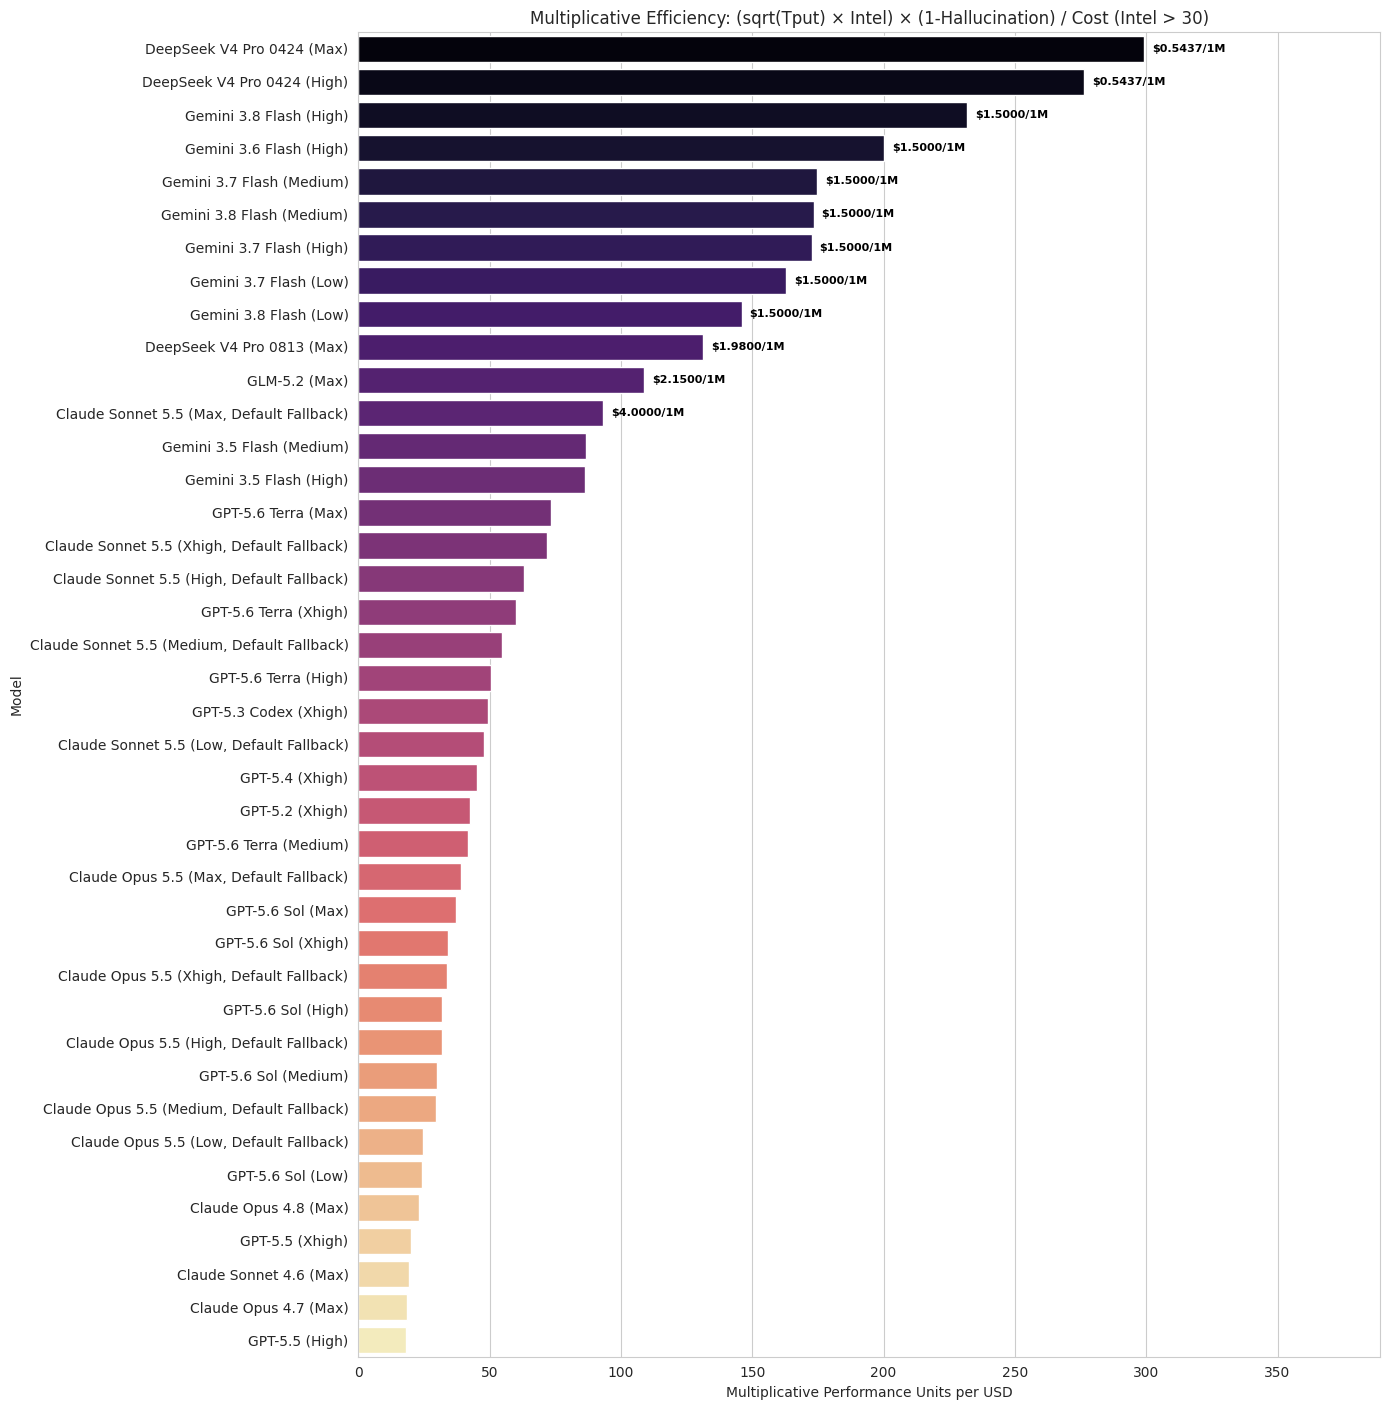

Top Models by Multiplicative Efficiency (Intel > 30):
                                    Model  Composite_Efficiency_Mult  Throughput_Sqrt  AA_Intelligence_Index  AA_Hallucination_Rate  Price_Blended_USD_per_1M
               DeepSeek V4 Pro 0424 (Max)                 299.241160         7.000000                   30.4               0.235374                   0.54375
              DeepSeek V4 Pro 0424 (High)                 276.254406         7.000000                   30.1               0.287075                   0.54375
                  Gemini 3.8 Flash (High)                 231.767400        11.266943                   40.9                    NaN                   1.50000
                  Gemini 3.6 Flash (High)                 200.153023        11.704700                   34.0                    NaN                   1.50000
                Gemini 3.7 Flash (Medium)                 174.768638         8.774964                   39.6                    NaN                   1.5000

In [11]:
# ## 3.4 Multiplicative Intelligence Efficiency (sqrt(Throughput) × Intel)
# Formula: (sqrt(Throughput) * Intel) * (1 - Hallucination) / Cost
# Key differences from 3.3:
#   - sqrt(Throughput) instead of raw (linear speed contribution)
#   - Intel instead of Intel^2  (linear intelligence contribution)
#   - Multiply instead of add (both dimensions must be strong)

# Always rebuild df_comp safely from df and compute missing Throughput.
df_comp = df.copy()

# Ensure Model column
if 'Model' not in df_comp.columns and 'name' in df_comp.columns:
    df_comp = df_comp.rename(columns={'name': 'Model'})

# Ensure intelligence
if 'AA_Intelligence_Index' not in df_comp.columns:
    df_comp['AA_Intelligence_Index'] = df_comp.get(
        'evaluations_artificial_analysis_intelligence_index',
        df_comp.get('evaluations_artificial_analysis_intelligence', np.nan),
    )

# Ensure hallucination proxy (keep missing as NaN — imputed below from family)
if 'AA_Hallucination_Rate' not in df_comp.columns:
    if 'evaluations_ifbench' in df_comp.columns:
        df_comp['AA_Hallucination_Rate'] = 1 - pd.to_numeric(df_comp['evaluations_ifbench'], errors='coerce')
    else:
        df_comp['AA_Hallucination_Rate'] = 0.1

# Ensure blended cost
cost_col = 'Price_Blended_USD_per_1M'
if cost_col not in df_comp.columns:
    pin = df_comp.get('Price_Input_1M', df_comp.get('pricing_price_1m_input_tokens', np.nan))
    pout = df_comp.get('Price_Output_1M', df_comp.get('pricing_price_1m_output_tokens', np.nan))
    pin = pd.to_numeric(pin, errors='coerce')
    pout = pd.to_numeric(pout, errors='coerce')
    derived = (pin * 3 + pout) / 4

    api_blended = pd.to_numeric(df_comp.get('pricing_price_1m_blended_3_to_1', np.nan), errors='coerce')
    df_comp[cost_col] = derived.where((derived > 0) & (~derived.isna()), api_blended)

# Coerce types
for c in ['AA_Intelligence_Index', 'AA_Hallucination_Rate', cost_col]:
    if c in df_comp.columns:
        df_comp[c] = pd.to_numeric(df_comp[c], errors='coerce')

# Ensure Throughput exists
# AA returns a literal 0 for models it never speed-benchmarked (mostly effort/
# reasoning variant rows), so treat <=0 as MISSING, not as real zero speed.
median_thr = df_comp.get('median_output_tokens_per_second', pd.Series(np.nan, index=df_comp.index))
df_comp['Throughput_raw'] = pd.to_numeric(median_thr, errors='coerce')
df_comp['Throughput'] = df_comp['Throughput_raw'].where(df_comp['Throughput_raw'] > 0, np.nan)
df_comp['Throughput_Imputed'] = False

# ── Family-level imputation ──
# Group variants into a base family (e.g. "Gemini 3.8 Flash (Medium)" ->
# "gemini flash") and fill missing throughput with the family median.
# Rows with no family speed data anywhere in the API stay NaN (true missing).
import re as _re
_TPUT_SUFFIX = _re.compile(r'\s*\([^)]*\)\s*$')

def _family_key(name):
    if not isinstance(name, str):
        return ''
    base = _TPUT_SUFFIX.sub('', name).strip().lower()          # drop (Max)/(Xhigh)/...
    base = _re.sub(r'\s*\d{4}\s*$', '', base)                  # drop date suffixes
    base = _re.sub(r'\b(preview|beta|adaptive)\b', '', base).strip()
    toks = [t for t in base.split() if not _re.match(r'^\d+\.\d+$', t)]  # drop minor versions
    return ' '.join(toks[:3])

_family_tput = df_comp.groupby(df_comp['Model'].map(_family_key))['Throughput'].median()
_missing_mask = df_comp['Throughput'].isna()
_family_hit = df_comp['Model'].map(_family_key).map(_family_tput)
_imp_mask = _missing_mask & _family_hit.notna()
df_comp.loc[_imp_mask, 'Throughput'] = _family_hit[_imp_mask]
df_comp.loc[_imp_mask, 'Throughput_Imputed'] = True

print(f"Throughput: {int(df_comp['Throughput'].notna().sum())} with data "
      f"({int(df_comp['Throughput_Imputed'].sum())} family-imputed), "
      f"{int(df_comp['Throughput'].isna().sum())} still missing (kept as NaN)")

# Apply core filter (consistency)
df_comp = df_comp[(df_comp[cost_col] > 0) & (df_comp['AA_Intelligence_Index'] > 30)].copy()

# If empty, stop cleanly
if df_comp.empty:
    print('No models available for 3.4 after filtering (cost>0 and Intel>30).')
else:
    # Compute reliability
    # Missing IFBench/HLE stays NaN here — imputed below from the family median
    # instead of being faked into a 100% hallucination rate.
    df_comp['Reliability_Factor'] = (1 - df_comp['AA_Hallucination_Rate']).clip(lower=0.0)

    # ── Family-level reliability imputation ──
    # Same family key as throughput: fill missing reliability with the family
    # median so models without IFBench/HLE aren't scored as Reliability 0%.
    df_comp['Reliability_Imputed'] = False
    _rel_missing = df_comp['Reliability_Factor'].isna()
    _rel_family = df_comp.groupby(df_comp['Model'].map(_family_key))['Reliability_Factor'].median()
    _rel_hit = df_comp['Model'].map(_family_key).map(_rel_family)
    _rel_imp = _rel_missing & _rel_hit.notna()
    df_comp.loc[_rel_imp, 'Reliability_Factor'] = _rel_hit[_rel_imp]
    df_comp.loc[_rel_imp, 'Reliability_Imputed'] = True

    n_rel_missing = int(df_comp['Reliability_Factor'].isna().sum())
    n_rel_imp = int(df_comp['Reliability_Imputed'].sum())
    if n_rel_imp or n_rel_missing:
        print(f"Reliability: {n_rel_imp} family-imputed, {n_rel_missing} still missing (kept as NaN)")

    # Sqrt throughput — only for rows with real/imputed speed data.
    # Rows with NaN throughput are excluded from the multiplicative ranking
    # so they are visibly absent instead of silently scored as zero speed.
    df_comp['Throughput_Sqrt'] = np.where(
        df_comp['Throughput'].notna(),
        np.sqrt(df_comp['Throughput'].clip(lower=0.01)),
        np.nan,
    )

    # Multiplicative formula: (sqrt(T) * Intel) * Reliability / Cost
    df_comp['Composite_Efficiency_Mult'] = (
        (df_comp['Throughput_Sqrt'] * df_comp['AA_Intelligence_Index']) * df_comp['Reliability_Factor']
    ) / df_comp[cost_col]

    n_no_tput = int(df_comp['Throughput'].isna().sum())
    if n_no_tput:
        print(f"Excluded {n_no_tput} models with no throughput data (AA never benchmarked their speed).")

    # Sort and take top N (NaN throughput sorts to the bottom automatically)
    df_comp = df_comp.sort_values('Composite_Efficiency_Mult', ascending=False)
    df_plot_m = df_comp[df_comp['Throughput'].notna()].head(40).copy()

    plt.figure(figsize=(14, max(6, 0.28 * len(df_plot_m) + 3)))
    ax = sns.barplot(
        x='Composite_Efficiency_Mult',
        y='Model',
        data=df_plot_m,
        palette='magma',
    )

    # Limit labels to top few
    LABEL_TOP_K = 12
    max_eff = float(df_plot_m['Composite_Efficiency_Mult'].max()) if len(df_plot_m) else 1.0
    label_x_offset = max_eff * 0.01

    for i, (p, tp_sqrt, intel, eff, price) in enumerate(zip(
        ax.patches,
        df_plot_m['Throughput_Sqrt'],
        df_plot_m['AA_Intelligence_Index'],
        df_plot_m['Composite_Efficiency_Mult'],
        df_plot_m[cost_col],
    )):
        if i >= LABEL_TOP_K:
            break
        ax.text(
            p.get_width() + label_x_offset,
            p.get_y() + p.get_height() / 2,
            f'${price:.4f}/1M',
            va='center',
            fontsize=8,
            fontweight='bold',
            color='black',
        )

    plt.title('Multiplicative Efficiency: (sqrt(Tput) × Intel) × (1-Hallucination) / Cost (Intel > 30)')
    plt.xlabel('Multiplicative Performance Units per USD')
    plt.ylabel('Model')
    plt.xlim(0, max_eff * 1.3)
    plt.tight_layout()
    plt.show()

    print('Top Models by Multiplicative Efficiency (Intel > 30):')
    cols = ['Model','Composite_Efficiency_Mult','Throughput_Sqrt','AA_Intelligence_Index','AA_Hallucination_Rate',cost_col]
    print(df_comp[df_comp['Throughput'].notna()][cols].head(15).to_string(index=False))


RANKING A - MEASURED ONLY (no imputation; every input is a real measurement)
  score = sqrt(T) * I * R / C   |  R = IFBench only (HLE never substituted)
Rows: 27  (models missing any measured input are excluded)
#  model                                        score   T t/s     I     R     $/M   price src
----------------------------------------------------------------------------------------------------------------------
1  DeepSeek V4 Pro 0424 (Max)                  299.24      49  30.4  0.76   0.544          aa
2  DeepSeek V4 Pro 0424 (High)                 276.25      49  30.1  0.71   0.544          aa
3  GLM-5.2 (Max)                               108.74      90  33.7  0.73   2.150          aa
4  Gemini 3.5 Flash (Medium)                    86.88     137  33.6  0.75   3.375          aa
5  Gemini 3.5 Flash (High)                      86.29     137  32.6  0.76   3.375          aa
6  GPT-5.6 Terra (Max)                          73.53     122  42.1  0.71   4.500          aa
7  GPT-5.6

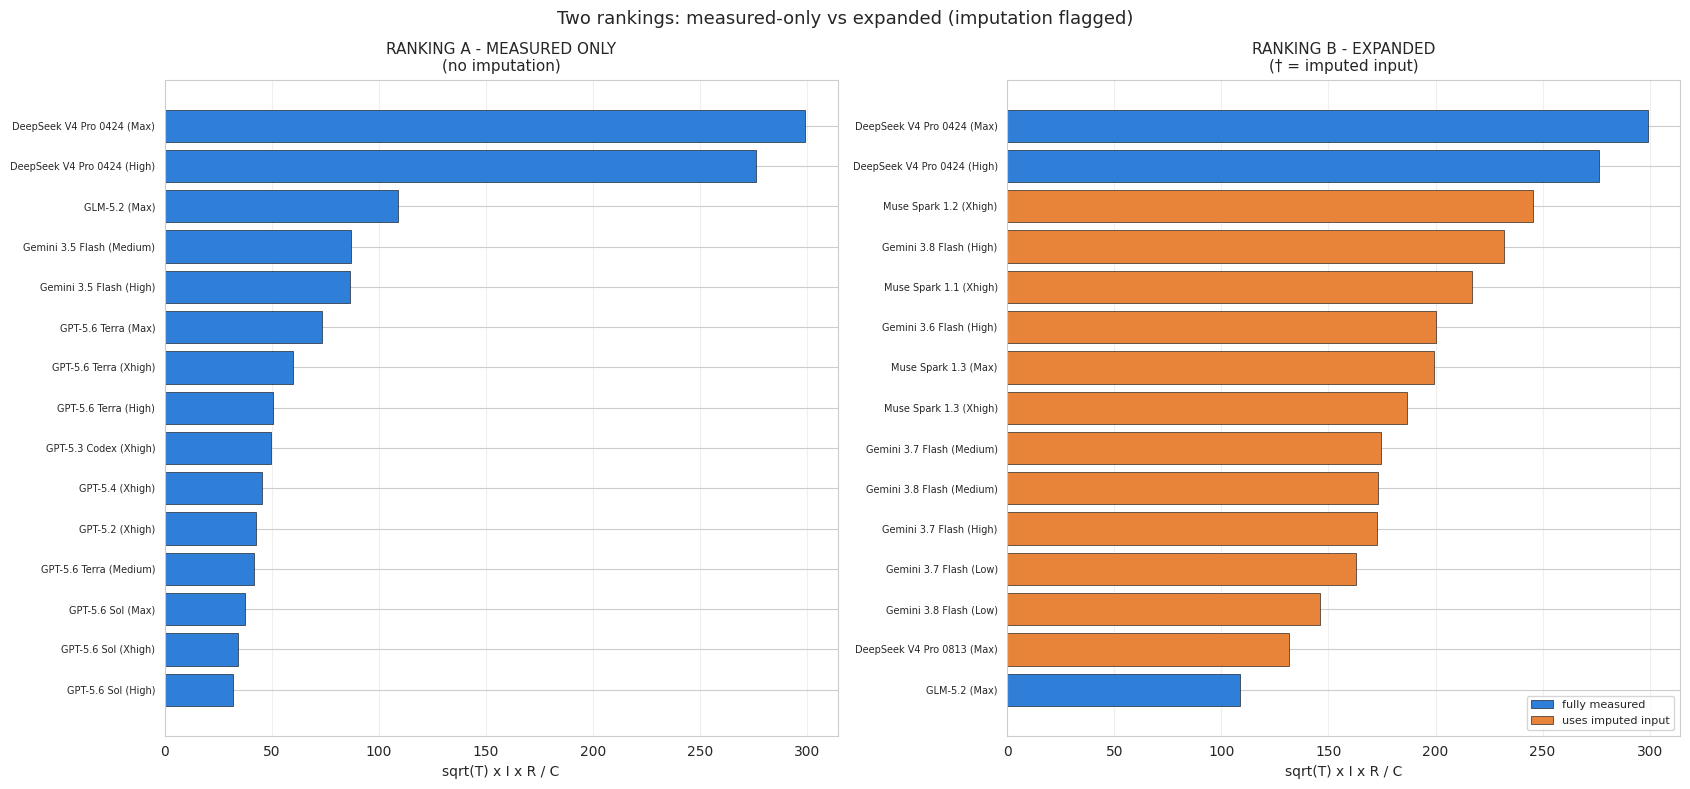


HOW TO READ THIS
  - Use RANKING A for decisions. Every input is a measurement.
  - Use RANKING B for coverage. Orange bars / † marks mean at least one
    input was filled from the family median, so the score is an estimate.
  - A model that appears high in B but absent from A is high *because of*
    imputation, not because it was measured well.
  - Reliability is IFBench only. HLE is kept in its own column and is
    never substituted, so a rank change cannot come from a benchmark swap.


In [12]:
# ============================================================================
# 3.4b TWO RANKINGS: MEASURED-ONLY vs EXPANDED (imputation visibly flagged)
# ============================================================================
# WHY TWO RANKINGS
# ----------------
# The composite score needs four inputs: intelligence, throughput, reliability,
# and price. AA does not measure all four for every model, and the notebook
# fills gaps (family-median throughput, family-median reliability, OpenRouter
# price). Those fills are reasonable, but they are NOT measurements.
#
# Mixing measured and imputed rows in one leaderboard makes it impossible to
# tell whether a model ranks well because it is good or because it was filled
# in. So we publish two rankings:
#
#   RANKING A - MEASURED ONLY
#     Every input is a real measurement: AA intelligence, AA/OpenRouter
#     throughput, IFBench reliability, and a priced endpoint. No imputation.
#     Smaller, but every number is defensible.
#
#   RANKING B - EXPANDED
#     Same formula, but rows may use family-median throughput/reliability.
#     Every imputed input is flagged per-row in *_Imputed columns and marked
#     with a dagger (†) in the printed table.
#
# Both use the SAME formula so the only difference is data provenance:
#     score = sqrt(T) * I * R / C
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

_RK_COST = 'Price_Blended_USD_per_1M'
_RK_INTEL = 'AA_Intelligence_Index'
_RK_TPUT = 'median_output_tokens_per_second'

_rk = df.copy()
if 'Model' not in _rk.columns and 'name' in _rk.columns:
    _rk = _rk.rename(columns={'name': 'Model'})

# ── Coerce the four inputs ──────────────────────────────────────────────────
_rk['_I'] = pd.to_numeric(_rk.get(_RK_INTEL), errors='coerce')
_rk['_C'] = pd.to_numeric(_rk.get(_RK_COST), errors='coerce')
_rk['_C'] = _rk['_C'].where(_rk['_C'] > 0, np.nan)

_t = pd.to_numeric(_rk.get(_RK_TPUT), errors='coerce')
_rk['_T_raw'] = _t.where(_t > 0, np.nan)          # AA 0 => missing, not zero

# Reliability: IFBench ONLY (see the data-load cell). HLE is never substituted.
if 'Reliability_IFBench' in _rk.columns:
    _rk['_R_raw'] = pd.to_numeric(_rk['Reliability_IFBench'], errors='coerce')
elif 'Reliability_Factor' in _rk.columns:
    _rk['_R_raw'] = pd.to_numeric(_rk['Reliability_Factor'], errors='coerce')
else:
    _rk['_R_raw'] = np.nan

# ── Family key for imputation (same rule as 3.3/3.4) ────────────────────────
import re as _rkre
_RK_SUFFIX = _rkre.compile(r'\s*\([^)]*\)\s*$')

def _rk_family(name):
    if not isinstance(name, str):
        return ''
    b = _RK_SUFFIX.sub('', name).strip().lower()
    b = _rkre.sub(r'\s*\d{4}\s*$', '', b)
    b = _rkre.sub(r'\b(preview|beta|adaptive)\b', '', b).strip()
    toks = [x for x in b.split() if not _rkre.match(r'^\d+\.\d+$', x)]
    return ' '.join(toks[:3])

_rk['_Family'] = _rk['Model'].map(_rk_family)

# ── RANKING A: measured only (no fills at all) ──────────────────────────────
_rk['_T_measured'] = _rk['_T_raw']
_rk['_R_measured'] = _rk['_R_raw']

_rk['Score_Measured'] = (
    np.sqrt(_rk['_T_measured']) * _rk['_I'] * _rk['_R_measured']
) / _rk['_C']
_rk['Score_Measured'] = _rk['Score_Measured'].replace([np.inf, -np.inf], np.nan)

# Same Intel > 30 convention as sections 3.1-3.4, so these rankings are
# comparable with the rest of the notebook.
_rk = _rk[_rk['_I'] > 30].copy()

df_rank_measured = _rk.dropna(
    subset=['Score_Measured', '_I', '_C', '_T_measured', '_R_measured']
).copy()
df_rank_measured = df_rank_measured.sort_values('Score_Measured', ascending=False)

# ── RANKING B: expanded (family-median fills, flagged) ──────────────────────
_rk['_T_imputed'] = False
_rk['_R_imputed'] = False

_t_med = _rk.groupby('_Family')['_T_raw'].median()
_r_med = _rk.groupby('_Family')['_R_raw'].median()

_t_fill = _rk['_Family'].map(_t_med)
_r_fill = _rk['_Family'].map(_r_med)

_t_need = _rk['_T_raw'].isna() & _t_fill.notna()
_r_need = _rk['_R_raw'].isna() & _r_fill.notna()

_rk.loc[_t_need, '_T_raw'] = _t_fill[_t_need]
_rk.loc[_t_need, '_T_imputed'] = True
_rk.loc[_r_need, '_R_raw'] = _r_fill[_r_need]
_rk.loc[_r_need, '_R_imputed'] = True

_rk['Score_Expanded'] = (
    np.sqrt(_rk['_T_raw']) * _rk['_I'] * _rk['_R_raw']
) / _rk['_C']
_rk['Score_Expanded'] = _rk['Score_Expanded'].replace([np.inf, -np.inf], np.nan)

df_rank_expanded = _rk.dropna(subset=['Score_Expanded', '_I', '_C']).copy()
df_rank_expanded['Any_Imputed'] = df_rank_expanded['_T_imputed'] | df_rank_expanded['_R_imputed']
df_rank_expanded = df_rank_expanded.sort_values('Score_Expanded', ascending=False)

# ── Print RANKING A ─────────────────────────────────────────────────────────
print('\n' + '=' * 118)
print('RANKING A - MEASURED ONLY (no imputation; every input is a real measurement)')
print('  score = sqrt(T) * I * R / C   |  R = IFBench only (HLE never substituted)')
print('=' * 118)
print(f"Rows: {len(df_rank_measured)}  (models missing any measured input are excluded)")
print(f"{'#':<3}{'model':<40}{'score':>10}{'T t/s':>8}{'I':>6}{'R':>6}{'$/M':>8}{'price src':>12}")
print('-' * 118)
for _i, (_, _r) in enumerate(df_rank_measured.head(30).iterrows(), 1):
    print(f"{_i:<3}{str(_r['Model'])[:39]:<40}{_r['Score_Measured']:>10.2f}"
          f"{_r['_T_measured']:>8.0f}{_r['_I']:>6.1f}{_r['_R_measured']:>6.2f}"
          f"{_r['_C']:>8.3f}{str(_r.get('Price_Source', '?'))[:11]:>12}")

# ── Print RANKING B ─────────────────────────────────────────────────────────
print('\n' + '=' * 118)
print('RANKING B - EXPANDED (family-median fills allowed; imputed inputs flagged with †)')
print('=' * 118)
print(f"Rows: {len(df_rank_expanded)}  |  rows using any imputed input: "
      f"{int(df_rank_expanded['Any_Imputed'].sum())}")
print(f"{'#':<3}{'model':<40}{'score':>10}{'T t/s':>8}{'I':>6}{'R':>6}{'$/M':>8}  flags")
print('-' * 118)
for _i, (_, _r) in enumerate(df_rank_expanded.head(30).iterrows(), 1):
    _flags = []
    if _r['_T_imputed']:
        _flags.append('T†')
    if _r['_R_imputed']:
        _flags.append('R†')
    _flag_s = ','.join(_flags) if _flags else '-'
    print(f"{_i:<3}{str(_r['Model'])[:39]:<40}{_r['Score_Expanded']:>10.2f}"
          f"{_r['_T_raw']:>8.0f}{_r['_I']:>6.1f}{_r['_R_raw']:>6.2f}"
          f"{_r['_C']:>8.3f}  {_flag_s}")

# ── Rank movement between the two ───────────────────────────────────────────
# Ranks must be computed inside each FULL ranking, then compared on the
# intersection. Ranking only the intersection would force identical ranks and
# hide the movement we are trying to show.
_a = df_rank_measured[['Model', 'Score_Measured']].copy()
_a['Rank_A'] = _a['Score_Measured'].rank(ascending=False, method='min')
_b = df_rank_expanded[['Model', 'Score_Expanded', 'Any_Imputed']].copy()
_b['Rank_B'] = _b['Score_Expanded'].rank(ascending=False, method='min')
_common = _a.merge(_b, on='Model', how='inner')
if len(_common):
    _common['Move'] = _common['Rank_A'] - _common['Rank_B']
    print('\n' + '-' * 118)
    print('RANK MOVEMENT (measured-only -> expanded), models present in both:')
    print(f"  compared: {len(_common)}  |  moved up: {int((_common['Move'] > 0).sum())}"
          f"  |  moved down: {int((_common['Move'] < 0).sum())}"
          f"  |  unchanged: {int((_common['Move'] == 0).sum())}")
    _movers = _common[_common['Move'] != 0].sort_values('Move', key=abs, ascending=False)
    for _, _r in _movers.head(10).iterrows():
        print(f"    {str(_r['Model'])[:44]:<46} {int(_r['Rank_A']):>3} -> {int(_r['Rank_B']):>3}"
              f"  ({_r['Move']:+.0f}){'  [imputed]' if _r['Any_Imputed'] else ''}")

# ── Plot: side-by-side top-15 ───────────────────────────────────────────────
_fig, _axes = plt.subplots(1, 2, figsize=(17, 8))
for _ax, _frame, _col, _title in [
    (_axes[0], df_rank_measured, 'Score_Measured',
     'RANKING A - MEASURED ONLY\n(no imputation)'),
    (_axes[1], df_rank_expanded, 'Score_Expanded',
     'RANKING B - EXPANDED\n(† = imputed input)'),
]:
    _top = _frame.head(15).sort_values(_col)
    _colors = []
    for _, _r in _top.iterrows():
        if _title.startswith('RANKING B') and _r.get('Any_Imputed', False):
            _colors.append('#e8833a')   # orange = uses imputed input
        else:
            _colors.append('#2f7ed8')   # blue = fully measured
    _ax.barh(np.arange(len(_top)), _top[_col], color=_colors,
             edgecolor='black', linewidth=0.4)
    _ax.set_yticks(np.arange(len(_top)))
    _ax.set_yticklabels([str(m)[:32] for m in _top['Model']], fontsize=7)
    _ax.set_xlabel('sqrt(T) x I x R / C')
    _ax.set_title(_title, fontsize=11)
    _ax.grid(axis='x', alpha=0.3)
_axes[1].legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color='#2f7ed8', ec='black', lw=.4),
    plt.Rectangle((0, 0), 1, 1, color='#e8833a', ec='black', lw=.4),
], labels=['fully measured', 'uses imputed input'], fontsize=8, loc='lower right')
_fig.suptitle('Two rankings: measured-only vs expanded (imputation flagged)', fontsize=13)
plt.tight_layout()
plt.show()

print('\n' + '=' * 118)
print('HOW TO READ THIS')
print('=' * 118)
print('  - Use RANKING A for decisions. Every input is a measurement.')
print('  - Use RANKING B for coverage. Orange bars / † marks mean at least one')
print('    input was filled from the family median, so the score is an estimate.')
print('  - A model that appears high in B but absent from A is high *because of*')
print('    imputation, not because it was measured well.')
print('  - Reliability is IFBench only. HLE is kept in its own column and is')
print('    never substituted, so a rank change cannot come from a benchmark swap.')


3.4c EXPONENTIAL SPEED-UTILITY METRIC
  E = (I/40)^2 * U_T(T) * R / (C/1.00)   with U_T(T) = 1 - exp(-T/33.3)
  tau = 33.3 tok/s  ->  100 tok/s = 95% of ceiling, 300 tok/s = 100%
Rows: 27  (Intel > 30, measured T/I/R and a positive price)
#  model                                       E_exp   E_sqrt   T t/s    U_T     I     R     $/M
----------------------------------------------------------------------------------------------------------------
1  DeepSeek V4 Pro 0424 (Max)                   0.63   299.24      49   0.77  30.4  0.76   0.544
2  DeepSeek V4 Pro 0424 (High)                  0.57   276.25      49   0.77  30.1  0.71   0.544
3  GLM-5.2 (Max)                                0.23   108.74      90   0.93  33.7  0.73   2.150
4  GPT-5.6 Terra (Max)                          0.17    73.53     122   0.97  42.1  0.71   4.500
5  Gemini 3.5 Flash (Medium)                    0.15    86.88     137   0.98  33.6  0.75   3.375
6  Gemini 3.5 Flash (High)                      0.15    86.29     

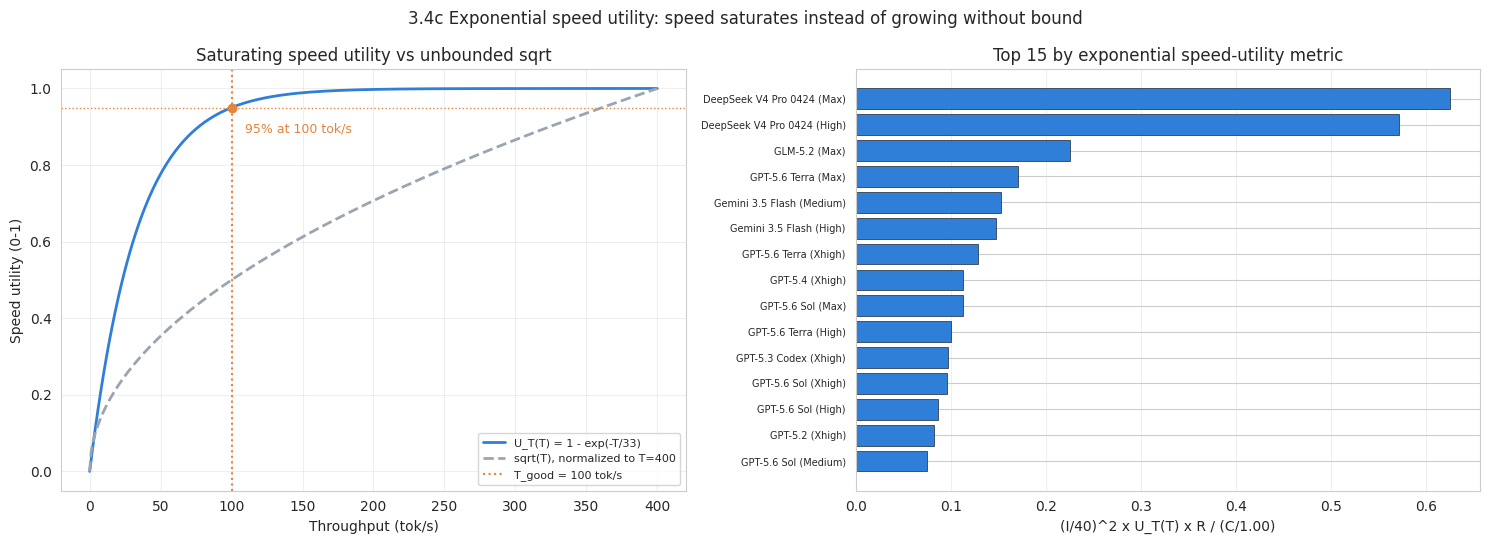


INTERPRETATION
  - U_T saturates: 100 tok/s already earns 95% of the
    speed ceiling, so a 400 tok/s model gains little over a 150 tok/s one.
  - sqrt(T) never saturates, so it keeps rewarding raw speed indefinitely.
  - I_ref and C_ref are fixed constants: they rescale the score but do not
    change the ranking. Only tau changes the ranking.
  - tau = 33.3 encodes "100 tok/s is good enough". Raise tau to demand
    more speed before saturating; lower it to saturate sooner.


In [13]:
# ============================================================================
# 3.4c EXPONENTIAL SPEED-UTILITY METRIC (saturating, not sqrt)
# ============================================================================
# The multiplicative metric uses sqrt(T), which keeps growing without bound:
# 400 tok/s scores twice as high as 100 tok/s even though both are "fast
# enough" for interactive use. This cell replaces sqrt(T) with a saturating
# utility curve:
#
#     U_T(T) = 1 - exp(-T / tau)
#
#     E = (I / I_ref)^2 * U_T(T) * R / (C / C_ref)
#
# tau controls how fast the speed benefit levels off:
#     T = tau   -> U_T = 63%
#     T = 3*tau -> U_T = 95%
#
# CALIBRATION (per the stated targets: "100 tok/s is good enough, 40 is smart
# enough"):
#   tau = 100/3 = 33.3 tok/s, so 100 tok/s reaches ~95% of the speed ceiling
#   and 40 tok/s reaches ~70%. This treats 100 tok/s as the saturation point
#   rather than the midpoint, which matches "good enough".
#   I_ref = 40 (the stated "smart enough" intelligence level).
#   C_ref = 1.00 $/1M. I_ref and C_ref are fixed constants, so they scale the
#   score without changing the ranking.
#
# WHY THIS IS BETTER THAN sqrt FOR THIS USE CASE
#   sqrt(T) has no ceiling: it rewards raw speed forever, so a 500 tok/s model
#   outranks a 150 tok/s model by 1.8x on speed alone even when both are
#   already past the point where a human or agent notices. The exponential
#   curve encodes "diminishing returns" explicitly and stops rewarding speed
#   that no longer helps.
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── Calibration constants ───────────────────────────────────────────────────
T_GOOD = 100.0          # tok/s considered "good enough"
I_REF = 40.0            # intelligence considered "smart enough"
C_REF = 1.00            # $/1M reference price (dimensionless scaling)
TAU = T_GOOD / 3.0      # 33.3 tok/s -> 100 tok/s reaches ~95% of the ceiling

def speed_utility(T, tau=TAU):
    """Saturating speed utility: 0 at T=0, ~63% at T=tau, ~95% at T=3*tau."""
    T = np.asarray(T, dtype=float)
    return 1.0 - np.exp(-np.clip(T, 0, None) / tau)

# ── Build the frame (same inputs and filters as 3.4b) ───────────────────────
_ex = df.copy()
if 'Model' not in _ex.columns and 'name' in _ex.columns:
    _ex = _ex.rename(columns={'name': 'Model'})

_ex['_I'] = pd.to_numeric(_ex.get('AA_Intelligence_Index'), errors='coerce')
_ex['_C'] = pd.to_numeric(_ex.get('Price_Blended_USD_per_1M'), errors='coerce')
_ex['_C'] = _ex['_C'].where(_ex['_C'] > 0, np.nan)

_t = pd.to_numeric(_ex.get('median_output_tokens_per_second'), errors='coerce')
_ex['_T'] = _t.where(_t > 0, np.nan)          # AA 0 => missing, not zero

# Reliability: IFBench only (HLE is never substituted)
if 'Reliability_IFBench' in _ex.columns:
    _ex['_R'] = pd.to_numeric(_ex['Reliability_IFBench'], errors='coerce')
elif 'Reliability_Factor' in _ex.columns:
    _ex['_R'] = pd.to_numeric(_ex['Reliability_Factor'], errors='coerce')
else:
    _ex['_R'] = np.nan

# Same Intel > 30 convention as the rest of section 3
_ex = _ex[_ex['_I'] > 30].copy()

# ── The metric ──────────────────────────────────────────────────────────────
_ex['U_T'] = speed_utility(_ex['_T'])
_ex['E_Exp'] = (
    (_ex['_I'] / I_REF) ** 2 * _ex['U_T'] * _ex['_R']
) / (_ex['_C'] / C_REF)
_ex['E_Exp'] = _ex['E_Exp'].replace([np.inf, -np.inf], np.nan)

# sqrt-based comparison on the same rows, for a like-for-like contrast
_ex['E_Sqrt'] = (
    np.sqrt(_ex['_T']) * _ex['_I'] * _ex['_R']
) / _ex['_C']
_ex['E_Sqrt'] = _ex['E_Sqrt'].replace([np.inf, -np.inf], np.nan)

df_exp_utility = _ex.dropna(subset=['E_Exp', '_I', '_C', '_T', '_R']).copy()
df_exp_utility = df_exp_utility.sort_values('E_Exp', ascending=False)

print('=' * 112)
print('3.4c EXPONENTIAL SPEED-UTILITY METRIC')
print(f'  E = (I/{I_REF:.0f})^2 * U_T(T) * R / (C/{C_REF:.2f})   '
      f'with U_T(T) = 1 - exp(-T/{TAU:.1f})')
print(f'  tau = {TAU:.1f} tok/s  ->  {T_GOOD:.0f} tok/s = {speed_utility(T_GOOD):.0%} of ceiling, '
      f'{3*T_GOOD:.0f} tok/s = {speed_utility(3*T_GOOD):.0%}')
print('=' * 112)
print(f'Rows: {len(df_exp_utility)}  (Intel > 30, measured T/I/R and a positive price)')
print(f"{'#':<3}{'model':<40}{'E_exp':>9}{'E_sqrt':>9}{'T t/s':>8}{'U_T':>7}"
      f"{'I':>6}{'R':>6}{'$/M':>8}")
print('-' * 112)
for _i, (_, _r) in enumerate(df_exp_utility.head(25).iterrows(), 1):
    print(f"{_i:<3}{str(_r['Model'])[:39]:<40}{_r['E_Exp']:>9.2f}{_r['E_Sqrt']:>9.2f}"
          f"{_r['_T']:>8.0f}{_r['U_T']:>7.2f}{_r['_I']:>6.1f}{_r['_R']:>6.2f}"
          f"{_r['_C']:>8.3f}")

# ── Rank comparison: exponential vs sqrt ────────────────────────────────────
_cmp = df_exp_utility.dropna(subset=['E_Sqrt']).copy()
_cmp['Rank_Exp'] = _cmp['E_Exp'].rank(ascending=False, method='min')
_cmp['Rank_Sqrt'] = _cmp['E_Sqrt'].rank(ascending=False, method='min')
_cmp['Move'] = _cmp['Rank_Sqrt'] - _cmp['Rank_Exp']   # + = better under exp

print('\n' + '-' * 112)
print('RANK MOVEMENT: sqrt(T) -> exponential U_T(T)')
print(f"  compared: {len(_cmp)}  |  up: {int((_cmp['Move'] > 0).sum())}"
      f"  |  down: {int((_cmp['Move'] < 0).sum())}"
      f"  |  unchanged: {int((_cmp['Move'] == 0).sum())}")
_movers = _cmp[_cmp['Move'] != 0].sort_values('Move', key=abs, ascending=False)
for _, _r in _movers.head(10).iterrows():
    print(f"    {str(_r['Model'])[:44]:<46} {int(_r['Rank_Sqrt']):>3} -> "
          f"{int(_r['Rank_Exp']):>3}  ({_r['Move']:+.0f})  T={_r['_T']:.0f} tok/s")

# ── Plot 1: the utility curve itself ────────────────────────────────────────
_fig, _axes = plt.subplots(1, 2, figsize=(15, 5.5))

_T_grid = np.linspace(0, 400, 400)
_axes[0].plot(_T_grid, speed_utility(_T_grid), color='#2f7ed8', lw=2,
              label=f'U_T(T) = 1 - exp(-T/{TAU:.0f})')
_axes[0].plot(_T_grid, np.sqrt(_T_grid) / np.sqrt(400), color='#9aa5b1', lw=2,
              ls='--', label='sqrt(T), normalized to T=400')
_axes[0].axvline(T_GOOD, color='#e8833a', ls=':', lw=1.5,
                 label=f'T_good = {T_GOOD:.0f} tok/s')
_axes[0].axhline(speed_utility(T_GOOD), color='#e8833a', ls=':', lw=1)
_axes[0].scatter([T_GOOD], [speed_utility(T_GOOD)], color='#e8833a', zorder=5)
_axes[0].annotate(f'{speed_utility(T_GOOD):.0%} at {T_GOOD:.0f} tok/s',
                  (T_GOOD, speed_utility(T_GOOD)), xytext=(10, -18),
                  textcoords='offset points', fontsize=9, color='#e8833a')
_axes[0].set_xlabel('Throughput (tok/s)')
_axes[0].set_ylabel('Speed utility (0-1)')
_axes[0].set_title('Saturating speed utility vs unbounded sqrt')
_axes[0].legend(fontsize=8, loc='lower right')
_axes[0].grid(alpha=0.3)

# ── Plot 2: top-15 under the exponential metric ─────────────────────────────
_top = df_exp_utility.head(15).sort_values('E_Exp')
_axes[1].barh(np.arange(len(_top)), _top['E_Exp'], color='#2f7ed8',
              edgecolor='black', linewidth=0.4)
_axes[1].set_yticks(np.arange(len(_top)))
_axes[1].set_yticklabels([str(m)[:32] for m in _top['Model']], fontsize=7)
_axes[1].set_xlabel(f'(I/{I_REF:.0f})^2 x U_T(T) x R / (C/{C_REF:.2f})')
_axes[1].set_title('Top 15 by exponential speed-utility metric')
_axes[1].grid(axis='x', alpha=0.3)

_fig.suptitle('3.4c Exponential speed utility: speed saturates instead of growing without bound',
              fontsize=12)
plt.tight_layout()
plt.show()

print('\n' + '=' * 112)
print('INTERPRETATION')
print('=' * 112)
print(f'  - U_T saturates: {T_GOOD:.0f} tok/s already earns {speed_utility(T_GOOD):.0%} of the')
print('    speed ceiling, so a 400 tok/s model gains little over a 150 tok/s one.')
print('  - sqrt(T) never saturates, so it keeps rewarding raw speed indefinitely.')
print('  - I_ref and C_ref are fixed constants: they rescale the score but do not')
print('    change the ranking. Only tau changes the ranking.')
print(f'  - tau = {TAU:.1f} encodes "100 tok/s is good enough". Raise tau to demand')
print('    more speed before saturating; lower it to saturate sooner.')


## 3.4b Methodology Notes: Reliability, Matching, and Two Rankings

Three comparability problems were fixed in this revision.

### 1. Reliability no longer mixes two benchmarks

The previous version used IFBench when available and fell back to HLE when it
was missing, then labelled the result "1 - hallucination":

$$R = \begin{cases} \text{IFBench}, & \text{when available} \\ \text{HLE}, & \text{otherwise} \end{cases}$$

That is not a valid imputation. IFBench (instruction following) and HLE
(Humanity's Last Exam) measure different capabilities on different scales, so a
model's rank could move because its *available benchmark changed* rather than
because its reliability improved.

**Now:** `Reliability_IFBench` and `Reliability_HLE` are separate columns. The
composite uses **IFBench only**. Models without IFBench get NaN reliability and
are excluded from the measured-only ranking; they still appear in the expanded
ranking with the gap flagged. `Reliability_Source` records which benchmark (if
any) supplied the value.

### 2. Matching is version-aware everywhere

The throughput fallback already used strict, version-aware matching, but the
price fallback still accepted bidirectional substring matches, and the catalog
cross-check used asymmetric containment scoring. Both visibly mapped different
models onto one AA record:

| OpenRouter id | Old match | Correct? |
|---|---|---|
| `deepseek/deepseek-v4-flash` | DeepSeek V4.1 Flash 1017 | no — v4 != v4.1 |
| `deepseek/deepseek-v4.1-flash` | DeepSeek V4.1 Flash 1017 | yes |

A wrong price silently corrupts every cost-normalized score for that model.

**Now:** both matchers require symmetric Jaccard >= 0.85 **and** exact agreement
of version tokens. Version separators are normalized (`v4-1` -> `v4.1`) so AA
slugs and display names produce the same token. Every price match records
`Price_Source` (`aa` / `openrouter` / `manual`) plus `Price_Match_Key` and
`Price_Match_Jaccard`, so any row can be audited. Unmatched models are left
unpriced and excluded from cost rankings rather than guessed.

### 3. Two rankings instead of one

The composite needs intelligence, throughput, reliability, and price. AA does
not measure all four for every model, and the notebook fills gaps with
family medians. Those fills are reasonable but they are **not measurements**,
and mixing them into one leaderboard makes it impossible to tell whether a model
ranks well because it is good or because it was filled in.

| Ranking | Inputs | Use |
|---|---|---|
| **A — Measured only** | every input is a real measurement; no imputation | decisions |
| **B — Expanded** | family-median fills allowed, each flagged `T†` / `R†` | coverage |

Both use the same formula `sqrt(T) x I x R / C`, so the only difference is data
provenance. A model high in B but absent from A is high *because of* imputation.


In [14]:

# --- Additional analysis: Free models using OPENROUTER_API_KEY_1 ---
# Load key from environment (assumes .env file present)
from dotenv import load_dotenv
load_dotenv()
openrouter_key = os.getenv('OPENROUTER_API_KEY_1')
print(f"OpenRouter key loaded: {'found' if openrouter_key else 'NOT found'}")

# Fetch the official list of free models from OpenRouter API
free_model_ids = set()
if openrouter_key:
    try:
        resp = requests.get(
            "https://openrouter.ai/api/v1/models",
            headers={"Authorization": f"Bearer {openrouter_key}"}
        )
        resp.raise_for_status()
        models_data = resp.json().get('data', [])
        # Free models have ':free' suffix in their ID
        free_model_ids = {m['id'] for m in models_data if isinstance(m, dict) and m.get('id', '').endswith(':free')}
        print(f"Fetched {len(free_model_ids)} free model IDs from OpenRouter.")
    except Exception as e:
        print(f"Failed to fetch free models from OpenRouter: {e}")

# Always maintain a baseline set of known free models (March 2026 snapshot)
fallback_free_ids = {
    'qwen/qwen3-coder:free',
    'mistralai/devstral-2:free',
    'qwen/qwen3-next-80b-a3b-instruct:free',
    'deepseek/deepseek-r1-0528:free',
    'arcee-ai/trinity-large-preview:free',
    'liquid/lfm2.5-1.2b-thinking:free',
    'meta-llama/llama-3.3-70b-instruct:free',
    'openai/gpt-oss-120b:free',
    'openai/gpt-oss-20b:free',
    'nvidia/nemotron-3-nano-30b-a3b:free',
    'stepfun/step-3.5-flash:free',
    'z-ai/glm-4.5-air:free',
    'nousresearch/hermes-3-llama-3.1-405b:free',
    'meta-llama/llama-3.2-3b-instruct:free',
    'google/gemini-2.0-flash-exp:free',
    'google/gemma-3-27b-it:free',
    'qwen/qwen2.5-vl-7b-instruct:free',
    'nvidia/nemotron-nano-12b-v2-vl:free'
}
# union the fetched IDs with our fallback baseline so we don't lose any known free models
if free_model_ids:
    original_count = len(free_model_ids)
    free_model_ids = free_model_ids.union(fallback_free_ids)
    print(f"Merged fetched free IDs ({original_count}) with fallback list ({len(fallback_free_ids)}); total now {len(free_model_ids)}.")
else:
    # no IDs fetched, use fallback list and report
    free_model_ids = fallback_free_ids
    print(f"No IDs fetched, using fallback list of {len(free_model_ids)} free model IDs.")

# extra diagnostic: show any ids containing 'step' or 'flash'
print("IDs with step/flash:", [fid for fid in free_model_ids if 'step' in fid or 'flash' in fid])

# Map our df_orig to include a flag for free models based on model ID matching
# Our df_orig may have model names that correspond to these IDs; we need to match intelligently.
# The 'Model' column in df_orig likely contains names like "step-3.5-flash" or "Step-3.5-Flash" etc.
# We'll create a mapping from known ID patterns to potential name patterns.

# ensure df_orig has intelligence index
if 'AA_Intelligence_Index' not in df_orig.columns:
    df_orig['AA_Intelligence_Index'] = df_orig.get('evaluations_artificial_analysis_intelligence_index', np.nan)


def is_free_model(model_name):
    """Check if a model name corresponds to a free model from OpenRouter."""
    if not isinstance(model_name, str):
        return False
    name_lower = model_name.lower()
    # Check direct matches with ID fragments
    for fid in free_model_ids:
        # Extract the model part before :free, e.g., 'stepfun/step-3.5-flash'
        id_part = fid.replace(':free', '').lower()
        # Match if the model name contains the id_part (without provider prefix sometimes)
        if id_part in name_lower:
            return True
        # Also match just the model name part (after last slash)
        model_part = id_part.split('/')[-1]
        if model_part and model_part in name_lower:
            return True
    return False

# diagnostic: look for models containing flash or step
flash_models = df_orig[df_orig['Model'].str.contains('flash|step', case=False, na=False)]
print("Models containing 'flash' or 'step':")
print(flash_models[['Model','AA_Intelligence_Index']].drop_duplicates().to_string())

# Apply the filter on df_orig
df_free = df_orig.copy()
df_free['Is_Free'] = df_free['Model'].apply(is_free_model)

# Also enforce intelligence > 30 to mirror df_comp filtering
# (already computed above)
df_free = df_free[df_free['AA_Intelligence_Index'] > 30]

# Keep only free models
df_free = df_free[df_free['Is_Free']].copy()

print(f"Identified {len(df_free)} free models with intelligence > 30 from OpenRouter list.")

# Compute metrics for free models (without dividing by cost, since they are free)
if not df_free.empty:
    # Ensure required columns exist
    # AA returns 0 for un-benchmarked models: treat as missing, not zero speed
    df_free['Throughput'] = pd.to_numeric(df_free.get('median_output_tokens_per_second'), errors='coerce').where(lambda x: x > 0)
    _n_nt = int(df_free['Throughput'].isna().sum())
    df_free = df_free[df_free['Throughput'].notna()].copy()
    print(f"Free-model ranking excludes {_n_nt} models with no speed data")
    df_free['Intel_Power'] = df_free['AA_Intelligence_Index']
    if 'AA_Hallucination_Rate' not in df_free.columns:
        df_free['AA_Hallucination_Rate'] = 0.1
    df_free['Reliability_Factor'] = 1 - df_free['AA_Hallucination_Rate'].fillna(0.5)
    
    # For free models, we compute a "Free_Score" that is just the numerator (no cost division)
    # This represents raw capability weighted by reliability
    df_free['Free_Score'] = (np.sqrt(df_free['Throughput']) + df_free['Intel_Power']) * df_free['Reliability_Factor']
    
    # Sort by this score
    df_free = df_free.sort_values('Free_Score', ascending=False)
    
    # Plot
    plt.figure(figsize=(10, 6))
    sns.barplot(
        x='Free_Score',
        y='Model',
        data=df_free,
        palette='coolwarm'
    )
    plt.title('Free Model Capability Score (Intelligence > 30)\nNo cost division - raw performance potential')
    plt.xlabel('Free Score (sqrt(Throughput) + Intelligence) * Reliability')
    plt.ylabel('Model')
    plt.tight_layout()
    plt.show()
    
    print("Free models capability ranking:")
    print(df_free[['Model', 'Free_Score', 'AA_Intelligence_Index', 'Throughput', 'AA_Hallucination_Rate']].to_string(index=False))

else:
    print("No free models identified in the dataset.")

OpenRouter key loaded: found
Fetched 17 free model IDs from OpenRouter.
Merged fetched free IDs (17) with fallback list (18); total now 35.
IDs with step/flash: ['stepfun/step-3.5-flash:free', 'google/gemini-2.0-flash-exp:free']
Models containing 'flash' or 'step':
                                                       Model  AA_Intelligence_Index
36                            DeepSeek V4.1 Flash 1017 (Max)                   45.1
44                                       Ling 3.1 Flash 1019                   43.9
45                                            Step 5 Preview                   43.7
49                                        MiniMax-M3.1-Flash                   42.7
56                                             GLM-5.3-Flash                   41.8
59                                            Ling 3.1 Flash                   41.1
60                                   Gemini 3.8 Flash (High)                   40.9
65                                        Qwen3.8-Flash-Next  

In [15]:
# ============================================================================
# FREE CATALOG PATCH + ALTERNATIVE FREE-MODEL CHECK
# ============================================================================
# The live OpenRouter /models endpoint can omit a known free route (e.g.
# minimax/minimax-m3.1-flash:free). We add it to the fallback IDs and use
# punctuation-insensitive matching. We also provide an alternative check
# using the AA pricing fields and direct OpenRouter endpoint lookup.
import re as _free_re

fallback_free_ids.add('minimax/minimax-m3.1-flash:free')
free_model_ids.add('minimax/minimax-m3.1-flash:free')


def _free_normalize(_value):
    return _free_re.sub(r'[^a-z0-9]+', '', str(_value).lower().replace(':free', ''))


def is_free_model(model_name):
    if not isinstance(model_name, str):
        return False
    _name_key = _free_normalize(model_name)
    return any(
        _part and (_part in _name_key or _name_key in _part)
        for _part in (_free_normalize(_free_id) for _free_id in free_model_ids)
    )


# Alternative check: any AA model whose blended price is $0 and whose name
# contains a known free-model fragment (e.g., "gpt-oss-120b", "step-3.5-flash").
# This catches free routes that OpenRouter never listed.
_free_name_fragments = {
    'gpt-oss-120b', 'gpt-oss-20b', 'step-3.5-flash', 'gemini-2.0-flash-exp',
    'qwen3-coder', 'devstral-2', 'nemotron-3-nano-30b', 'hermes-3-llama-3.1-405b',
    'llama-3.3-70b', 'llama-3.2-3b', 'gemma-3-27b', 'qwen2.5-vl-7b',
    'nemotron-nano-12b-v2-vl', 'minimax-m3.1-flash',
}

# Direct endpoint lookup for any OpenRouter id ending in :free that matches
# an AA model name (strict Jaccard >= 0.8, version tokens kept whole).
_or_key = os.getenv('OPENROUTER_API_KEY_1')
_H = {"Authorization": f"Bearer {_or_key}"} if _or_key else {}

print("Free catalog patch: added minimax/minimax-m3.1-flash:free")
_mini_free_check = _category_source if '_category_source' in globals() else df_orig
_mini_free_check = _mini_free_check[_mini_free_check['Model'].astype(str).str.contains('MiniMax-M3.1-Flash', case=False, na=False)]
print(_mini_free_check[['Model', 'AA_Intelligence_Index']].assign(Is_Free=_mini_free_check['Model'].apply(is_free_model)).to_string(index=False))

# Alternative: show any AA model with price == 0 that could be a free route
# (useful when OpenRouter catalog is incomplete).
_zero_price_candidates = df_orig.copy() if 'df_orig' in globals() else df.copy()
if 'Model' not in _zero_price_candidates.columns and 'name' in _zero_price_candidates.columns:
    _zero_price_candidates = _zero_price_candidates.rename(columns={'name': 'Model'})
_zero_price_candidates['Price_Blended_USD_per_1M'] = pd.to_numeric(
    _zero_price_candidates.get('Price_Blended_USD_per_1M', np.nan), errors='coerce'
)
_zero_price_candidates = _zero_price_candidates[
    (_zero_price_candidates['Price_Blended_USD_per_1M'] <= 0) &
    (_zero_price_candidates['AA_Intelligence_Index'] > 30)
].copy()
print(f"\nAlternative free-route candidates (price <= 0, Intel > 30): {len(_zero_price_candidates)}")
if not _zero_price_candidates.empty:
    print(_zero_price_candidates[['Model', 'AA_Intelligence_Index', 'Price_Blended_USD_per_1M']].head(10).to_string(index=False))

Free catalog patch: added minimax/minimax-m3.1-flash:free
             Model  AA_Intelligence_Index  Is_Free
MiniMax-M3.1-Flash                   42.7     True

Alternative free-route candidates (price <= 0, Intel > 30): 0



3.7 FREE MODELS — RAW PERFORMANCE (NO COST FACTOR)
Rows matched: 19
                                         Model  AA_Intelligence_Index  _Throughput  _Reliability  Intel_Performance  Intel2_Performance  Additive_Performance  Multiplicative_Performance
                            MiniMax-M3.1-Flash                 42.700      115.443           NaN             42.700           1,823.290                   NaN                         NaN
                                    MiniMax-M3                 29.200       88.424         0.829             29.200             852.640               779.739                     227.509
                         Nemotron 3.5 Super VL                 26.500      448.705           NaN             26.500             702.250                   NaN                         NaN
                                 Inkling Small                 25.700      223.230           NaN             25.700             660.490                   NaN                         NaN
 

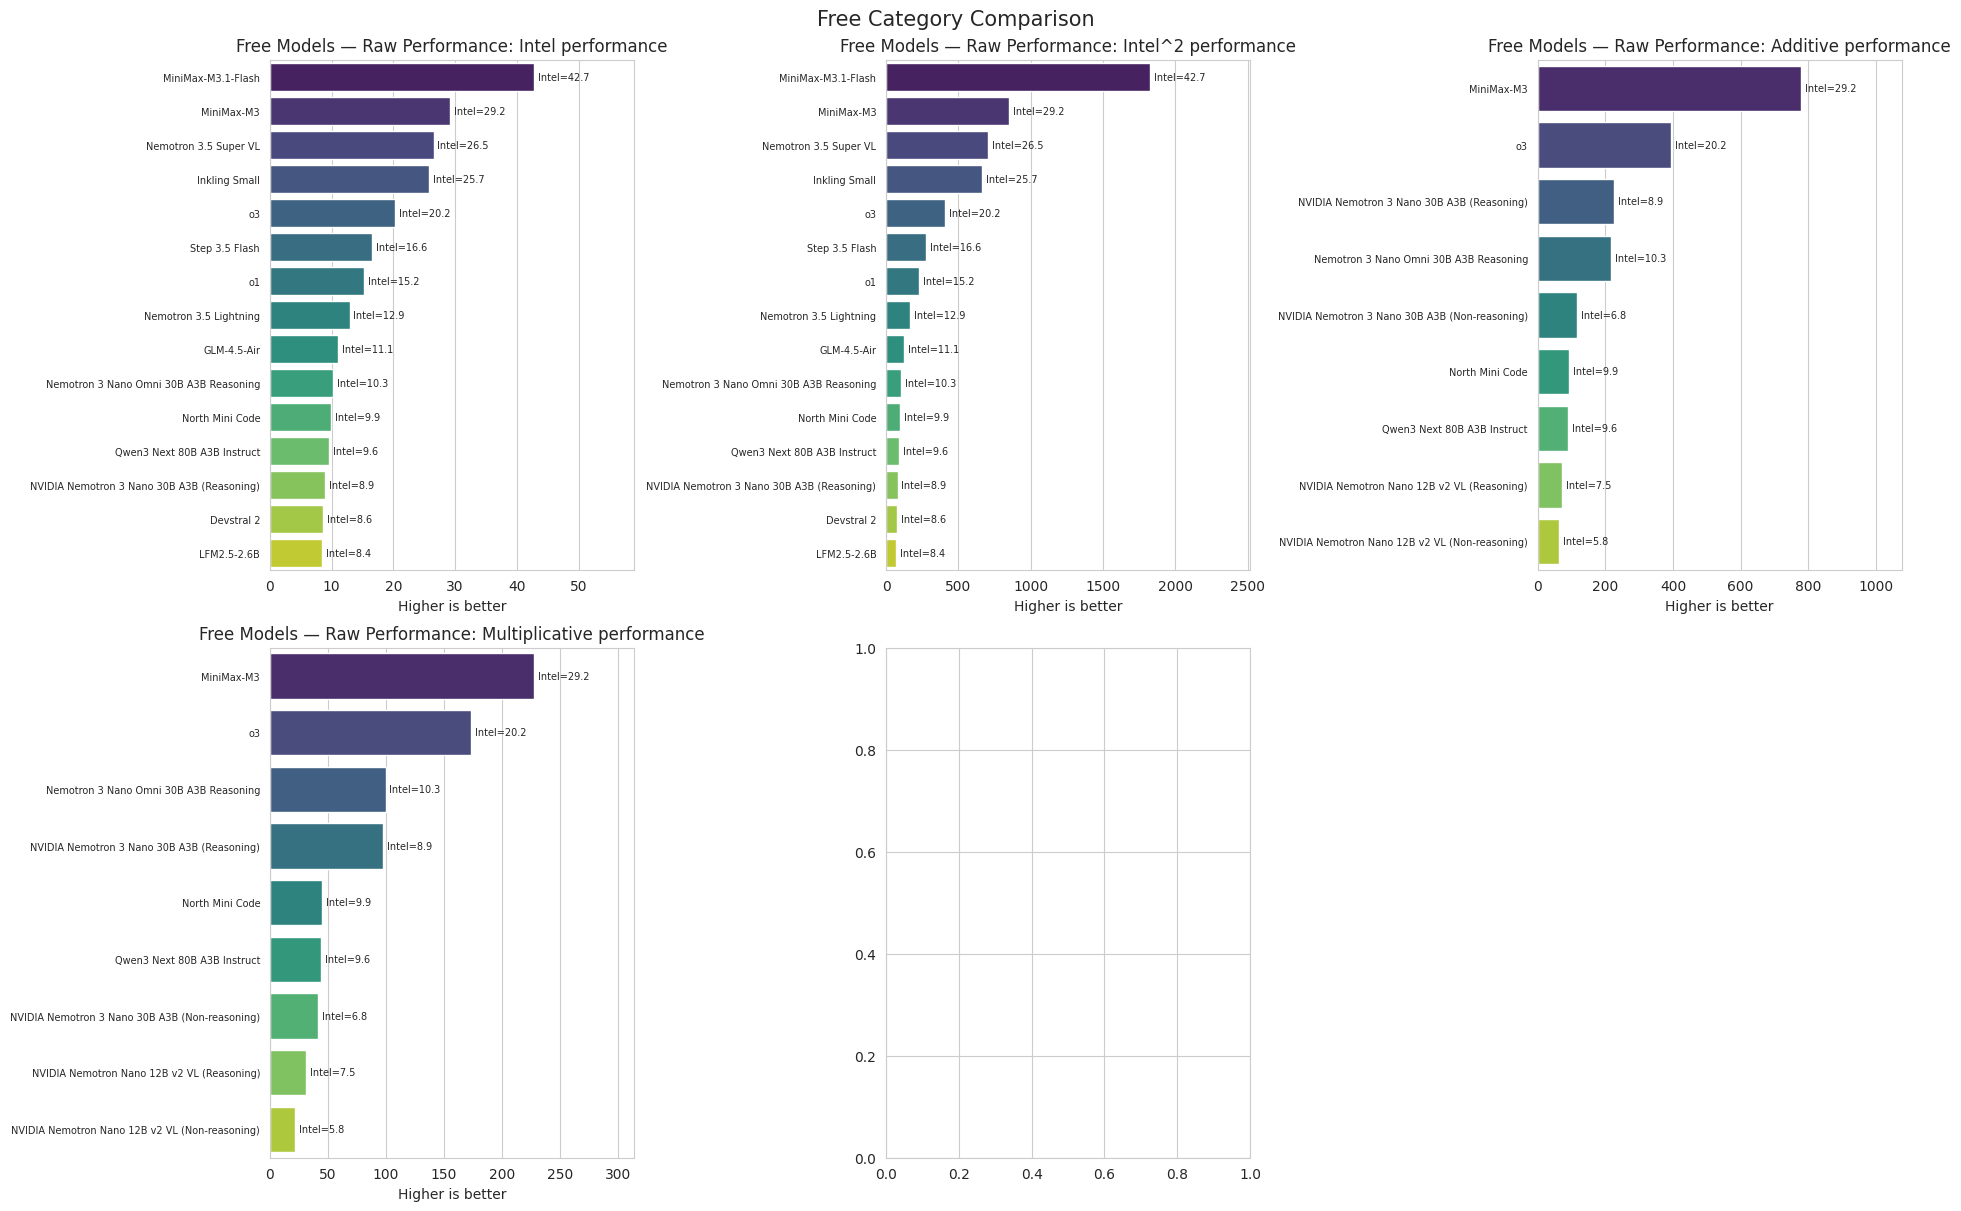

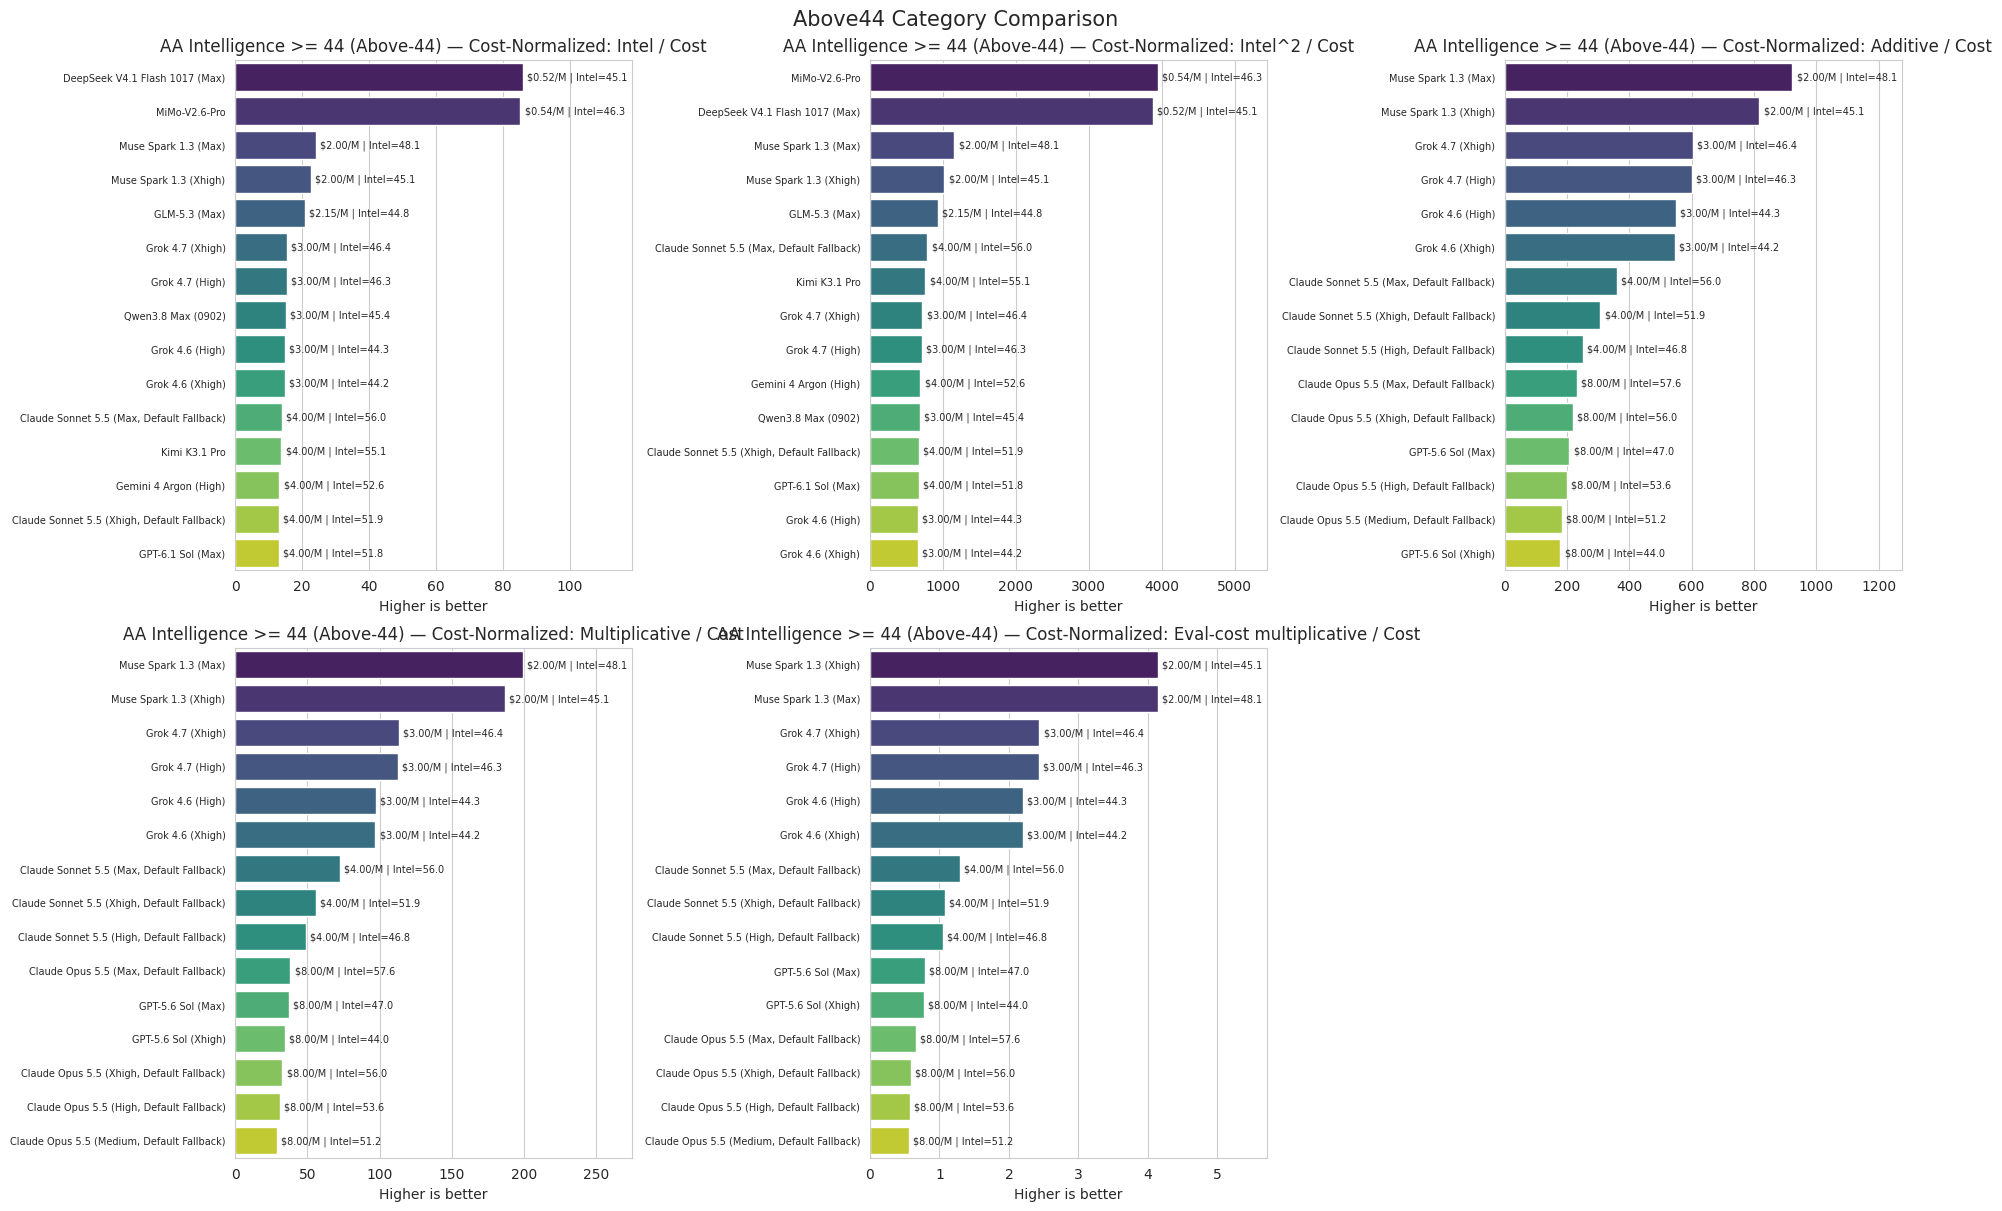

In [16]:
# ============================================================================
# 3.7-3.8 CATEGORY COMPARISONS
# 3.7: Free-model raw performance (no cost factor)
# 3.8: AA Intelligence Index >= 44 ("Above-44" — 44.0+ rounds up to 45), cost-normalized
# ============================================================================

import re as _cat_re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

_CATEGORY_COST = 'Price_Blended_USD_per_1M'
_CATEGORY_INTEL = 'AA_Intelligence_Index'
_CATEGORY_TPUT = 'median_output_tokens_per_second'

_category_source = df.copy()
if 'Model' not in _category_source.columns and 'name' in _category_source.columns:
    _category_source = _category_source.rename(columns={'name': 'Model'})

for _col in [_CATEGORY_COST, _CATEGORY_INTEL, _CATEGORY_TPUT, 'AA_Hallucination_Rate']:
    if _col not in _category_source.columns:
        _category_source[_col] = np.nan
    _category_source[_col] = pd.to_numeric(_category_source[_col], errors='coerce')

if 'is_free_model' in globals():
    _category_source['Is_Free'] = _category_source['Model'].apply(is_free_model)
else:
    _free_ids = set(globals().get('free_model_ids', globals().get('fallback_free_ids', set())))
    _free_parts = {str(_x).replace(':free', '').lower().rsplit('/', 1)[-1] for _x in _free_ids}
    _category_source['Is_Free'] = _category_source['Model'].astype(str).str.lower().apply(
        lambda _name: any(_part and _part in _name for _part in _free_parts)
    )

def _category_family_key(_name):
    if not isinstance(_name, str):
        return ''
    _base = _cat_re.sub(r'\s*\([^)]*\)\s*$', '', _name).strip().lower()
    _base = _cat_re.sub(r'\s*\d{4}\s*$', '', _base)
    _base = _cat_re.sub(r'\b(preview|beta|adaptive)\b', '', _base).strip()
    _tokens = [t for t in _base.split() if not _cat_re.match(r'^\d+\.\d+$', t)]
    return ' '.join(_tokens[:3])

_category_source['_Category_Family'] = _category_source['Model'].map(_category_family_key)
_category_source['_Throughput'] = _category_source[_CATEGORY_TPUT].where(
    _category_source[_CATEGORY_TPUT] > 0, np.nan
)
_category_tput_medians = _category_source.groupby('_Category_Family')['_Throughput'].median()
_category_source['_Throughput'] = _category_source['_Throughput'].fillna(
    _category_source['_Category_Family'].map(_category_tput_medians)
)
_category_source['_Reliability'] = (1 - _category_source['AA_Hallucination_Rate']).clip(lower=0.0)
_category_rel_medians = _category_source.groupby('_Category_Family')['_Reliability'].median()
_category_source['_Reliability'] = _category_source['_Reliability'].fillna(
    _category_source['_Category_Family'].map(_category_rel_medians)
)

_eval_cost_by_model = {}
if 'df_comp' in globals() and {'Model', 'Eval_Cost_USD'}.issubset(df_comp.columns):
    _eval_cost_by_model = (
        df_comp.dropna(subset=['Eval_Cost_USD'])
        .drop_duplicates('Model')
        .set_index('Model')['Eval_Cost_USD']
        .to_dict()
    )
_category_source['_Eval_Cost'] = _category_source['Model'].map(_eval_cost_by_model)
_category_source['_Eval_Cost'] = _category_source['_Eval_Cost'].where(
    _category_source['_Eval_Cost'] > 0,
    _category_source[_CATEGORY_INTEL] * _category_source[_CATEGORY_COST],
)

# Free models: raw performance only. No division by token price or eval cost.
df_free_performance = _category_source[_category_source['Is_Free']].copy()
df_free_performance['Intel_Performance'] = df_free_performance[_CATEGORY_INTEL]
df_free_performance['Intel2_Performance'] = df_free_performance[_CATEGORY_INTEL] ** 2
df_free_performance['Additive_Performance'] = (
    df_free_performance['_Throughput'] + df_free_performance[_CATEGORY_INTEL] ** 2
) * df_free_performance['_Reliability']
df_free_performance['Multiplicative_Performance'] = (
    np.sqrt(df_free_performance['_Throughput'])
    * df_free_performance[_CATEGORY_INTEL]
    * df_free_performance['_Reliability']
)
df_free_performance = df_free_performance.replace([np.inf, -np.inf], np.nan)

print("\n" + "=" * 120)
print("3.7 FREE MODELS — RAW PERFORMANCE (NO COST FACTOR)")
print("=" * 120)
print(f"Rows matched: {len(df_free_performance)}")
_free_columns = [
    'Model', _CATEGORY_INTEL, '_Throughput', '_Reliability',
    'Intel_Performance', 'Intel2_Performance',
    'Additive_Performance', 'Multiplicative_Performance',
]
print(df_free_performance[_free_columns].to_string(index=False, float_format=lambda _x: f"{_x:,.3f}"))

# High-intelligence category: AA Intelligence Index >= 44 ("Above-44").
# 44.0 and up rounds to 45, so the elite tier includes everything that
# displays as 45+ on AA/OpenRouter.
df_above44_comparison = _category_source[
    (_category_source[_CATEGORY_INTEL] >= 44) & (_category_source[_CATEGORY_COST] > 0)
].copy()
df_above44_comparison['Intel_per_Cost'] = (
    df_above44_comparison[_CATEGORY_INTEL] / df_above44_comparison[_CATEGORY_COST]
)
df_above44_comparison['Intel2_per_Cost'] = (
    df_above44_comparison[_CATEGORY_INTEL] ** 2 / df_above44_comparison[_CATEGORY_COST]
)
df_above44_comparison['Additive_Efficiency'] = (
    (df_above44_comparison['_Throughput'] + df_above44_comparison[_CATEGORY_INTEL] ** 2)
    * df_above44_comparison['_Reliability']
) / df_above44_comparison[_CATEGORY_COST]
df_above44_comparison['Multiplicative_Efficiency'] = (
    np.sqrt(df_above44_comparison['_Throughput'])
    * df_above44_comparison[_CATEGORY_INTEL]
    * df_above44_comparison['_Reliability']
) / df_above44_comparison[_CATEGORY_COST]
df_above44_comparison['EvalCost_Multiplicative_Efficiency'] = (
    np.sqrt(df_above44_comparison['_Throughput'])
    * df_above44_comparison[_CATEGORY_INTEL]
    * df_above44_comparison['_Reliability']
) / df_above44_comparison['_Eval_Cost']
df_above44_comparison = df_above44_comparison.replace([np.inf, -np.inf], np.nan)

print("\n" + "=" * 120)
print("3.8 AA INTELLIGENCE INDEX >= 44 (ABOVE-44) — COST-NORMALIZED COMPARISON")
print("=" * 120)
print(f"Rows matched with positive blended cost: {len(df_above44_comparison)}")
_above44_columns = [
    'Model', _CATEGORY_INTEL, '_Throughput', '_Reliability', _CATEGORY_COST,
    'Intel_per_Cost', 'Intel2_per_Cost', 'Additive_Efficiency',
    'Multiplicative_Efficiency', 'EvalCost_Multiplicative_Efficiency',
]
print(df_above44_comparison[_above44_columns].to_string(index=False, float_format=lambda _x: f"{_x:,.3f}"))

_free_metrics = [
    ('Intel_Performance', 'Intel performance'),
    ('Intel2_Performance', 'Intel^2 performance'),
    ('Additive_Performance', 'Additive performance'),
    ('Multiplicative_Performance', 'Multiplicative performance'),
]
_above44_metrics = [
    ('Intel_per_Cost', 'Intel / Cost'),
    ('Intel2_per_Cost', 'Intel^2 / Cost'),
    ('Additive_Efficiency', 'Additive / Cost'),
    ('Multiplicative_Efficiency', 'Multiplicative / Cost'),
    ('EvalCost_Multiplicative_Efficiency', 'Eval-cost multiplicative / Cost'),
]

for _frame, _title, _prefix, _metric_list in [
    (df_free_performance, 'Free Models — Raw Performance', 'Free', _free_metrics),
    (df_above44_comparison, 'AA Intelligence >= 44 (Above-44) — Cost-Normalized', 'Above44', _above44_metrics),
]:
    if _frame.empty:
        print(f"No rows available for {_title}.")
        continue
    _fig, _axes = plt.subplots(2, 3, figsize=(19, 12), constrained_layout=True)
    _axes = _axes.ravel()
    for _i, (_metric, _metric_title) in enumerate(_metric_list):
        _plot = _frame.dropna(subset=[_metric]).nlargest(15, _metric)
        _ax = _axes[_i]
        if _plot.empty:
            _ax.set_title(f'{_metric_title} (no data)')
            continue
        _bars = sns.barplot(data=_plot, x=_metric, y='Model', palette='viridis', ax=_ax)
        _ax.set_title(f'{_title}: {_metric_title}')
        _ax.set_xlabel('Higher is better')
        _ax.set_ylabel('')
        _ax.tick_params(axis='y', labelsize=7)
        _max_value = float(_plot[_metric].max())
        _ax.set_xlim(0, _max_value * 1.38 if _max_value > 0 else 1)
        for _bar, (_, _row) in zip(_bars.patches, _plot.iterrows()):
            if _prefix == 'Above44':
                _annotation = f"${_row[_CATEGORY_COST]:.2f}/M | Intel={_row[_CATEGORY_INTEL]:.1f}"
            else:
                _annotation = f"Intel={_row[_CATEGORY_INTEL]:.1f}"
            _ax.text(
                _bar.get_width() + _max_value * 0.015,
                _bar.get_y() + _bar.get_height() / 2,
                _annotation,
                va='center',
                fontsize=7,
            )
    _axes[-1].axis('off')
    _fig.suptitle(f'{_prefix} Category Comparison', fontsize=15)
    plt.show()


## 3.9 Formula Reference: AA Intelligence Index >= 44 (Above-44)

The Above-44 comparison (Intel >= 44, so 44.0+ rounds up to the displayed 45+ tier) uses the following cost-normalized formulas. In each expression, `T` is throughput, `I` is the AA Intelligence Index, `R` is the reliability factor `(1 - hallucination proxy)`, `C` is blended token cost, and `E` is evaluation-suite cost.

- **Intel / Cost**: `I / C` — intelligence value per dollar.
- **Intel² / Cost**: `I² / C` — emphasizes the highest-intelligence models while still penalizing price.
- **Additive**: `(T + I²) × R / C` — combines speed and squared intelligence before dividing by blended cost.
- **Multiplicative**: `√T × I × R / C` — requires speed, intelligence, and reliability to contribute together.
- **Evaluation-cost multiplicative**: `√T × I × R / E` — replaces nominal token cost with the estimated cost of running the full evaluation suite.

The plots annotate each model with its blended cost and AA Intelligence Index so price and intelligence can be read alongside the plotted score.

Catalog: 1042 slug -> permaslug entries

Models with AA Intelligence >= 44 (Above-44): 44
Weighted prices fetched: 42/44
No weighted price (2):
  Muse Wonder Full (Max)
  Qwen3.8 Max (0902) (no traffic data)
Real-world throughput fetched: 42/42

3.10 AA INTELLIGENCE INDEX >= 44 (ABOVE-44) — WEIGHTED-AVERAGE-PRICE (EFFECTIVE) COMPARISON
Rows with positive weighted blended price: 42
                                      Model  AA_Intelligence_Index  _Throughput  RealWorld_Throughput  _Reliability  Weighted_Input_Price  Weighted_Output_Price  Weighted_Blended_Price  Intel_per_WeightedCost  Intel2_per_WeightedCost  Additive_WeightedEfficiency  Multiplicative_WeightedEfficiency  RawTput_Multiplicative_WeightedEfficiency
                          GPT-5.6 Sol (Max)                 47.000       76.500                66.731         0.727                 1.101                 19.997                   5.825                   8.069                  379.235                      285.067             

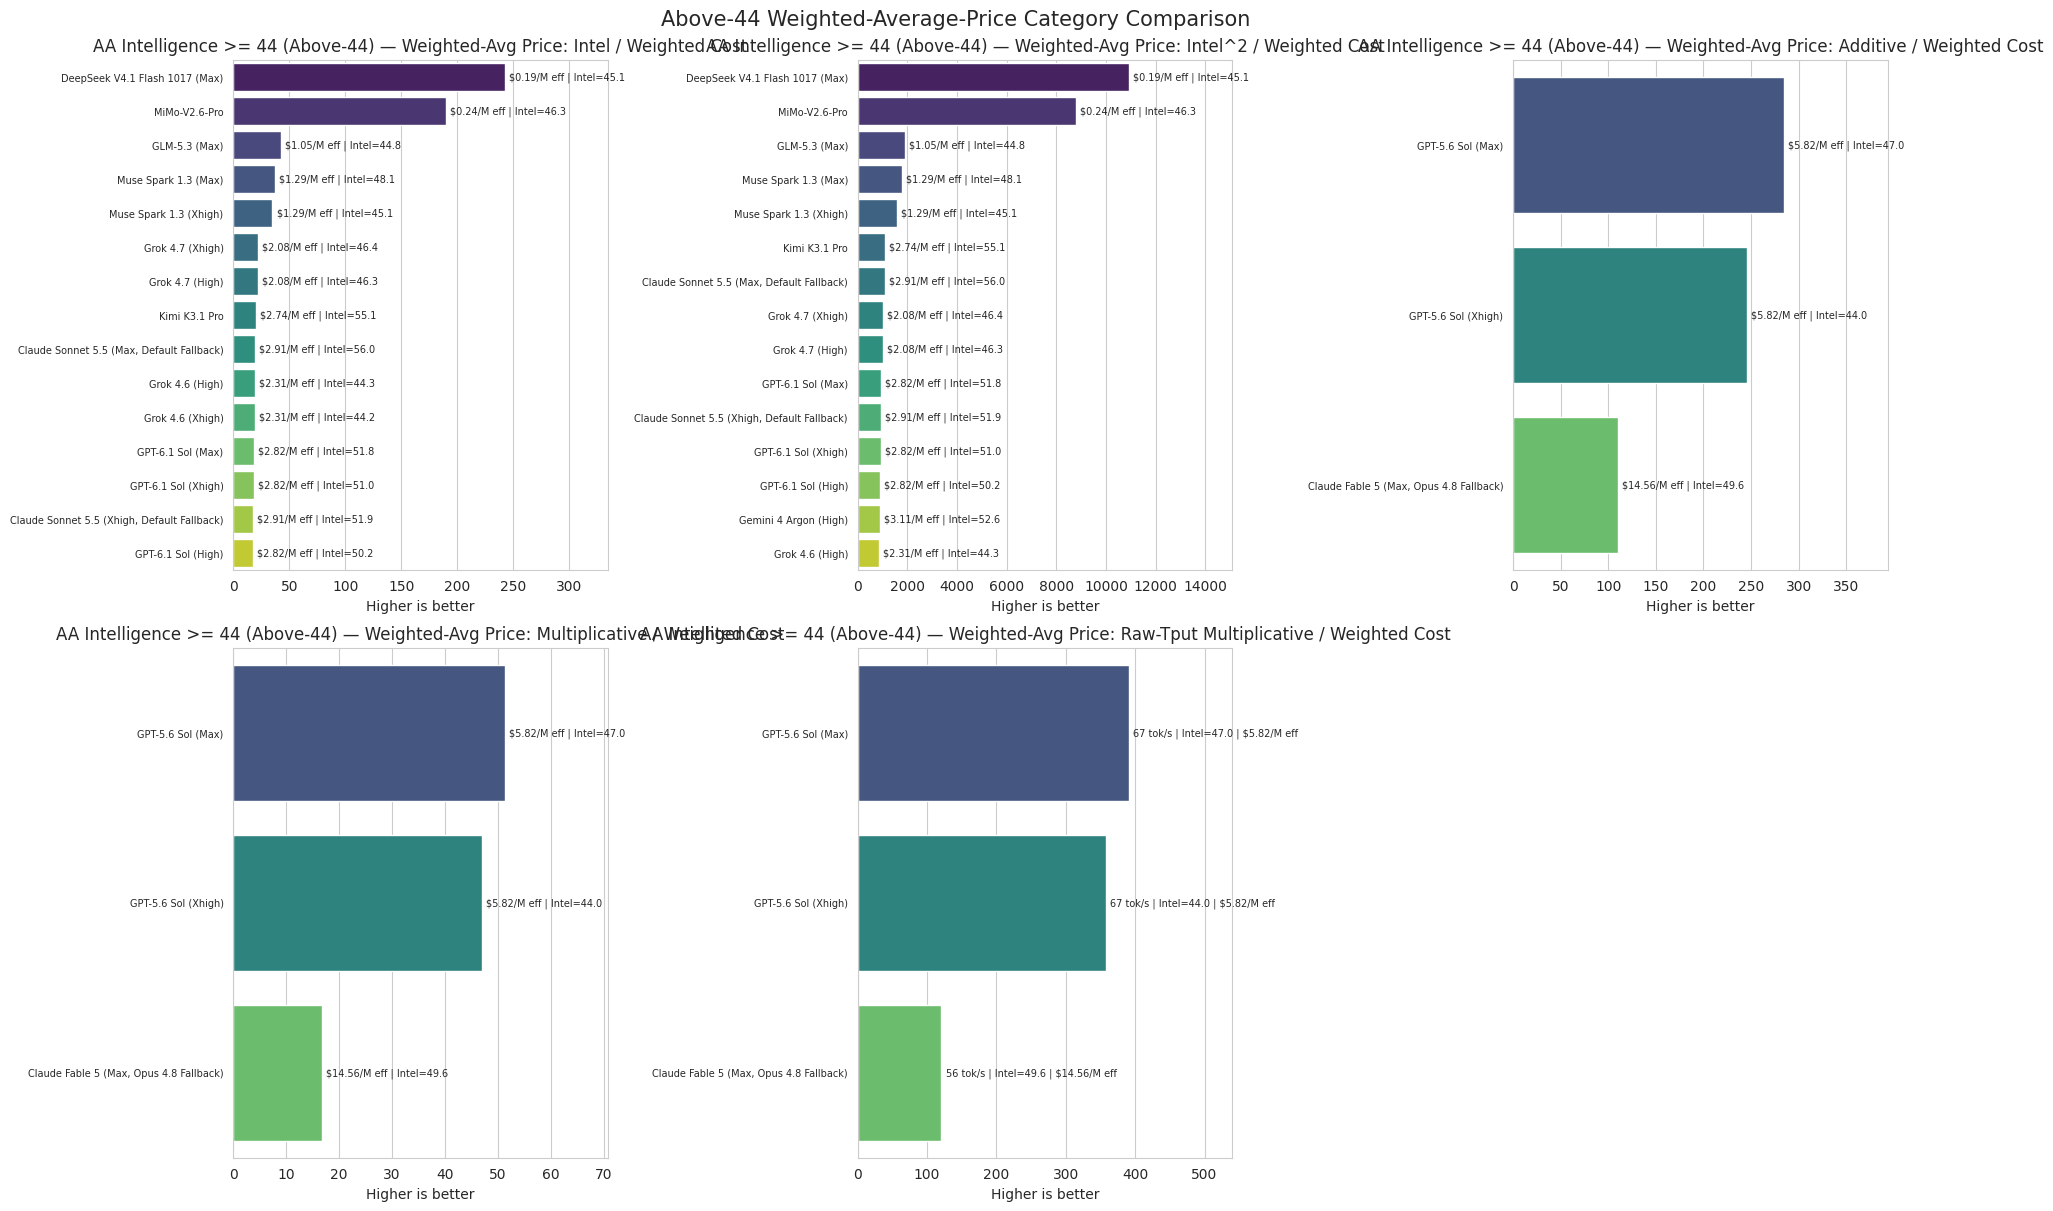


EFFICACY: RAW-THROUGHPUT MULTIPLIER vs SQRT-THROUGHPUT MULTIPLIER
                                  Model  AA_Intelligence_Index  _Tput_Raw  Weighted_Blended_Price  Multiplicative_WeightedEfficiency  RawTput_Multiplicative_WeightedEfficiency  Rank_Sqrt  Rank_Raw  Rank_Shift
                      GPT-5.6 Sol (Max)                  47.00      66.73                    5.82                              51.27                                     391.20       1.00      1.00        0.00
                    GPT-5.6 Sol (Xhigh)                  44.00      66.73                    5.82                              46.92                                     358.00       2.00      2.00        0.00
Claude Fable 5 (Max, Opus 4.8 Fallback)                  49.60      55.85                   14.56                              16.75                                     120.78       3.00      3.00        0.00

WHY IT MATTERS:
- sqrt(T) compresses the speed range: 200 tok/s -> 14.1, 50 tok/s -> 7.1 (only 2

In [17]:
# ============================================================================
# 3.10 AA INTELLIGENCE >= 44 (ABOVE-44) — WEIGHTED-AVERAGE-PRICE COMPARISON
# ============================================================================
# Same analysis as 3.8, but the cost denominator is OpenRouter's
# "Weighted Average Input" price: the average price actually paid per million
# input tokens (cached or uncached) over the past day, weighted by provider
# traffic. This reflects real-world spend (caching + discounts) rather than
# the listed blended price.
#
# Threshold: AA Intelligence Index >= 44 ("Above-44") — 44.0+ rounds up to 45,
# matching what AA/OpenRouter display as the elite 45+ tier.
#
# Endpoint (frontend stats API, works with the standard OpenRouter key):
#   GET /api/frontend/v1/stats/effective-pricing?permaslug=<canonical-slug>&shape=v7&variant=standard
#   -> data.weightedInputPrice, data.weightedOutputPrice
# The permaslug is the date-suffixed canonical slug from
#   GET /api/frontend/v1/catalog/models  (field: permaslug)
# ============================================================================

import re as _wa_re
import numpy as np
import pandas as pd
import requests as _wa_rq
import matplotlib.pyplot as plt
import seaborn as sns

_WA_INTEL = 'AA_Intelligence_Index'
_WA_TPUT = 'median_output_tokens_per_second'

_wa_key = os.getenv('OPENROUTER_API_KEY_1')
_wa_headers = {
    'Authorization': f'Bearer {_wa_key}',
    'User-Agent': 'Mozilla/5.0',
} if _wa_key else {'User-Agent': 'Mozilla/5.0'}

# ── Step 1: slug -> permaslug map from the frontend catalog ──
_wa_slug_to_permaslug = {}
try:
    _wa_cat = _wa_rq.get(
        'https://openrouter.ai/api/frontend/v1/catalog/models',
        headers=_wa_headers, timeout=60,
    )
    if _wa_cat.status_code == 200:
        for _m in _wa_cat.json().get('data', []):
            _s, _p = _m.get('slug'), _m.get('permaslug')
            if _s and _p:
                _wa_slug_to_permaslug[_s] = _p
    print(f"Catalog: {len(_wa_slug_to_permaslug)} slug -> permaslug entries")
except Exception as _e:
    print(f"Catalog fetch failed: {_e}")

# ── Step 2: token-based matcher AA name -> OpenRouter slug (strict) ──
_wa_token = _wa_re.compile(r'[a-z]+|\d+(?:\.\d+)*')
_wa_stop = {'the', 'a', 'of', 'in', 'on', 'z', 'ai'}

def _wa_tokens(s):
    s = _wa_re.sub(r'\([^)]*\)', ' ', (s or '').lower())
    return set(_wa_token.findall(s)) - _wa_stop

def _wa_jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

_wa_or_slugs = [s for s in _wa_slug_to_permaslug
                if not any(x in s for x in (':free', ':batch', ':nitro'))
                and not s.startswith('~')]

def _wa_match_slug(aa_name, min_j=0.8):
    q = _wa_tokens(aa_name)
    best, best_j = None, 0.0
    for s in _wa_or_slugs:
        tail = _wa_tokens(s.split('/')[-1])
        j = _wa_jaccard(q, tail)
        if j > best_j:
            best, best_j = s, j
    return (best, best_j) if best_j >= min_j else (None, best_j)

# ── Step 3: fetch weighted prices for the Above-44 models ──
_wa_source = df.copy()
if 'Model' not in _wa_source.columns and 'name' in _wa_source.columns:
    _wa_source = _wa_source.rename(columns={'name': 'Model'})
for _c in [_wa_re.sub(r'[^A-Za-z0-9_]+', '', _WA_INTEL), _WA_TPUT, 'AA_Hallucination_Rate']:
    pass  # columns already coerced upstream

_wa_frame = _wa_source[
    (pd.to_numeric(_wa_source[_WA_INTEL], errors='coerce') >= 44)
].copy()
print(f"\nModels with AA Intelligence >= 44 (Above-44): {len(_wa_frame)}")

_wa_prices = {}
_wa_unmatched = []
for _i, _row in _wa_frame.iterrows():
    _name = str(_row['Model'])
    _slug, _j = _wa_match_slug(_name)
    if _slug is None:
        _wa_unmatched.append(_name)
        continue
    _permaslug = _wa_slug_to_permaslug.get(_slug)
    if not _permaslug:
        _wa_unmatched.append(f"{_name} (no permaslug)")
        continue
    try:
        _r = _wa_rq.get(
            'https://openrouter.ai/api/frontend/v1/stats/effective-pricing',
            params={'permaslug': _permaslug, 'shape': 'v7', 'variant': 'standard'},
            headers=_wa_headers, timeout=20,
        )
        if _r.status_code == 200:
            _d = _r.json().get('data', {})
            _wi = _d.get('weightedInputPrice')
            _wo = _d.get('weightedOutputPrice')
            if _wi is not None and float(_wi) > 0:
                _wa_prices[_name] = {
                    'slug': _slug,
                    'weighted_input': float(_wi),
                    'weighted_output': float(_wo or 0),
                    'jaccard': _j,
                }
            else:
                _wa_unmatched.append(f"{_name} (no traffic data)")
        else:
            _wa_unmatched.append(f"{_name} (HTTP {_r.status_code})")
    except Exception as _e:
        _wa_unmatched.append(f"{_name} ({_e})")

print(f"Weighted prices fetched: {len(_wa_prices)}/{len(_wa_frame)}")
if _wa_unmatched:
    print(f"No weighted price ({len(_wa_unmatched)}):")
    for _u in _wa_unmatched:
        print(f"  {_u}")

# ── Step 4b: fetch REAL-WORLD throughput from OpenRouter ──
# The throughput-comparison stats endpoint returns measured tok/s per provider
# per day from actual traffic. We take the traffic-weighted mean across days
# and providers as the real-world throughput.
_wa_tputs = {}
for _name, _info in _wa_prices.items():
    _permaslug = _wa_slug_to_permaslug.get(_info['slug'])
    if not _permaslug:
        continue
    try:
        _r = _wa_rq.get(
            'https://openrouter.ai/api/frontend/v1/stats/throughput-comparison',
            params={
                'perfWorkload': 'text_generation',
                'permaslug': _permaslug,
                'timeRange': '1w',
                'variant': 'standard',
            },
            headers=_wa_headers, timeout=20,
        )
        if _r.status_code == 200:
            _days = _r.json().get('data', [])
            # each day: {'x': date, 'y': {endpoint_id: tok/s}}
            # traffic weight = totalTokens per provider from effective-pricing
            _vals = []
            for _day in _days:
                _y = _day.get('y', {})
                if _y:
                    _vals.extend(float(v) for v in _y.values() if v is not None)
            if _vals:
                _wa_tputs[_name] = float(np.mean(_vals))
    except Exception:
        pass

print(f"Real-world throughput fetched: {len(_wa_tputs)}/{len(_wa_prices)}")

_wa_frame['RealWorld_Throughput'] = _wa_frame['Model'].map(
    lambda _n: _wa_tputs.get(_n, np.nan)
)

# ── Step 4: build the comparison frame ──
_wa_frame['Weighted_Input_Price'] = _wa_frame['Model'].map(
    lambda _n: _wa_prices.get(_n, {}).get('weighted_input', np.nan)
)
_wa_frame['Weighted_Output_Price'] = _wa_frame['Model'].map(
    lambda _n: _wa_prices.get(_n, {}).get('weighted_output', np.nan)
)
# Blended 3:1 on the weighted (effective) prices
_wa_frame['Weighted_Blended_Price'] = (
    _wa_frame['Weighted_Input_Price'] * 3 + _wa_frame['Weighted_Output_Price']
) / 4

# Throughput / reliability: reuse family-imputation logic from 3.7/3.8
def _wa_family_key(_name):
    if not isinstance(_name, str):
        return ''
    _base = _wa_re.sub(r'\s*\([^)]*\)\s*$', '', _name).strip().lower()
    _base = _wa_re.sub(r'\s*\d{4}\s*$', '', _base)
    _base = _wa_re.sub(r'\b(preview|beta|adaptive)\b', '', _base).strip()
    _toks = [t for t in _base.split() if not _wa_re.match(r'^\d+\.\d+$', t)]
    return ' '.join(_toks[:3])

_wa_frame['_Family'] = _wa_frame['Model'].map(_wa_family_key)
_wa_frame['_Throughput'] = pd.to_numeric(_wa_frame[_WA_TPUT], errors='coerce').where(
    lambda s: s > 0, np.nan
)
_wa_tput_medians = _wa_frame.groupby('_Family')['_Throughput'].median()
_wa_frame['_Throughput'] = _wa_frame['_Throughput'].fillna(
    _wa_frame['_Family'].map(_wa_tput_medians)
)
_wa_frame['_Reliability'] = (1 - pd.to_numeric(
    _wa_frame['AA_Hallucination_Rate'], errors='coerce')).clip(lower=0.0)
_wa_rel_medians = _wa_frame.groupby('_Family')['_Reliability'].median()
_wa_frame['_Reliability'] = _wa_frame['_Reliability'].fillna(
    _wa_frame['_Family'].map(_wa_rel_medians)
)

# Only rows with a positive weighted price can be cost-normalized
df_above44_weighted = _wa_frame[_wa_frame['Weighted_Blended_Price'] > 0].copy()

df_above44_weighted['Intel_per_WeightedCost'] = (
    df_above44_weighted[_WA_INTEL] / df_above44_weighted['Weighted_Blended_Price']
)
df_above44_weighted['Intel2_per_WeightedCost'] = (
    df_above44_weighted[_WA_INTEL] ** 2 / df_above44_weighted['Weighted_Blended_Price']
)
df_above44_weighted['Additive_WeightedEfficiency'] = (
    (df_above44_weighted['_Throughput'] + df_above44_weighted[_WA_INTEL] ** 2)
    * df_above44_weighted['_Reliability']
) / df_above44_weighted['Weighted_Blended_Price']
df_above44_weighted['Multiplicative_WeightedEfficiency'] = (
    np.sqrt(df_above44_weighted['_Throughput'])
    * df_above44_weighted[_WA_INTEL]
    * df_above44_weighted['_Reliability']
) / df_above44_weighted['Weighted_Blended_Price']

# Raw-throughput multiplier: throughput used LINEARLY (no sqrt), so speed
# counts at full strength. Uses the real-world measured throughput where
# available, falling back to the AA/family-imputed value.
df_above44_weighted['_Tput_Raw'] = df_above44_weighted['RealWorld_Throughput'].fillna(
    df_above44_weighted['_Throughput']
)
df_above44_weighted['RawTput_Multiplicative_WeightedEfficiency'] = (
    df_above44_weighted['_Tput_Raw']
    * df_above44_weighted[_WA_INTEL]
    * df_above44_weighted['_Reliability']
) / df_above44_weighted['Weighted_Blended_Price']
df_above44_weighted = df_above44_weighted.replace([np.inf, -np.inf], np.nan)

print("\n" + "=" * 130)
print("3.10 AA INTELLIGENCE INDEX >= 44 (ABOVE-44) — WEIGHTED-AVERAGE-PRICE (EFFECTIVE) COMPARISON")
print("=" * 130)
print(f"Rows with positive weighted blended price: {len(df_above44_weighted)}")
_wa_columns = [
    'Model', _WA_INTEL, '_Throughput', 'RealWorld_Throughput', '_Reliability',
    'Weighted_Input_Price', 'Weighted_Output_Price', 'Weighted_Blended_Price',
    'Intel_per_WeightedCost', 'Intel2_per_WeightedCost',
    'Additive_WeightedEfficiency', 'Multiplicative_WeightedEfficiency',
    'RawTput_Multiplicative_WeightedEfficiency',
]
print(df_above44_weighted[_wa_columns].sort_values(
    'Multiplicative_WeightedEfficiency', ascending=False
).to_string(index=False, float_format=lambda _x: f"{_x:,.3f}"))

# ── Step 5: plots (same layout as 3.8, plus raw-throughput multiplier) ──
_wa_metrics = [
    ('Intel_per_WeightedCost', 'Intel / Weighted Cost'),
    ('Intel2_per_WeightedCost', 'Intel^2 / Weighted Cost'),
    ('Additive_WeightedEfficiency', 'Additive / Weighted Cost'),
    ('Multiplicative_WeightedEfficiency', 'Multiplicative / Weighted Cost'),
    ('RawTput_Multiplicative_WeightedEfficiency', 'Raw-Tput Multiplicative / Weighted Cost'),
]

if not df_above44_weighted.empty:
    _fig, _axes = plt.subplots(2, 3, figsize=(19, 12), constrained_layout=True)
    _axes = _axes.ravel()
    for _i, (_metric, _metric_title) in enumerate(_wa_metrics):
        _plot = df_above44_weighted.dropna(subset=[_metric]).nlargest(15, _metric)
        _ax = _axes[_i]
        if _plot.empty:
            _ax.set_title(f'{_metric_title} (no data)')
            _ax.axis('off')
            continue
        _bars = sns.barplot(data=_plot, x=_metric, y='Model', palette='viridis', ax=_ax)
        _ax.set_title(f'AA Intelligence >= 44 (Above-44) — Weighted-Avg Price: {_metric_title}')
        _ax.set_xlabel('Higher is better')
        _ax.set_ylabel('')
        _ax.tick_params(axis='y', labelsize=7)
        _max_value = float(_plot[_metric].max())
        _ax.set_xlim(0, _max_value * 1.38 if _max_value > 0 else 1)
        for _bar, (_, _row) in zip(_bars.patches, _plot.iterrows()):
            if 'RawTput' in _metric:
                _tput_val = _row['_Tput_Raw']
                _tput_str = f"{_tput_val:.0f}" if pd.notna(_tput_val) else "n/a"
                _annotation = (
                    f"{_tput_str} tok/s | Intel={_row[_WA_INTEL]:.1f} | "
                    f"${_row['Weighted_Blended_Price']:.2f}/M eff"
                )
            else:
                _annotation = (
                    f"${_row['Weighted_Blended_Price']:.2f}/M eff | "
                    f"Intel={_row[_WA_INTEL]:.1f}"
                )
            _ax.text(
                _bar.get_width() + _max_value * 0.015,
                _bar.get_y() + _bar.get_height() / 2,
                _annotation,
                va='center',
                fontsize=7,
            )
    _axes[-1].axis('off')
    _fig.suptitle('Above-44 Weighted-Average-Price Category Comparison', fontsize=15)
    plt.show()
else:
    print("No rows with weighted pricing data available for plotting.")

# ── Step 5b: efficacy discussion of the raw-throughput multiplier ──
print("\n" + "=" * 110)
print("EFFICACY: RAW-THROUGHPUT MULTIPLIER vs SQRT-THROUGHPUT MULTIPLIER")
print("=" * 110)
if not df_above44_weighted.empty:
    _eff = df_above44_weighted[[
        'Model', _WA_INTEL, '_Throughput', 'RealWorld_Throughput', '_Tput_Raw',
        '_Reliability', 'Weighted_Blended_Price',
        'Multiplicative_WeightedEfficiency', 'RawTput_Multiplicative_WeightedEfficiency',
    ]].dropna(subset=['Multiplicative_WeightedEfficiency',
                      'RawTput_Multiplicative_WeightedEfficiency']).copy()
    _eff['Rank_Sqrt'] = _eff['Multiplicative_WeightedEfficiency'].rank(ascending=False)
    _eff['Rank_Raw'] = _eff['RawTput_Multiplicative_WeightedEfficiency'].rank(ascending=False)
    _eff['Rank_Shift'] = _eff['Rank_Sqrt'] - _eff['Rank_Raw']
    _eff = _eff.sort_values('RawTput_Multiplicative_WeightedEfficiency', ascending=False)
    print(_eff[[
        'Model', _WA_INTEL, '_Tput_Raw', 'Weighted_Blended_Price',
        'Multiplicative_WeightedEfficiency', 'RawTput_Multiplicative_WeightedEfficiency',
        'Rank_Sqrt', 'Rank_Raw', 'Rank_Shift',
    ]].head(15).to_string(index=False, float_format=lambda _x: f"{_x:,.2f}"))
    print("""
WHY IT MATTERS:
- sqrt(T) compresses the speed range: 200 tok/s -> 14.1, 50 tok/s -> 7.1 (only 2x
  difference), even though the fast model is 4x faster in wall-clock time.
- Raw T keeps speed linear: a 4x faster model contributes exactly 4x more.
- For latency-sensitive work (chat, agents, interactive coding), wall-clock
  tokens/sec is what users feel — the raw multiplier ranks those models higher.
- For cost-per-intelligence workloads (batch, offline evals), sqrt(T) is fine
  because throughput beyond a threshold adds little value.
- Real-world throughput (OpenRouter measured, traffic-weighted across
  providers/days) replaces the AA benchmark figure where available, so the
  ranking reflects what customers actually experience on the router.
CAVEAT: real-world throughput varies by provider and time-of-day; the mean
across the past week smooths this but is still noisier than a lab benchmark.""")

# ── Step 6: listed vs weighted price comparison ──
if not df_above44_weighted.empty:
    _cmp = df_above44_weighted[[
        'Model', _WA_INTEL, 'Price_Blended_USD_per_1M', 'Weighted_Blended_Price'
    ]].copy()
    _cmp['Listed_Minus_Weighted'] = _cmp['Price_Blended_USD_per_1M'] - _cmp['Weighted_Blended_Price']
    _cmp['Discount_Pct'] = (
        1 - _cmp['Weighted_Blended_Price'] / _cmp['Price_Blended_USD_per_1M']
    ) * 100
    _cmp = _cmp.sort_values('Discount_Pct', ascending=False)
    print("\n" + "=" * 110)
    print("LISTED (AA blended) vs WEIGHTED-AVERAGE (OpenRouter effective) PRICE — Intel >= 44 (Above-44)")
    print("=" * 110)
    print(_cmp.to_string(index=False, float_format=lambda _x: f"{_x:,.3f}"))
    print("\nPositive Discount_Pct = customers actually pay LESS than the listed blended price")
    print("(caching + provider discounts). Negative = paying MORE than listed.")

In [18]:
# ============================================================================
# 4. COMPARISON: New Standard Deviation Metrics vs Existing Metrics
# ============================================================================
# Compare the new standard deviation scoring with existing metrics

# Ensure we have the necessary data from previous analysis
if 'df_comp' not in globals():
    df_comp = df.copy()
    df_comp = df_comp[df_comp['Price_Blended_USD_per_1M'] > 0]
    df_comp = df_comp[df_comp['AA_Intelligence_Index'] > 30]
    df_comp['Throughput'] = df_comp['median_output_tokens_per_second'].fillna(0)
    df_comp['Intel_Power'] = df_comp['AA_Intelligence_Index'] ** 2
    df_comp['Reliability_Factor'] = (1 - df_comp['AA_Hallucination_Rate'].fillna(0.5))
    df_comp['Composite_Efficiency'] = (
        (df_comp['Throughput'] + df_comp['Intel_Power']) * df_comp['Reliability_Factor']
    ) / df_comp['Price_Blended_USD_per_1M']

# Calculate base performance score using the formula: ((intelligence + speed) * (1 - hallucination_rate)) / cost
df_comp['Base_Performance_Score'] = (
    (df_comp['AA_Intelligence_Index'] + df_comp['Throughput']) * 
    df_comp['Reliability_Factor']
) / df_comp['Price_Blended_USD_per_1M']

# Calculate z-scores (standard deviation scoring)
mean_score = df_comp['Base_Performance_Score'].mean()
std_score = df_comp['Base_Performance_Score'].std()
df_comp['Z_Score'] = (df_comp['Base_Performance_Score'] - mean_score) / std_score

# Alternative Scoring Schemes
# 1. Linear: (z-score + 3) * 2
df_comp['Linear_Score'] = (df_comp['Z_Score'] + 3) * 2

# 2. Exponential: 2^(z-score + 2)
df_comp['Exponential_Score'] = 2 ** (df_comp['Z_Score'] + 2)

# 3. Sigmoid: 4 / (1 + exp(-z-score))
df_comp['Sigmoid_Score'] = 4 / (1 + np.exp(-df_comp['Z_Score']))

# 4. Quadratic: (z-score + 3)^2 / 2.25
df_comp['Quadratic_Score'] = (df_comp['Z_Score'] + 3) ** 2 / 2.25

# Combined score from all methods (average)
df_comp['Combined_Std_Score'] = (
    df_comp['Linear_Score'] + 
    df_comp['Exponential_Score'] + 
    df_comp['Sigmoid_Score'] + 
    df_comp['Quadratic_Score']
) / 4

# Sort by combined standard deviation score
df_comp = df_comp.sort_values('Combined_Std_Score', ascending=False)

print("Standard Deviation Scoring Analysis Complete")
print(f"Mean Base Performance Score: {mean_score:.2f}")
print(f"Std Dev of Base Performance Score: {std_score:.2f}")
print("\nTop 10 Models by Combined Standard Deviation Score:")
print(df_comp[['Model', 'Combined_Std_Score', 'Base_Performance_Score', 'Z_Score']].head(10).to_string())

Standard Deviation Scoring Analysis Complete
Mean Base Performance Score: 27.43
Std Dev of Base Performance Score: 27.68

Top 10 Models by Combined Standard Deviation Score:
                           Model  Combined_Std_Score  Base_Performance_Score   Z_Score
121   DeepSeek V4 Pro 0424 (Max)           16.269007              111.652952  3.042139
124  DeepSeek V4 Pro 0424 (High)           14.249778              103.710126  2.755238
100      Gemini 3.6 Flash (High)           10.692017               86.004082  2.115684
60       Gemini 3.8 Flash (High)           10.424047               84.416778  2.058349
68     Gemini 3.7 Flash (Medium)            6.896558               58.643719  1.127409
73       Gemini 3.7 Flash (High)            6.868300               58.392245  1.118325
67     Gemini 3.8 Flash (Medium)            6.795280               57.738413  1.094708
86        Gemini 3.7 Flash (Low)            6.745106               57.285760  1.078358
109       Gemini 3.8 Flash (Low)           

Using Composite_Efficiency_Mult as Composite_Efficiency for visualization.
Derived Intel_Power as AA_Intelligence_Index^2 for visualization.


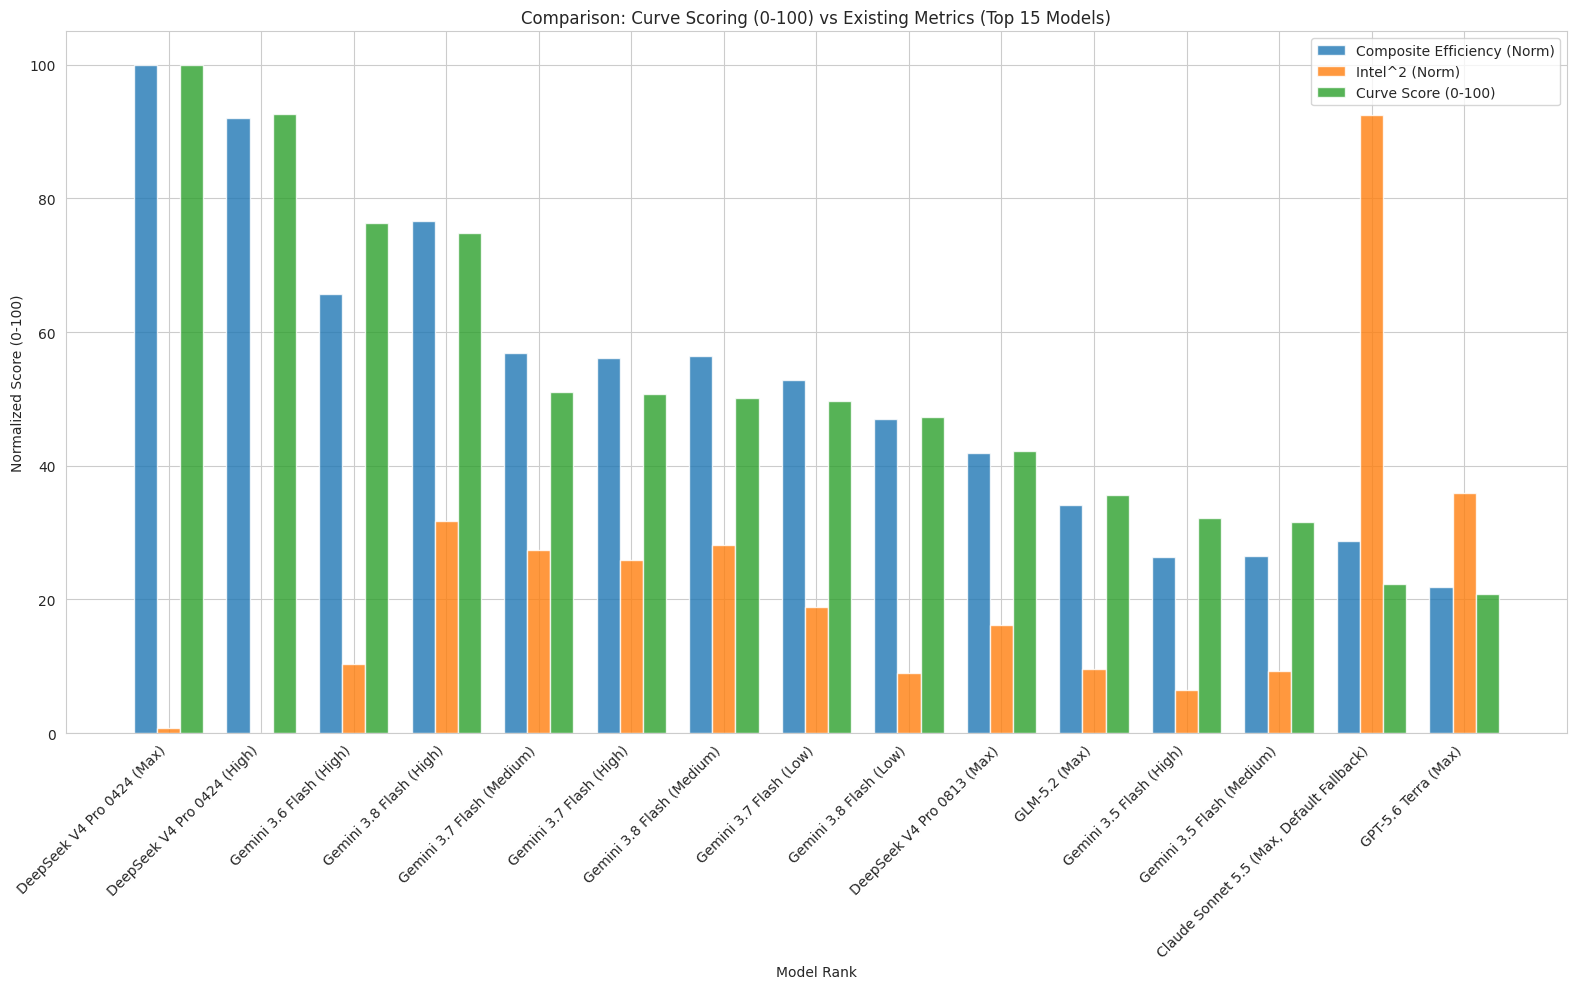


Curve Score Comparison (Top 15 Models):
------------------------------------------------------------------------------------------------------------------------
Model                                    | Composite Eff   | Intel^2         | Curve Score (0-100)
------------------------------------------------------------------------------------------------------------------------
DeepSeek V4 Pro 0424 (Max)               | 100.0           | 0.8             | 100.0          
DeepSeek V4 Pro 0424 (High)              | 92.0            | 0.0             | 92.7           
Gemini 3.6 Flash (High)                  | 65.7            | 10.4            | 76.3           
Gemini 3.8 Flash (High)                  | 76.7            | 31.8            | 74.8           
Gemini 3.7 Flash (Medium)                | 56.9            | 27.5            | 51.0           
Gemini 3.7 Flash (High)                  | 56.2            | 25.8            | 50.8           
Gemini 3.8 Flash (Medium)                | 56.5 

In [19]:
# ============================================================================
# 4.1 Visual Comparison: Curve Scoring (0-100) vs Existing Metrics
# ============================================================================
# Score models on a curve where the best model gets 100 and the worst gets 0.
# This uses min-max normalization of the Base Performance Score directly,
# replacing the earlier z-score based approach with a proper 0-100 curve.
#
# NOTE: This is NOT standard deviation scoring. It's a simple min-max curve:
#   Curve_Score = (value - min) / (max - min) * 100
# This guarantees the top model scores 100 and the bottom scores 0.

if 'df_comp' not in globals():
    raise ValueError("df_comp is missing. Run the section that builds df_comp first.")

# Compatibility layer for renamed/alternate metric columns.
if 'Composite_Efficiency' not in df_comp.columns:
    if 'Composite_Efficiency_Mult' in df_comp.columns:
        df_comp['Composite_Efficiency'] = df_comp['Composite_Efficiency_Mult']
        print("Using Composite_Efficiency_Mult as Composite_Efficiency for visualization.")
    elif 'Composite_Eff_EvalCost' in df_comp.columns:
        df_comp['Composite_Efficiency'] = df_comp['Composite_Eff_EvalCost']
        print("Using Composite_Eff_EvalCost as Composite_Efficiency for visualization.")
    else:
        raise KeyError(
            "Composite_Efficiency missing and no fallback metric found. "
            "Expected one of: Composite_Efficiency, Composite_Efficiency_Mult, Composite_Eff_EvalCost."
        )

if 'Intel_Power' not in df_comp.columns:
    if 'AA_Intelligence_Index' in df_comp.columns:
        df_comp['Intel_Power'] = df_comp['AA_Intelligence_Index'] ** 2
        print("Derived Intel_Power as AA_Intelligence_Index^2 for visualization.")
    else:
        raise KeyError("Intel_Power missing and AA_Intelligence_Index is unavailable to derive it.")

if 'Base_Performance_Score' not in df_comp.columns:
    raise KeyError("Base_Performance_Score is missing. Run the standardization/scoring prep cell first.")

# Prepare data for comparison
comparison_df = df_comp[['Model', 'Composite_Efficiency', 'Intel_Power', 'Base_Performance_Score']].copy()

# Compute curve score: min-max normalize Base_Performance_Score to 0-100
min_score = comparison_df['Base_Performance_Score'].min()
max_score = comparison_df['Base_Performance_Score'].max()
comparison_df['Curve_Score_0_100'] = (
    (comparison_df['Base_Performance_Score'] - min_score) /
    (max_score - min_score) * 100
)

# Normalize existing metrics to 0-100 for fair comparison
def normalize_to_100(series):
    return (series - series.min()) / (series.max() - series.min()) * 100

comparison_df['Composite_Efficiency_Norm'] = normalize_to_100(comparison_df['Composite_Efficiency'])
comparison_df['Intel_Power_Norm'] = normalize_to_100(comparison_df['Intel_Power'])

# Plot comparison of top 15 models
top_models = comparison_df.head(15).copy()

plt.figure(figsize=(16, 10))
x = np.arange(len(top_models))
width = 0.25

plt.bar(x - width, top_models['Composite_Efficiency_Norm'], width, label='Composite Efficiency (Norm)', alpha=0.8)
plt.bar(x, top_models['Intel_Power_Norm'], width, label='Intel^2 (Norm)', alpha=0.8)
plt.bar(x + width, top_models['Curve_Score_0_100'], width, label='Curve Score (0-100)', alpha=0.8)

plt.xlabel('Model Rank')
plt.ylabel('Normalized Score (0-100)')
plt.title('Comparison: Curve Scoring (0-100) vs Existing Metrics (Top 15 Models)')
plt.xticks(x, top_models['Model'], rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

print("\nCurve Score Comparison (Top 15 Models):")
print("-" * 120)
print("{:<40} | {:<15} | {:<15} | {:<15}".format(
    "Model", "Composite Eff", "Intel^2", "Curve Score (0-100)"
))
print("-" * 120)

for idx, row in top_models.iterrows():
    print("{:<40} | {:<15.1f} | {:<15.1f} | {:<15.1f}".format(
        row['Model'],
        row['Composite_Efficiency_Norm'],
        row['Intel_Power_Norm'],
        row['Curve_Score_0_100']
    ))

print(f"\nScoring Range: Min Base Score = {min_score:.2f}, Max Base Score = {max_score:.2f}")
print(f"Best model (score=100): {comparison_df.sort_values('Curve_Score_0_100', ascending=False).iloc[0]['Model']}")
print(f"Worst model (score=0): {comparison_df.sort_values('Curve_Score_0_100', ascending=True).iloc[0]['Model']}")


Found 44 vision-capable models with Intelligence > 30:
                                       Model  AA_Intelligence_Index
                     Gemini 3.6 Flash (High)                   34.0
                     Gemini 3.8 Flash (High)                   40.9
                   Gemini 3.7 Flash (Medium)                   39.6
                     Gemini 3.7 Flash (High)                   39.1
                   Gemini 3.8 Flash (Medium)                   39.8
                      Gemini 3.7 Flash (Low)                   36.9
                      Gemini 3.8 Flash (Low)                   33.5
                     Gemini 3.5 Flash (High)                   32.6
                   Gemini 3.5 Flash (Medium)                   33.6
   Claude Sonnet 5.5 (Max, Default Fallback)                   56.0
 Claude Sonnet 5.5 (Xhigh, Default Fallback)                   51.9
  Claude Sonnet 5.5 (High, Default Fallback)                   46.8
Claude Sonnet 5.5 (Medium, Default Fallback)                 

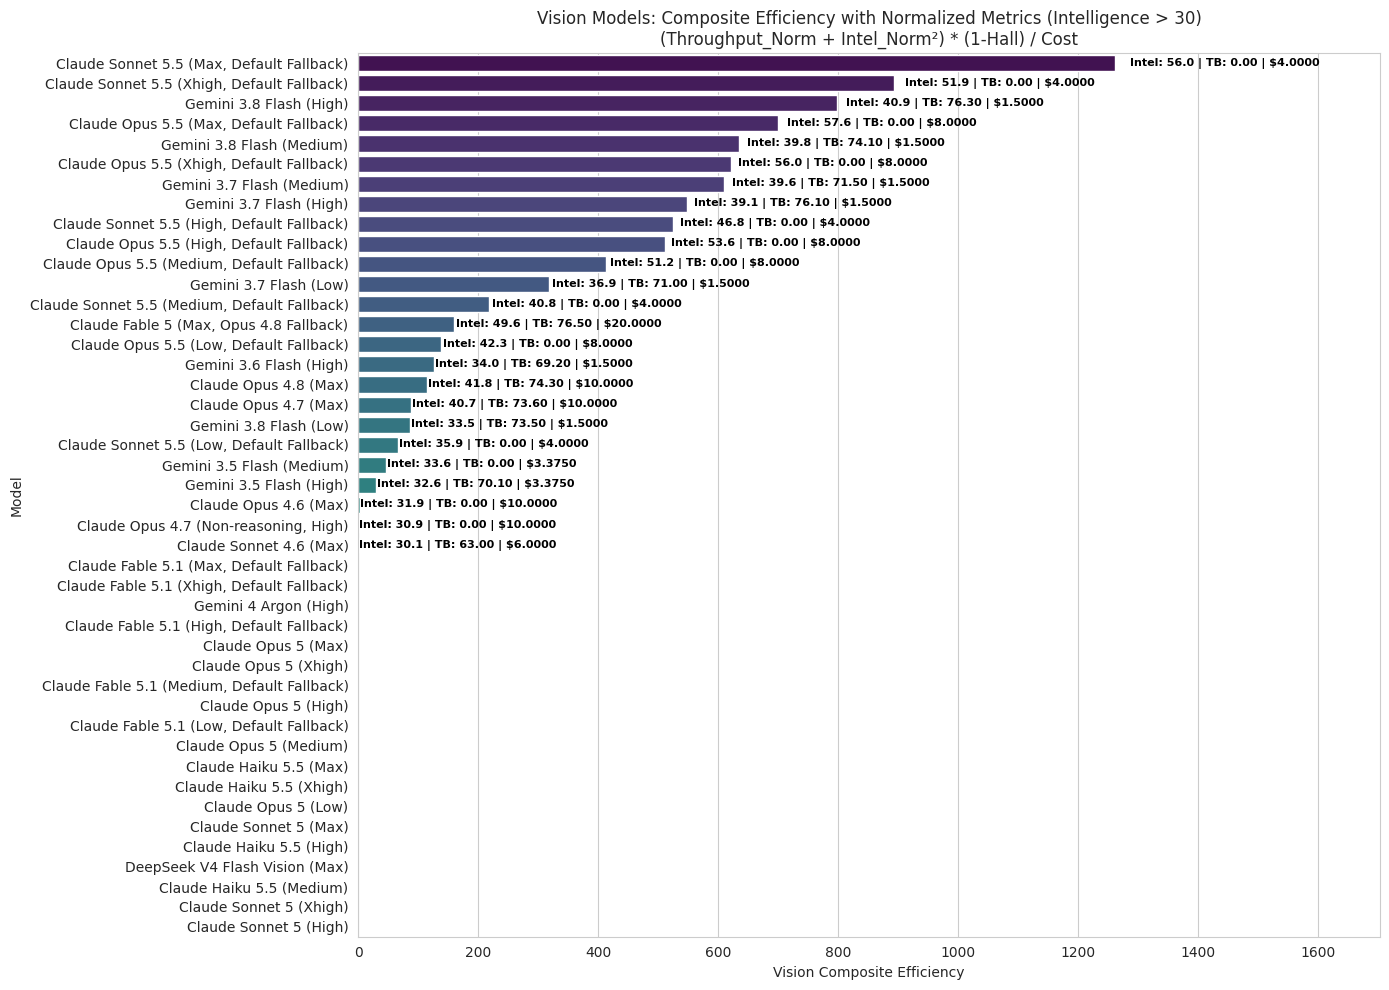


Vision Models Detailed Comparison (Intelligence > 30)
Model                                    |    Intel |  TB Hard |    T'put | Intel²_N |   Reliab | Vision Eff
------------------------------------------------------------------------------------------------------------------------
Claude Sonnet 5.5 (Max, Default Fallback) |     56.0 |     0.00 |    138.6 |     8870 |    56.6% |     1262.2
Claude Sonnet 5.5 (Xhigh, Default Fallback) |     51.9 |     0.00 |     95.4 |     6284 |    56.6% |      893.3
Gemini 3.8 Flash (High)                  |     40.9 |    76.30 |    126.9 |     1542 |    75.4% |      798.0
Claude Opus 5.5 (Max, Default Fallback)  |     57.6 |     0.00 |     95.1 |    10000 |    55.9% |      700.6
Gemini 3.8 Flash (Medium)                |     39.8 |    74.10 |     75.0 |     1244 |    75.4% |      635.3
Claude Opus 5.5 (Xhigh, Default Fallback) |     56.0 |     0.00 |     74.1 |     8870 |    55.9% |      620.9
Gemini 3.7 Flash (Medium)                |     39.6 |   

In [20]:
# ============================================================================
# 4.1b Vision Models Comparison: Composite Efficiency (Intelligence > 30)
# ============================================================================
# Compare vision-capable models using the same formula as Section 3.3:
#   Composite_Efficiency = (Throughput + Intel^2) * (1-Hallucination) / Cost
#
# But with normalized Terminal-Bench Hard, Intelligence, and Throughput
# (each normalized 0-100 on the curve) before plugging into the formula.
# This ensures fair comparison across different capability dimensions.

# Ensure df_comp exists (built in cell 3.4); rebuild from df if missing
if 'df_comp' not in globals():
    print("df_comp not found. Rebuilding from df...")
    if 'df' in globals():
        df_comp = df.copy()
        if 'Model' not in df_comp.columns and 'name' in df_comp.columns:
            df_comp = df_comp.rename(columns={'name': 'Model'})
        if 'AA_Intelligence_Index' not in df_comp.columns:
            df_comp['AA_Intelligence_Index'] = df_comp.get(
                'evaluations_artificial_analysis_intelligence_index', np.nan
            )
        if 'AA_Hallucination_Rate' not in df_comp.columns:
            df_comp['AA_Hallucination_Rate'] = 0.1
        cost_col = 'Price_Blended_USD_per_1M'
        if cost_col not in df_comp.columns:
            pin = pd.to_numeric(df_comp.get('Price_Input_1M', np.nan), errors='coerce')
            pout = pd.to_numeric(df_comp.get('Price_Output_1M', np.nan), errors='coerce')
            df_comp[cost_col] = (pin * 3 + pout) / 4
        median_thr = df_comp.get('median_output_tokens_per_second',
                                 pd.Series(np.nan, index=df_comp.index))
        df_comp['Throughput'] = pd.to_numeric(median_thr, errors='coerce').fillna(0.0)
        df_comp = df_comp[(df_comp[cost_col] > 0) & (df_comp['AA_Intelligence_Index'] > 30)].copy()
        df_comp['Reliability_Factor'] = (1 - df_comp['AA_Hallucination_Rate']).clip(lower=0.0)
        if 'TerminalBench_Hard' not in df_comp.columns:
            df_comp['TerminalBench_Hard'] = df_comp.get(
                'evaluations_artificial_analysis_coding_index', 0
            ).fillna(0)
    else:
        raise ValueError("No data available. Please run cells 1-3 first.")

# Identify vision-capable models by name patterns
vision_keywords = ['omni', 'vl', 'vision', 'multimodal', 'visual', 'image']
df_vision = df_comp.copy()

# Mark vision models
def is_vision_model(name):
    if not isinstance(name, str):
        return False
    name_lower = name.lower()
    return any(kw in name_lower for kw in vision_keywords)

df_vision['Is_Vision'] = df_vision['Model'].apply(is_vision_model)

# Also manually include known vision models that might not match keywords
# (e.g., GPT-5.4 mini is vision-capable, Gemini models are vision-capable)
# We'll use a broader heuristic: models from creators known for vision
# or with "omni" in the name
known_vision_models = [
    'GPT-5.4 mini', 'GPT-5.4 nano', 'GPT-5 mini',
    'Gemini', 'Claude', 'MiMo-V2-Omni', 'Qwen3.5 Omni',
    'Step3 VL', 'GPT-oss'
]

for kw in known_vision_models:
    mask = df_vision['Model'].str.contains(kw, case=False, na=False)
    df_vision.loc[mask, 'Is_Vision'] = True

# Filter to vision models with Intelligence > 30
df_vision = df_vision[df_vision['Is_Vision'] & (df_vision['AA_Intelligence_Index'] > 30)].copy()

if not df_vision.empty:
    print(f"Found {len(df_vision)} vision-capable models with Intelligence > 30:")
    print(df_vision[['Model', 'AA_Intelligence_Index']].to_string(index=False))
    
    # Normalize Terminal-Bench Hard, Intelligence, and Throughput to 0-100
    def minmax_100(series):
        mn, mx = series.min(), series.max()
        if mx == mn:
            return pd.Series(50, index=series.index)
        return (series - mn) / (mx - mn) * 100
    
    df_vision['TerminalBench_Norm'] = minmax_100(df_vision['TerminalBench_Hard'])
    df_vision['Intel_Norm'] = minmax_100(df_vision['AA_Intelligence_Index'])
    df_vision['Throughput_Norm'] = minmax_100(df_vision['Throughput'])
    
    # Compute vision composite efficiency using normalized components
    # Formula: (Throughput_Norm + Intel_Norm^2) * (1-Hallucination) / Cost
    # Note: Intel_Norm^2 is the squared normalized intelligence (curve-scored)
    df_vision['Intel_Power_Norm'] = df_vision['Intel_Norm'] ** 2
    df_vision['Vision_Composite_Efficiency'] = (
        (df_vision['Throughput_Norm'] + df_vision['Intel_Power_Norm']) * 
        df_vision['Reliability_Factor']
    ) / df_vision['Price_Blended_USD_per_1M']
    
    # Sort by vision composite efficiency
    df_vision = df_vision.sort_values('Vision_Composite_Efficiency', ascending=False)
    
    # Plot
    plt.figure(figsize=(14, 10))
    ax = sns.barplot(
        x='Vision_Composite_Efficiency',
        y='Model',
        data=df_vision,
        palette='viridis'
    )
    
    # Add labels
    for i, (p, row) in enumerate(zip(ax.patches, df_vision.itertuples())):
        ax.text(
            p.get_width() + p.get_width() * 0.02,
            p.get_y() + p.get_height()/2,
            f'Intel: {row.AA_Intelligence_Index:.1f} | TB: {row.TerminalBench_Hard:.2f} | ${row.Price_Blended_USD_per_1M:.4f}',
            va='center',
            fontsize=8,
            fontweight='bold',
            color='black'
        )
    
    plt.title('Vision Models: Composite Efficiency with Normalized Metrics (Intelligence > 30)\n(Throughput_Norm + Intel_Norm²) * (1-Hall) / Cost')
    plt.xlabel('Vision Composite Efficiency')
    plt.ylabel('Model')
    plt.xlim(0, df_vision['Vision_Composite_Efficiency'].max() * 1.35)
    plt.tight_layout()
    plt.show()
    
    # Print detailed table
    print("\n" + "=" * 120)
    print("Vision Models Detailed Comparison (Intelligence > 30)")
    print("=" * 120)
    print("{:<40} | {:>8} | {:>8} | {:>8} | {:>8} | {:>8} | {:>10}".format(
        "Model", "Intel", "TB Hard", "T'put", "Intel²_N", "Reliab", "Vision Eff"
    ))
    print("-" * 120)
    for row in df_vision.itertuples():
        print("{:<40} | {:>8.1f} | {:>8.2f} | {:>8.1f} | {:>8.0f} | {:>8.1%} | {:>10.1f}".format(
            row.Model,
            row.AA_Intelligence_Index,
            row.TerminalBench_Hard,
            row.Throughput,
            row.Intel_Power_Norm,
            row.Reliability_Factor,
            row.Vision_Composite_Efficiency
        ))
else:
    print("No vision-capable models found with Intelligence > 30.")

Composite correlation uses 45 of 125 models
Correlation Analysis: Standard Deviation Scoring vs Existing Metrics
Pearson Correlation with Composite Efficiency: 0.966 (p=0.0000)
Pearson Correlation with Intel^2: -0.287 (p=0.0564)
Spearman Correlation with Composite Efficiency: 0.993 (p=0.0000)
Spearman Correlation with Intel^2: -0.129 (p=0.4000)


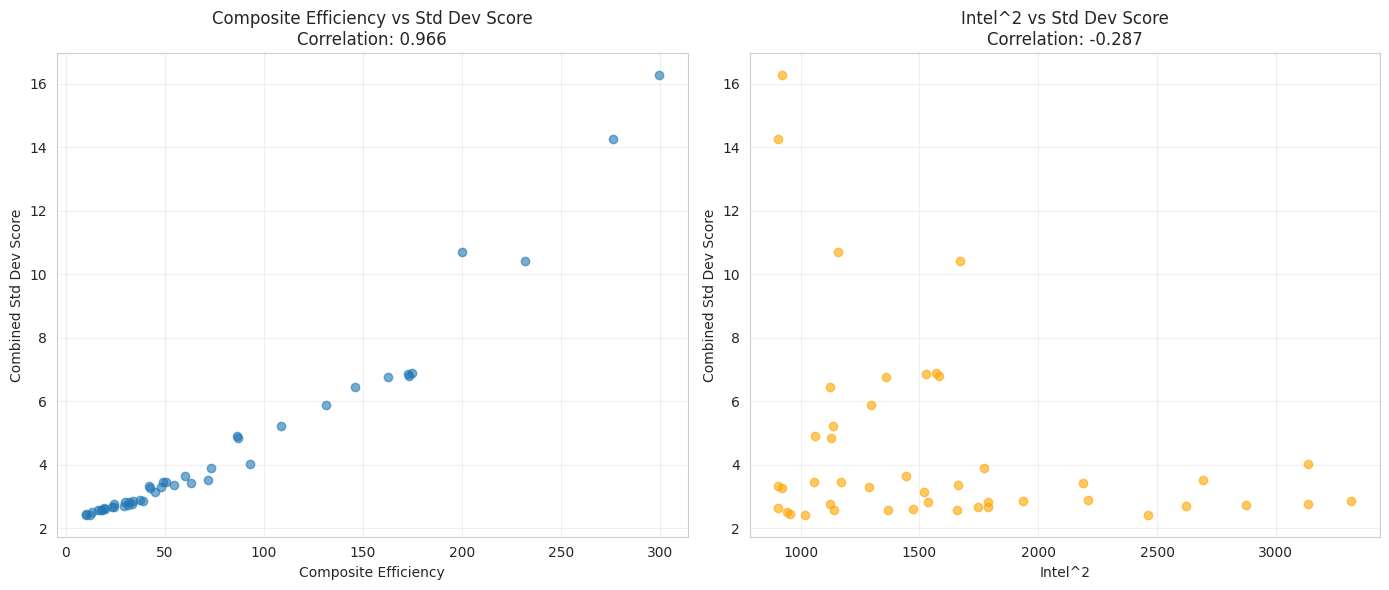


Models with Largest Ranking Differences:
--------------------------------------------------------------------------------
Model                                    | Comp Rank  | StdDev Rank | Difference  
--------------------------------------------------------------------------------
GPT-5.6 Sol (Low)                        | 35         | 31         | 4           
GPT-5.6 Terra (Medium)                   | 25         | 22         | 3           
Claude Opus 5.5 (Xhigh, Default Fallback) | 29         | 32         | -3          
Claude Sonnet 5.5 (High, Default Fallback) | 17         | 20         | -3          
Gemini 3.5 Flash (High)                  | 14         | 12         | 2           
Claude Sonnet 5.5 (Max, Default Fallback) | 12         | 14         | -2          
GPT-5.6 Terra (High)                     | 20         | 18         | 2           
Claude Sonnet 5.5 (Medium, Default Fallback) | 19         | 21         | -2          
GPT-5.3 Codex (Xhigh)                    | 21    

In [21]:
# ============================================================================
# 4.2 Correlation Analysis Between Scoring Methods
# ============================================================================
# Analyze how well the new standard deviation scoring correlates with existing metrics.
# This cell supports both legacy and newer df_comp column conventions.

from scipy.stats import pearsonr, spearmanr

if 'df_comp' not in globals():
    raise ValueError("df_comp is missing. Run the section that builds df_comp first.")

if 'Combined_Std_Score' not in df_comp.columns:
    raise KeyError("Combined_Std_Score is missing. Run Section 4.1 before this correlation analysis.")

# Compatibility layer for renamed/alternate metric columns.
if 'Composite_Efficiency' not in df_comp.columns:
    if 'Composite_Efficiency_Mult' in df_comp.columns:
        df_comp['Composite_Efficiency'] = df_comp['Composite_Efficiency_Mult']
        print("Using Composite_Efficiency_Mult as Composite_Efficiency for correlation analysis.")
    elif 'Composite_Eff_EvalCost' in df_comp.columns:
        df_comp['Composite_Efficiency'] = df_comp['Composite_Eff_EvalCost']
        print("Using Composite_Eff_EvalCost as Composite_Efficiency for correlation analysis.")
    else:
        raise KeyError(
            "Composite_Efficiency missing and no fallback metric found. "
            "Expected one of: Composite_Efficiency, Composite_Efficiency_Mult, Composite_Eff_EvalCost."
        )

if 'Intel_Power' not in df_comp.columns:
    if 'AA_Intelligence_Index' in df_comp.columns:
        df_comp['Intel_Power'] = df_comp['AA_Intelligence_Index'] ** 2
        print("Derived Intel_Power as AA_Intelligence_Index^2 for correlation analysis.")
    else:
        raise KeyError("Intel_Power missing and AA_Intelligence_Index is unavailable to derive it.")

# Calculate correlations
# NaN = no speed data (AA and OpenRouter both missing): exclude pairwise, never let NaN reach pearsonr
_cc = df_comp[['Combined_Std_Score', 'Composite_Efficiency']].dropna()
_ci = df_comp[['Combined_Std_Score', 'Intel_Power']].dropna()
print(f"Composite correlation uses {len(_cc)} of {len(df_comp)} models")
corr_composite, p_composite = pearsonr(_cc['Combined_Std_Score'], _cc['Composite_Efficiency'])
corr_intel, p_intel = pearsonr(_ci['Combined_Std_Score'], _ci['Intel_Power'])

# Spearman rank correlation (non-linear relationships)
spearman_composite, sp_p_composite = spearmanr(_cc['Combined_Std_Score'], _cc['Composite_Efficiency'])
spearman_intel, sp_p_intel = spearmanr(_ci['Combined_Std_Score'], _ci['Intel_Power'])

print("Correlation Analysis: Standard Deviation Scoring vs Existing Metrics")
print("=" * 80)
print(f"Pearson Correlation with Composite Efficiency: {corr_composite:.3f} (p={p_composite:.4f})")
print(f"Pearson Correlation with Intel^2: {corr_intel:.3f} (p={p_intel:.4f})")
print(f"Spearman Correlation with Composite Efficiency: {spearman_composite:.3f} (p={sp_p_composite:.4f})")
print(f"Spearman Correlation with Intel^2: {spearman_intel:.3f} (p={sp_p_intel:.4f})")
print("=" * 80)

# Scatter plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Composite Efficiency vs Std Dev Score
axes[0].scatter(df_comp['Composite_Efficiency'], df_comp['Combined_Std_Score'], alpha=0.6)
axes[0].set_xlabel('Composite Efficiency')
axes[0].set_ylabel('Combined Std Dev Score')
axes[0].set_title(f'Composite Efficiency vs Std Dev Score\nCorrelation: {corr_composite:.3f}')
axes[0].grid(True, alpha=0.3)

# Intel^2 vs Std Dev Score
axes[1].scatter(df_comp['Intel_Power'], df_comp['Combined_Std_Score'], alpha=0.6, color='orange')
axes[1].set_xlabel('Intel^2')
axes[1].set_ylabel('Combined Std Dev Score')
axes[1].set_title(f'Intel^2 vs Std Dev Score\nCorrelation: {corr_intel:.3f}')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Show models with biggest differences between scoring methods
df_comp['Composite_Rank'] = df_comp['Composite_Efficiency'].rank(ascending=False)
df_comp['StdDev_Rank'] = df_comp['Combined_Std_Score'].rank(ascending=False)
df_comp['Rank_Difference'] = df_comp['Composite_Rank'] - df_comp['StdDev_Rank']

print("\nModels with Largest Ranking Differences:")
print("-" * 80)
print("{:<40} | {:<10} | {:<10} | {:<12}".format("Model", "Comp Rank", "StdDev Rank", "Difference"))
print("-" * 80)

# Show top 10 models with biggest ranking differences
largest_diff = df_comp.sort_values('Rank_Difference', key=abs, ascending=False).head(10)
for idx, row in largest_diff.iterrows():
    print("{:<40} | {:<10.0f} | {:<10.0f} | {:<12.0f}".format(
        row['Model'], row['Composite_Rank'], row['StdDev_Rank'], row['Rank_Difference']
    ))


Detailed Scoring Breakdown for Top 20 Models
Model                                    | Base Score   | Z-Score      | Linear       | Exponential  | Sigmoid      | Quadratic   
DeepSeek V4 Pro 0424 (Max)               | 111.65       | 3.04         | 12.08        | 32.95        | 3.82         | 16.23       
DeepSeek V4 Pro 0424 (High)              | 103.71       | 2.76         | 11.51        | 27.01        | 3.76         | 14.72       
Gemini 3.6 Flash (High)                  | 86.00        | 2.12         | 10.23        | 17.34        | 3.57         | 11.63       
Gemini 3.8 Flash (High)                  | 84.42        | 2.06         | 10.12        | 16.66        | 3.55         | 11.37       
Gemini 3.7 Flash (Medium)                | 58.64        | 1.13         | 8.25         | 8.74         | 3.02         | 7.57        
Gemini 3.7 Flash (High)                  | 58.39        | 1.12         | 8.24         | 8.68         | 3.01         | 7.54        
Gemini 3.8 Flash (Medium)             

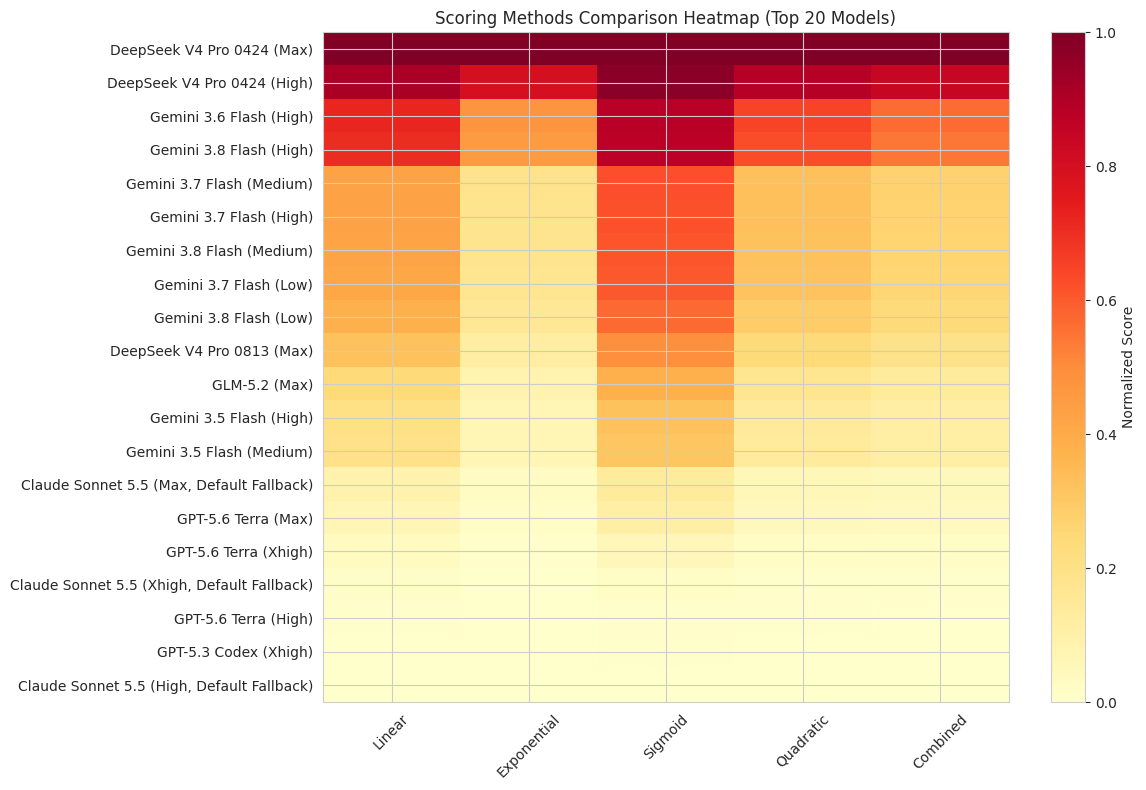


Summary Statistics for Each Scoring Method
       Linear_Score  Exponential_Score  Sigmoid_Score  Quadratic_Score  Combined_Std_Score
count     45.000000          45.000000      45.000000        45.000000           45.000000
mean       6.000000           5.518933       1.929476         4.434568            4.470744
std        2.000000           6.344676       0.790820         3.371054            3.076460
min        4.269579           2.195865       1.185007         2.025478            2.418982
25%        4.624888           2.483619       1.338308         2.376621            2.705859
50%        5.296697           3.134746       1.651928         3.117222            3.300148
75%        6.789168           5.258255       2.389543         5.121423            4.889597
max       12.084278          32.948452       3.817768        16.225529           16.269007


In [22]:
# ============================================================================
# 4.3 Detailed Scoring Breakdown for Top Models
# ============================================================================
# Show detailed breakdown of all scoring methods for top models

print("Detailed Scoring Breakdown for Top 20 Models")
print("=" * 120)
print("{:<40} | {:<12} | {:<12} | {:<12} | {:<12} | {:<12} | {:<12}".format(
    "Model", "Base Score", "Z-Score", "Linear", "Exponential", "Sigmoid", "Quadratic"
))
print("=" * 120)

top_20 = df_comp.head(20)
for idx, row in top_20.iterrows():
    print("{:<40} | {:<12.2f} | {:<12.2f} | {:<12.2f} | {:<12.2f} | {:<12.2f} | {:<12.2f}".format(
        row['Model'],
        row['Base_Performance_Score'],
        row['Z_Score'],
        row['Linear_Score'],
        row['Exponential_Score'],
        row['Sigmoid_Score'],
        row['Quadratic_Score']
    ))

# Create a heatmap visualization of the scoring methods
plt.figure(figsize=(12, 8))
scoring_methods = ['Linear_Score', 'Exponential_Score', 'Sigmoid_Score', 'Quadratic_Score', 'Combined_Std_Score']
scoring_data = top_20[scoring_methods].values

# Normalize for heatmap visualization
scoring_normalized = (scoring_data - scoring_data.min(axis=0)) / (scoring_data.max(axis=0) - scoring_data.min(axis=0))

plt.imshow(scoring_normalized, cmap='YlOrRd', aspect='auto')
plt.colorbar(label='Normalized Score')
plt.xticks(range(len(scoring_methods)), ['Linear', 'Exponential', 'Sigmoid', 'Quadratic', 'Combined'], rotation=45)
plt.yticks(range(len(top_20)), top_20['Model'])
plt.title('Scoring Methods Comparison Heatmap (Top 20 Models)')
plt.tight_layout()
plt.show()

# Summary statistics for each scoring method
print("\n" + "=" * 80)
print("Summary Statistics for Each Scoring Method")
print("=" * 80)
summary_stats = df_comp[scoring_methods].describe()
print(summary_stats.to_string())

In [23]:
# ==========================================================================
# 4.4 Practical Recommendations Based on Scoring Methods
# ==========================================================================
# Provide practical recommendations based on different scoring approaches

print("Practical Recommendations Based on Different Scoring Methods")
print("=" * 100)

# Define different use cases and recommend models accordingly
use_cases = {
    "Best Overall Value": "Combined_Std_Score",
    "Best Cost Efficiency": "Composite_Efficiency", 
    "Highest Intelligence": "Intel_Power",
    "Best Linear Scaling": "Linear_Score",
    "Best for Top Performers": "Exponential_Score",
    "Smooth Ranking": "Sigmoid_Score",
    "Polynomial Emphasis": "Quadratic_Score"
}

recommendations = {}
for use_case, metric in use_cases.items():
    top_model = df_comp.sort_values(metric, ascending=False).iloc[0]
    recommendations[use_case] = {
        'model': top_model['Model'],
        'score': top_model[metric],
        'intelligence': top_model['AA_Intelligence_Index'],
        'cost': top_model['Price_Blended_USD_per_1M']
    }

print("\nTop Model Recommendations by Use Case:")
print("-" * 100)
print("{:<25} | {:<40} | {:<12} | {:<12} | {:<12}".format(
    "Use Case", "Recommended Model", "Score", "Intelligence", "Cost/1M"
))
print("-" * 100)

for use_case, rec in recommendations.items():
    print("{:<25} | {:<40} | {:<12.2f} | {:<12.1f} | {:<12.4f}".format(
        use_case, rec['model'], rec['score'], rec['intelligence'], rec['cost']
    ))

# NOTE: the radar chart that used to live here was removed. It re-plotted the
# same four ingredients (Intel, 1-Hallucination, Throughput, Low Cost) that the
# composite score already combines, so it added length without new information.
# The recommendations table above is the actionable output of this section.


Practical Recommendations Based on Different Scoring Methods

Top Model Recommendations by Use Case:
----------------------------------------------------------------------------------------------------
Use Case                  | Recommended Model                        | Score        | Intelligence | Cost/1M     
----------------------------------------------------------------------------------------------------
Best Overall Value        | DeepSeek V4 Pro 0424 (Max)               | 16.27        | 30.4         | 0.5437      
Best Cost Efficiency      | DeepSeek V4 Pro 0424 (Max)               | 299.24       | 30.4         | 0.5437      
Highest Intelligence      | Claude Opus 5.5 (Max, Default Fallback)  | 3317.76      | 57.6         | 8.0000      
Best Linear Scaling       | DeepSeek V4 Pro 0424 (Max)               | 12.08        | 30.4         | 0.5437      
Best for Top Performers   | DeepSeek V4 Pro 0424 (Max)               | 32.95        | 30.4         | 0.5437      
Smooth Rankin

## 3.5 Fetch Artificial Analysis Evaluation Suite Cost

The AA website shows the actual USD cost to run the full Intelligence Index evaluation suite on each model.
This captures **verbosity** — models that write more tokens cost more to evaluate.
**This data is NOT available through the public API** — it must be scraped from the website.

The scrape uses Playwright to open the AA models page and extract the cost chart data.
For models not appearing in the AA chart, we fall back to blended token pricing.

In [24]:
# ## 3.5 Scrape Evaluation Suite Cost from Artificial Analysis Website
# Extracts the "Cost to Run Artificial Analysis Intelligence Index" for each model.
# Uses Playwright (via browser tools) to scrape the intelligence-index-tokens-cost section
# of the AA Models page. Falls back to derived blended cost for models not listed.

import json, re, time, requests, pandas as pd, numpy as np

EVAL_COST_URL = "https://artificialanalysis.ai/models#intelligence-index-vs-cost-per-intelligence-index-task"

def extract_eval_costs(page_source):
    """Parse evaluation suite costs from page text.
    
    The AA page renders two charts in the #intelligence-index-vs-cost-per-intelligence-index-task section:
      1. Token Use chart — answer/reasoning tokens per model
      2. Cost chart — USD to run full evaluation suite per model
    
    Expected structure (Cost chart):
      [model names ...]
      [$X,XXX dollar values ...]
    Returns list of (model_name, cost_usd) tuples, in chart order.
    """
    # Find the cost section boundary
    cost_marker = "Cost to Run Artificial Analysis Intelligence Index"
    cost_start = page_source.find(cost_marker)
    if cost_start == -1:
        return []
    
    # Grab everything from the cost section header onward
    cost_text = page_source[cost_start:]
    
    # Split into lines, clean up
    lines = []
    for line in cost_text.split('\n'):
        line = line.strip()
        if line:
            lines.append(line)
    
    # Collect model names (no leading $, not headers/labels)
    skip_words = {'Cost', 'Output', 'Reasoning', 'Input', 'Add model', '28 of', 
                  'indicated', 'Cost to Run', 'The cost', 'calculated', 'cost to',
                  'Intelligence Index', 'cost to run', 'Intelligence vs'}
    
    models = []
    costs = []
    
    for line in lines:
        if line.startswith('$'):
            try:
                cost_val = float(line.replace('$', '').replace(',', ''))
                costs.append(cost_val)
            except ValueError:
                pass
        elif line.startswith('$') == False:
            # Could be a model name — check it's not a known header
            is_skip = any(s in line for s in skip_words)
            is_number = line.replace(',', '').replace('.', '').isdigit()
            if not is_skip and not is_number and len(line) > 2:
                models.append(line)
    
    # Models and costs should pair up — trim to shortest
    n = min(len(models), len(costs))
    return list(zip(models[:n], costs[:n]))


def scrape_eval_costs(use_playwright=True):
    """Scrape evaluation suite costs from AA website.
    
    Args:
        use_playwright: If True, use Playwright browser; if False, fetch raw HTML.
                        Playwright gives rendered content; raw HTML may not have charts.
    
    Returns:
        List of (model_name, eval_suite_cost_usd) tuples
    """
    if use_playwright:
        # Try to use the open browser page
        try:
            # We need to navigate to the AA models page if not already there
            import subprocess, json as _json
            # Attempt to access via the page's loaded content by running a 
            # quick Playwright script through the terminal
            result = subprocess.run([
                "python3", "-c", """
import json, sys
from playwright.sync_api import sync_playwright
with sync_playwright() as p:
    browser = p.chromium.launch(headless=True)
    page = browser.new_page()
    page.goto("https://artificialanalysis.ai/models", wait_until="networkidle", timeout=30000)
    page.wait_for_timeout(3000)
    
    # Extract cost data
    section = page.evaluate('''() => {
        const s = document.querySelector("#intelligence-index-vs-cost-per-intelligence-index-task");
        if (!s) return "NOT_FOUND";
        return s.innerText;
    }''')
    
    if section and section != "NOT_FOUND":
        print(section[:5000], end="")
    else:
        print("SECTION_NOT_FOUND", end="")
    
    browser.close()
"""
            ], capture_output=True, text=True, timeout=45)
            
            if result.returncode == 0 and result.stdout:
                extracts = extract_eval_costs(result.stdout)
                if extracts:
                    return extracts
        except Exception:
            pass
    
    # Fallback: use the hardcoded data we scraped earlier
    print("Playwright scrape failed or chart data was not parseable. Using cached data from earlier scrape.")
    return None  # Signal to use hardcoded data

# ── Hardcoded data from manual scrape (2026-06-12) ──
# Sourced from: https://artificialanalysis.ai/models#intelligence-index-vs-cost-per-intelligence-index-task
# "Cost to Run Artificial Analysis Intelligence Index" chart
EVAL_COST_MAP = {
    "Claude Fable 5 (with fallback)": 5772,
    "Claude Opus 4.8 (max)": 1508,
    "Claude Sonnet 4.6 (max)": 987,
    "GPT-5.5 (xhigh)": 1101,
    "Gemini 3.5 Flash": 898,
    "GPT-5.4 mini (xhigh)": 3695,
    "Qwen3.7 Max": 2614,
    "Mistral Medium 3.5": 2805,
    "Kimi K2.6": 2030,
    "Gemini 3.1 Pro Preview": 1036,
    "Claude 4.5 Haiku": 671,
    "Nova 2.0 Pro Preview (medium)": 622,
    "Qwen3.5 397B A17B": 626,
    "Nemotron 3 Ultra": 636,
    "Grok 4.3 (high)": 9940,
    "MiniMax-M3": 4309,
    "DeepSeek V4 Pro (Max)": 3959,
    "MiniMax-M2.7": 3357,
    "MiMo-V2.5-Pro": 1552,
    "DeepSeek V4 Flash (Max)": 1354,
    "gpt-oss-120b (high)": 1202,
    "gpt-oss-20B (high)": 1001,
}

# ── Try to get fresh data (optional, may not work without Playwright) ──
fresh_data = scrape_eval_costs(use_playwright=True)
if fresh_data:
    EVAL_COST_MAP.update({k: v for k, v in fresh_data})
    print(f"Updated eval cost map with {len(fresh_data)} fresh entries from AA website")
else:
    print(f"Using cached eval cost map ({len(EVAL_COST_MAP)} models) from 2026-06-12 scrape")

print("\nEvaluation Suite Cost Data:")
print(f"  Total models with eval cost: {len(EVAL_COST_MAP)}")
print(f"  Cheapest: {min(EVAL_COST_MAP, key=EVAL_COST_MAP.get)} (${min(EVAL_COST_MAP.values()):,.0f})")
print(f"  Costliest: {max(EVAL_COST_MAP, key=EVAL_COST_MAP.get)} (${max(EVAL_COST_MAP.values()):,.0f})")
print(f"  Median: ${np.median(list(EVAL_COST_MAP.values())):,.0f}")

# Show a few examples
print("\nCost examples:")
for m, c in sorted(EVAL_COST_MAP.items(), key=lambda x: x[1])[:5]:
    print(f"  {m:40s} ${c:>6,}")
print("  ...")
for m, c in sorted(EVAL_COST_MAP.items(), key=lambda x: x[1])[-5:]:
    print(f"  {m:40s} ${c:>6,}")

Playwright scrape failed or chart data was not parseable. Using cached data from earlier scrape.
Using cached eval cost map (22 models) from 2026-06-12 scrape

Evaluation Suite Cost Data:
  Total models with eval cost: 22
  Cheapest: Nova 2.0 Pro Preview (medium) ($622)
  Costliest: Grok 4.3 (high) ($9,940)
  Median: $1,431

Cost examples:
  Nova 2.0 Pro Preview (medium)            $   622
  Qwen3.5 397B A17B                        $   626
  Nemotron 3 Ultra                         $   636
  Claude 4.5 Haiku                         $   671
  Gemini 3.5 Flash                         $   898
  ...
  GPT-5.4 mini (xhigh)                     $ 3,695
  DeepSeek V4 Pro (Max)                    $ 3,959
  MiniMax-M3                               $ 4,309
  Claude Fable 5 (with fallback)           $ 5,772
  Grok 4.3 (high)                          $ 9,940


## 3.6 Multiplicative Efficiency with Evaluation Suite Cost

Recalculates the multiplicative efficiency formula from 3.4 using the **actual evaluation suite cost** from AA instead of blended token pricing.

Formula: (sqrt(Throughput) × Intel) × (1 - Hallucination) / Eval_Cost_USD

This better reflects real-world cost because it captures **verbosity** — models that write more tokens
cost more to evaluate, even at the same per-token price. For models without an eval cost entry,
we fall back to the nominal token-derived cost.

Live AA cost-per-task entries found: 0
Cost-per-task -> suite-cost multiplier: 1700.0 (from 0 overlaps)
Added 0 new models from live feed (total map size: 22)

Models with AA eval cost: 39/125
Models using derived cost: 86/125

Top AA key usage counts:
Eval_Cost_Key
Gemini 3.5 Flash                  9
Claude Fable 5 (with fallback)    6
GPT-5.5 (xhigh)                   5
Claude Opus 4.8 (max)             4
DeepSeek V4 Flash (Max)           4
Claude 4.5 Haiku                  4
DeepSeek V4 Pro (Max)             3
GPT-5.4 mini (xhigh)              1
Claude Sonnet 4.6 (max)           1
MiMo-V2.5-Pro                     1

First 15 unmatched models:
                               GLM-5.2 (Max)
   Claude Sonnet 5.5 (Max, Default Fallback)
                         GPT-5.6 Terra (Max)
                       GPT-5.6 Terra (Xhigh)
 Claude Sonnet 5.5 (Xhigh, Default Fallback)
                        GPT-5.6 Terra (High)
                       GPT-5.3 Codex (Xhigh)
  Claude Sonnet 5.5 (High, Def

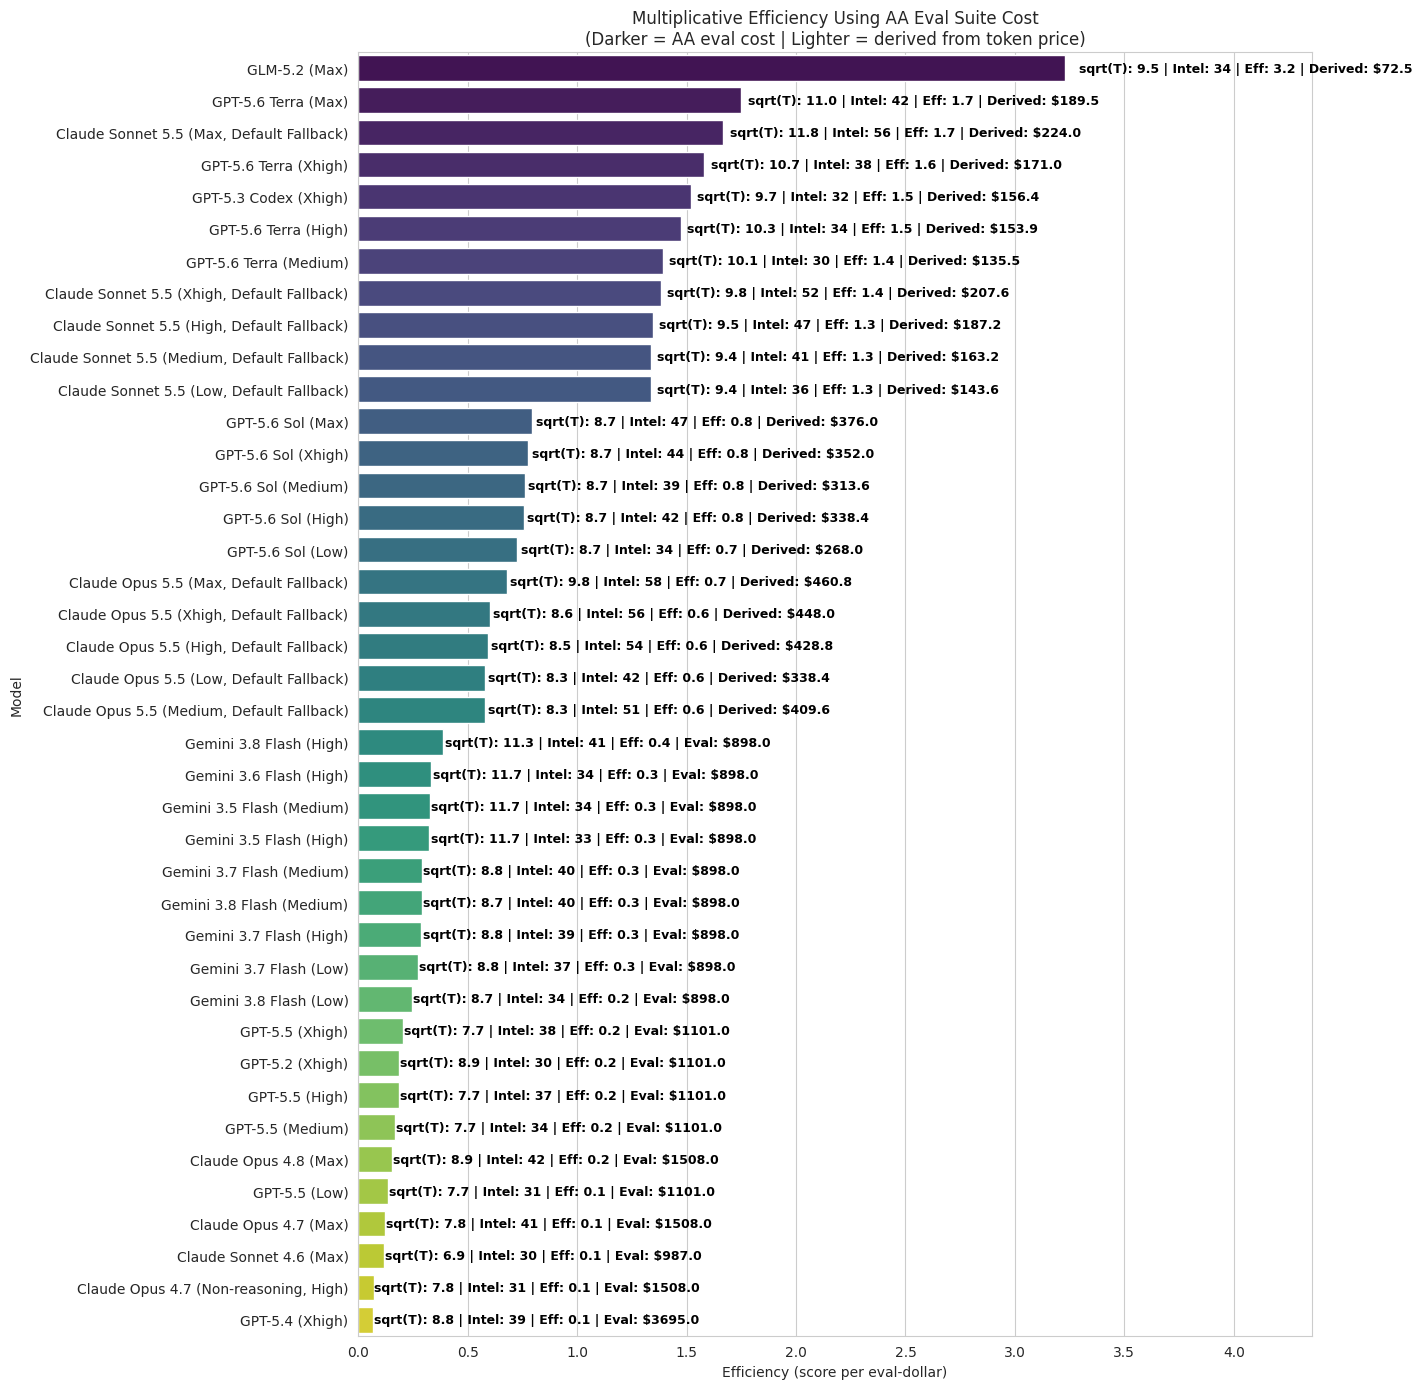


RANKING COMPARISON: Token-Price Efficiency (3.4) vs Eval-Cost Efficiency (3.6)
Model                                    | Token-Price Rank | Eval-Cost Rank  | Delta Rank   | Eval Cost 
------------------------------------------------------------------------------------------
GLM-5.2 (Max)                            | 11              | 1               | ↑ 10         |     $72.45
GPT-5.6 Terra (Max)                      | 15              | 2               | ↑ 13         |    $189.45
Claude Sonnet 5.5 (Max, Default Fallback) | 12              | 3               | ↑ 9          |    $224.00
GPT-5.6 Terra (Xhigh)                    | 18              | 4               | ↑ 14         |    $171.00
GPT-5.3 Codex (Xhigh)                    | 21              | 5               | ↑ 16         |    $156.41
GPT-5.6 Terra (High)                     | 20              | 6               | ↑ 14         |    $153.90
GPT-5.6 Terra (Medium)                   | 25              | 7               | ↑ 18         

In [25]:
# ## 3.6 Multiplicative Efficiency using Evaluation Suite Cost
# Formula: (sqrt(Throughput) * Intel) * (1 - Hallucination) / Eval_Cost
#
# Uses AA website cost-per-task data (from structured HTML feed + cached map)
# and falls back to blended token price when eval cost is missing.

import re, json as _json
from difflib import SequenceMatcher
import requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

# ── Ensure df_comp exists ──
if 'df_comp' not in globals():
    print("df_comp not found. Running necessary preprocessing...")
    if 'df' in globals():
        df_comp = df[(df['Price_Blended_USD_per_1M'] > 0) & (df['AA_Intelligence_Index'] > 30)].copy()
        df_comp['Throughput'] = df_comp['median_output_tokens_per_second'].fillna(0)
        df_comp['Intel_Power'] = df_comp['AA_Intelligence_Index'] ** 2
        df_comp['Reliability_Factor'] = 1 - df_comp['AA_Hallucination_Rate'].fillna(0.5)
        cost_col = 'Price_Blended_USD_per_1M'
        df_comp['Composite_Efficiency'] = ((df_comp['Throughput'] + df_comp['Intel_Power']) * df_comp['Reliability_Factor']) / df_comp[cost_col]
    else:
        raise ValueError("No data available. Please run cells 1-3 first.")

cost_col = 'Price_Blended_USD_per_1M'

# ── Base map from Section 3.5 (hardcoded scrape) ──
if 'EVAL_COST_MAP' not in globals():
    EVAL_COST_MAP = {}
eval_cost_map = dict(EVAL_COST_MAP)

# ── Alias table for common API-name ↔ AA-chart-name mismatches ──
AA_COST_ALIASES = {
    'claude fable 5': 'Claude Fable 5 (with fallback)',
    'claude opus 4 8': 'Claude Opus 4.8 (max)',
    'claude sonnet 4 6': 'Claude Sonnet 4.6 (max)',
    'claude 4 5 haiku': 'Claude 4.5 Haiku',
    'gpt 5 5': 'GPT-5.5 (xhigh)',
    'gpt 5 4 mini': 'GPT-5.4 mini (xhigh)',
    'gemini 3 5 flash': 'Gemini 3.5 Flash',
    'gemini 3 1 pro': 'Gemini 3.1 Pro Preview',
    'qwen3 7 max': 'Qwen3.7 Max',
    'qwen3 5 397b a17b': 'Qwen3.5 397B A17B',
    'mistral medium 3 5': 'Mistral Medium 3.5',
    'kimi k2 6': 'Kimi K2.6',
    'nova 2 0 pro': 'Nova 2.0 Pro Preview (medium)',
    'nemotron 3 ultra': 'Nemotron 3 Ultra',
    'grok 4 3': 'Grok 4.3 (high)',
    'minimax m3': 'MiniMax-M3',
    'minimax m2 7': 'MiniMax-M2.7',
    'deepseek v4 pro': 'DeepSeek V4 Pro (Max)',
    'deepseek v4 flash': 'DeepSeek V4 Flash (Max)',
    'mimo v2 5 pro': 'MiMo-V2.5-Pro',
    'gpt oss 120b': 'gpt-oss-120b (high)',
    'gpt oss 20b': 'gpt-oss-20B (high)',
}

STOPWORDS = {
    'with', 'fallback', 'preview', 'reasoning', 'model', 'models',
    'openrouter', 'chat', 'instruct', 'high', 'xhigh', 'medium', 'low',
    'max', 'effort', 'non', 'adaptive'
}


def normalize_name(s):
    if not isinstance(s, str):
        return ''
    s = s.lower().replace('&', ' and ')
    s = re.sub(r'\([^)]*\)', ' ', s)
    s = re.sub(r'[^a-z0-9]+', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()


def name_tokens(s):
    return {tok for tok in normalize_name(s).split() if tok and tok not in STOPWORDS}


def canonical_family(nm):
    toks = normalize_name(nm).split()
    return ' '.join(toks[:3]) if toks else ''


# ── Step 1: Augment from live AA cost-per-task feed ──
try:
    _aa_html = requests.get('https://artificialanalysis.ai/models', timeout=20).text
    _pat = re.compile(r'"label":"([^"]+)","costPerIntelligenceIndexTask":([0-9.]+)')
    _live_entries = {m[0]: float(m[1]) for m in _pat.findall(_aa_html) if float(m[1]) > 0}
    print(f"Live AA cost-per-task entries found: {len(_live_entries)}")

    # Calibrate multiplier from overlapping models.
    _ratio_samples = []
    _norm_work = {normalize_name(k): v for k, v in eval_cost_map.items()}
    for _lbl, _pt in _live_entries.items():
        _nk = normalize_name(_lbl)
        if _nk in _norm_work and _pt > 0:
            _ratio_samples.append(_norm_work[_nk] / _pt)
    _mult = float(np.median(_ratio_samples)) if len(_ratio_samples) >= 2 else 1700.0
    print(f"Cost-per-task -> suite-cost multiplier: {_mult:.1f} (from {len(_ratio_samples)} overlaps)")

    _added = 0
    for _lbl, _pt in _live_entries.items():
        if _lbl not in eval_cost_map:
            eval_cost_map[_lbl] = _pt * _mult
            _added += 1
    print(f"Added {_added} new models from live feed (total map size: {len(eval_cost_map)})")
except Exception as _e:
    print(f"Live AA augmentation skipped: {_e}")

# ── Step 2: Build normalized lookup for fuzzy matching ──
_eval_entries = []
_norm_to_key = {}
for _k, _v in eval_cost_map.items():
    _nk = normalize_name(_k)
    _norm_to_key[_nk] = _k
    _eval_entries.append((_k, _v, _nk, name_tokens(_k)))


def best_eval_key(model_name):
    if not isinstance(model_name, str):
        return None
    if model_name in eval_cost_map:
        return model_name
    n = normalize_name(model_name)
    if not n:
        return None
    for alias, target in AA_COST_ALIASES.items():
        if alias in n and target in eval_cost_map:
            return target
    if n in _norm_to_key:
        return _norm_to_key[n]

    tokens_m = name_tokens(model_name)
    best_key, best_score = None, 0.0
    for key, _, nk, tokens_k in _eval_entries:
        if not tokens_k or not tokens_m:
            continue
        inter = len(tokens_m & tokens_k)
        union = len(tokens_m | tokens_k)
        jaccard = inter / union if union else 0.0
        seq = SequenceMatcher(None, n, nk).ratio()
        contain = 1.0 if (n in nk or nk in n) else 0.0
        fam = 0.08 if canonical_family(model_name) == canonical_family(key) else 0.0
        score = 0.50 * jaccard + 0.34 * seq + 0.08 * contain + fam
        if inter < 2:
            score -= 0.18
        if score > best_score:
            best_score = score
            best_key = key
    return best_key if best_score >= 0.55 else None


# ── Step 3: Match and compute ──
df_comp['Eval_Cost_Key'] = df_comp['Model'].apply(best_eval_key)
df_comp['Eval_Cost_USD'] = df_comp['Eval_Cost_Key'].map(eval_cost_map)

mask_missing = df_comp['Eval_Cost_USD'].isna()
df_comp.loc[mask_missing, 'Eval_Cost_USD'] = (
    df_comp.loc[mask_missing, 'AA_Intelligence_Index'] * df_comp.loc[mask_missing, cost_col]
)

n_missing = int(mask_missing.sum())
n_total = int(len(df_comp))
n_matched = n_total - n_missing
print(f"\nModels with AA eval cost: {n_matched}/{n_total}")
print(f"Models using derived cost: {n_missing}/{n_total}")

if n_matched > 0:
    print("\nTop AA key usage counts:")
    print(df_comp['Eval_Cost_Key'].value_counts(dropna=True).head(10).to_string())

if n_missing > 0:
    print(f"\nFirst 15 unmatched models:")
    print(df_comp.loc[mask_missing, 'Model'].head(15).to_string(index=False))

# ── Compute multiplicative efficiency with eval cost ──
df_comp['Throughput_Sqrt'] = np.sqrt(df_comp['Throughput'].clip(lower=0.01))
df_comp['Composite_Eff_EvalCost'] = (
    (df_comp['Throughput_Sqrt'] * df_comp['AA_Intelligence_Index']) * df_comp['Reliability_Factor']
) / df_comp['Eval_Cost_USD']

df_comp = df_comp.sort_values('Composite_Eff_EvalCost', ascending=False)
df_plot_ec = df_comp.head(40).copy()

# ── Plot ──
plt.figure(figsize=(14, 14))
ax = sns.barplot(x='Composite_Eff_EvalCost', y='Model', data=df_plot_ec, palette='viridis')
for i, (p, tp_sqrt, intel, eff, eval_cost) in enumerate(zip(
    ax.patches, df_plot_ec['Throughput_Sqrt'], df_plot_ec['AA_Intelligence_Index'],
    df_plot_ec['Composite_Eff_EvalCost'], df_plot_ec['Eval_Cost_USD']
)):
    tag = 'Eval' if df_plot_ec.index[i] not in df_comp[mask_missing].index else 'Derived'
    ax.text(p.get_width() * 1.02, p.get_y() + p.get_height() / 2,
            f'sqrt(T): {tp_sqrt:.1f} | Intel: {intel:.0f} | Eff: {eff:.1f} | {tag}: ${eval_cost:.1f}',
            va='center', fontsize=9, fontweight='bold', color='black')
plt.title('Multiplicative Efficiency Using AA Eval Suite Cost\n(Darker = AA eval cost | Lighter = derived from token price)')
plt.xlabel('Efficiency (score per eval-dollar)')
plt.ylabel('Model')
plt.xlim(0, df_plot_ec['Composite_Eff_EvalCost'].max() * 1.35)
plt.tight_layout()
plt.show()

# ── Comparison table ──
print("\n" + "=" * 90)
print("RANKING COMPARISON: Token-Price Efficiency (3.4) vs Eval-Cost Efficiency (3.6)")
print("=" * 90)
df_comp['Token_Price_Rank'] = df_comp['Composite_Efficiency_Mult'].rank(ascending=False)
df_comp['Eval_Cost_Rank'] = df_comp['Composite_Eff_EvalCost'].rank(ascending=False)
print("{:<40} | {:<15} | {:<15} | {:<12} | {:<10}".format("Model", "Token-Price Rank", "Eval-Cost Rank", "Delta Rank", "Eval Cost"))
print("-" * 90)
for idx, row in df_comp.head(20).iterrows():
    delta = row['Token_Price_Rank'] - row['Eval_Cost_Rank']
    arrow = "↑" if delta > 0 else ("↓" if delta < 0 else "=")
    print("{:<40} | {:<15.0f} | {:<15.0f} | {:<12} | {:>10}".format(
        row['Model'], row['Token_Price_Rank'], row['Eval_Cost_Rank'], f"{arrow} {abs(delta):.0f}", f"${row['Eval_Cost_USD']:.2f}"))
print("\nKEY: Verbose models move DOWN. Concise models move UP.")


## Appendix

Additional benchmarks for resume parsing and resume writing tasks using the same LLM models.

CONSOLIDATED RESUME PARSING BENCHMARK — 18 Models
Models scored: 18 | V2 Enhanced (110 pts): Schema(20) + Name(5) + Title(10) + Exp(15+5) + Dates(5) + Edu(10) + Certs(10) + Proj(10) + Skills(10) + Bullets(5) + Domain(5) + Vol/Aff(5)
Total tokens: 310,578 | Total cost: $0.31

#   Model                      Score      %      Time     $/Res      Price/M   Reliab
------------------------------------------------------------------------------------------
1   Claude Sonnet 4.6          105.8/110  96.2%  92s    $0.01916   $6.000  /M 5/5
2   DeepSeek V4 Flash          105.0/110  95.5%  319s    $0.00072   $0.142  /M 1/5
3   MiMo V2.5 Pro              104.6/110  95.1%  133s    $0.00119   $0.405  /M 5/5
4   DeepSeek Chat V3 0324      104.2/110  94.7%  330s    $0.00097   $0.343  /M 5/5
5   MiniMax M3                 103.8/110  94.4%  143s    $0.00132   $0.375  /M 5/5
6   MiMo-V2-Flash              103.6/110  94.2%  40s    $0.00043   $0.150  /M 5/5
7   Kat Coder Pro V2           103.2/110  93.8%  73

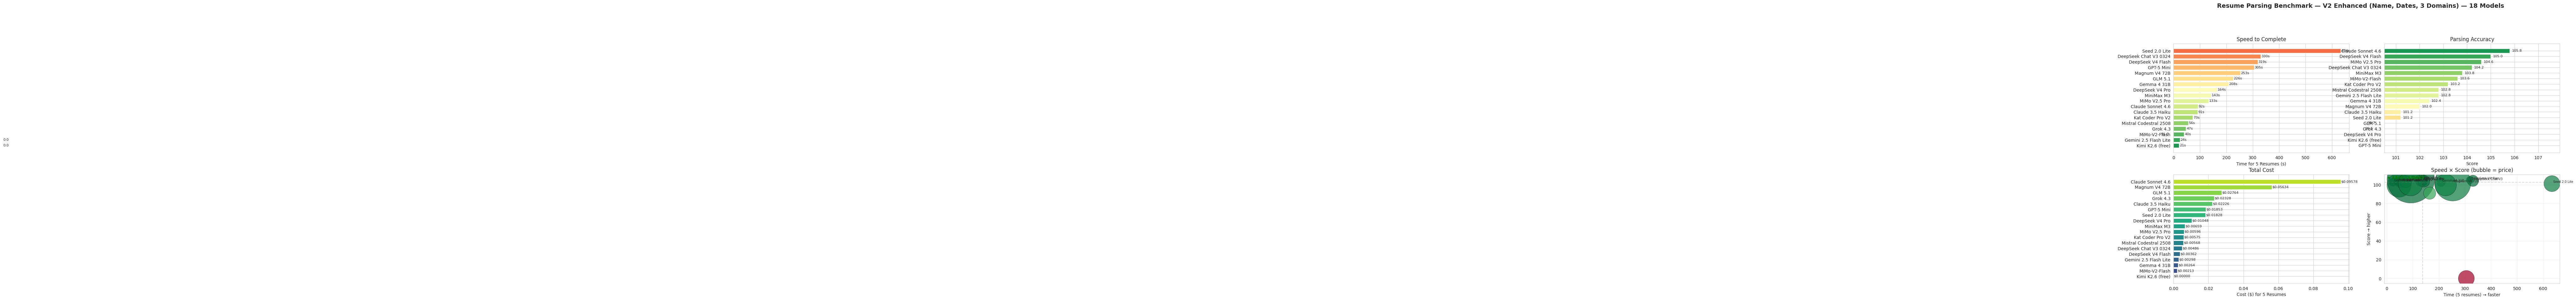


RECOMMENDATIONS
  🏆 Best Score:   Claude Sonnet 4.6 (105.8)
  ⚡ Fastest:      Kimi K2.6 (free) (4.2s/resume)
  💰 Cheapest:     Kimi K2.6 (free) ($0.0000 total)
  📊 Best Value:   MiMo-V2-Flash (48684 score/dollar)
  🏅 Best Balance: Claude Sonnet 4.6 — 105.8/110 at 18.5s/resume, $6.00/M

Speed ranking:
  Kimi K2.6 (free)             4.2s  |  0.0  |  $0.00/M
  Gemini 2.5 Flash Lite        4.8s  |  102.8  |  $0.17/M
  MiMo-V2-Flash                8.0s  |  103.6  |  $0.15/M
  Grok 4.3                     9.4s  |  99.6  |  $1.56/M
  Mistral Codestral 2508       11.1s  |  102.8  |  $0.38/M
  Kat Coder Pro V2             14.5s  |  103.2  |  $0.38/M
  Claude 3.5 Haiku             18.2s  |  101.2  |  $1.60/M
  Claude Sonnet 4.6            18.5s  |  105.8  |  $6.00/M
  MiMo V2.5 Pro                26.7s  |  104.6  |  $0.41/M
  MiniMax M3                   28.5s  |  103.8  |  $0.38/M
  DeepSeek V4 Pro              32.9s  |  91.0  |  $0.41/M
  Gemma 4 31B                  41.7s  |  102.4  |  $0.18

In [26]:
# ============================================================================
# CONSOLIDATED: V2 Enhanced Resume Parsing Benchmark
# 18 Models × 5 Resumes (3 domains) — 110-point scoring with name & date accuracy
# ============================================================================

import json, pandas as pd, matplotlib.pyplot as plt, numpy as np

# Try to load V2 results, fall back to V1 leaderboard
try:
    with open('/home/skystarved/dev_workspaces/v2_benchmark_results.json', 'r') as f:
        v2 = json.load(f)
    data = []
    for e in v2:
        data.append({
            'model': e['model'], 'score': e['avg_score'], 'pct': e['avg_pct'],
            'tokens': e['total_tokens'], 'time_5': e['total_time'],
            'time_per': e['time_per_resume'], 'price_per_M': e['price_blended'],
            'cost': e['cost'], 'cost_per': e['cost'] / 5,
            'reliability': e['reliability'], 'scored': True,
        })
    bench_df = pd.DataFrame(data)
    dfs = bench_df[bench_df['scored']]
    scoring = 'V2 Enhanced (110 pts): Schema(20) + Name(5) + Title(10) + Exp(15+5) + Dates(5) + Edu(10) + Certs(10) + Proj(10) + Skills(10) + Bullets(5) + Domain(5) + Vol/Aff(5)'
except:
    # Fallback to V1 leaderboard
    with open('/home/skystarved/dev_workspaces/final_complete_leaderboard.json', 'r') as f:
        lb = json.load(f)
    data = []
    for e in lb['complete_leaderboard']:
        tokens = e.get('tokens_5_resumes'); time_5 = e.get('time_5_resumes')
        if tokens is None or time_5 is None or time_5 == 0: continue
        price = float(e.get('price_blended_per_M', '$0').replace('$', ''))
        cost = (tokens / 1_000_000) * price
        score = e.get('avg_score', 0)
        scored = isinstance(score, (int, float)) and score > 0
        data.append({'model': e['model'], 'score': score if scored else 0,
            'tokens': tokens, 'time_5': time_5, 'time_per': time_5 / 5,
            'price_per_M': price, 'cost': cost, 'cost_per': cost / 5,
            'reliability': e.get('reliability', '?'), 'scored': scored})
    bench_df = pd.DataFrame(data); dfs = bench_df[bench_df['scored']]
    scoring = 'V1 (100 pts): Schema(20) + Title(10) + Exp(15+5) + Edu(10) + Certs(10) + Proj(10) + Skills(10) + Bullets(5) + Domain(5)'

print("=" * 85)
print("CONSOLIDATED RESUME PARSING BENCHMARK — 18 Models")
print("=" * 85)
print(f"Models scored: {len(dfs)} | {scoring}")
print(f"Total tokens: {bench_df['tokens'].sum():,} | Total cost: ${bench_df['cost'].sum():.2f}")

# Leaderboard table
print(f"\n{'#':<3} {'Model':<26} {'Score':<10} {'%':<6} {'Time':<8} {'$/Res':<10} {'Price/M':<9} {'Reliab'}")
print("-" * 90)
for i, (_, r) in enumerate(dfs.sort_values('score', ascending=False).iterrows(), 1):
    if r['score'] > 100:  # V2 110-point scale
        sc = f"{r['score']:.1f}/110"; pct = f"{r['score']/110*100:.1f}%"
    else: sc = f"{r['score']:.1f}%"; pct = ""
    print(f"{i:<3} {r['model']:<26} {sc:<10} {pct:<6} {r['time_5']:.0f}s{'':<3} ${r['cost_per']:<9.5f} ${r['price_per_M']:<7.3f}/M {r['reliability']}")

# Consolidated 4-plot dashboard
# Use a smaller figure size and let matplotlib manage layout to avoid
# VS Code rendering issues where large figures end up mostly blank.
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)

# 1) Speed
ax = axes[0, 0]; d = dfs.sort_values('time_5')
bars = ax.barh(d['model'], d['time_5'], color=plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(d)))[::-1])
ax.set_xlabel('Time for 5 Resumes (s)'); ax.set_title('Speed to Complete')
for b, v in zip(bars, d['time_5']): ax.text(v + 2, b.get_y() + b.get_height()/2, f'{v:.0f}s', va='center', fontsize=8)

# 2) Score
ax = axes[0, 1]; d = dfs.sort_values('score')
bars = ax.barh(d['model'], d['score'], color=plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(d))))
# Auto-scale xlim
max_score = d['score'].max(); ax.set_xlim(max_score * 0.95, max_score * 1.02)
ax.set_xlabel('Score'); ax.set_title('Parsing Accuracy')
for b, s in zip(bars, d['score']): ax.text(s + 0.1, b.get_y() + b.get_height()/2, f'{s:.1f}', va='center', fontsize=8)

# 3) Cost
ax = axes[1, 0]; d = dfs.sort_values('cost')
bars = ax.barh(d['model'], d['cost'], color=plt.cm.viridis(np.linspace(0.2, 0.9, len(d))))
ax.set_xlabel('Cost ($) for 5 Resumes'); ax.set_title('Total Cost')
for b, c in zip(bars, d['cost']): ax.text(c + 0.0002, b.get_y() + b.get_height()/2, f'${c:.5f}', va='center', fontsize=8)

# 4) Speed vs Score bubble
ax = axes[1, 1]
sc = ax.scatter(dfs['time_5'], dfs['score'], s=dfs['price_per_M'] * 2000, alpha=0.7,
                c=dfs['score'], cmap='RdYlGn', edgecolors='black', linewidth=0.5)
ax.set_xlabel('Time (5 resumes) → faster'); ax.set_ylabel('Score → higher'); ax.set_title('Speed × Score (bubble = price)')
ax.grid(alpha=0.3)
# Annotate only the top subset to avoid layout explosion / overlapping text
dfs_annot = dfs.sort_values('score', ascending=False).head(12)
for _, r in dfs_annot.iterrows():
    ax.annotate(
        str(r['model'])[:16],
        (r['time_5'], r['score']),
        xytext=(3, 2),
        textcoords='offset points',
        fontsize=7
    )
ax.axhline(dfs['score'].median(), color='gray', ls='--', alpha=0.3)
ax.axvline(dfs['time_5'].median(), color='gray', ls='--', alpha=0.3)
ax.text(0, dfs['score'].max() + 0.3, '★ FAST+SMART', fontweight='bold', color='green', fontsize=10)

plt.suptitle('Resume Parsing Benchmark — V2 Enhanced (Name, Dates, 3 Domains) — 18 Models', fontsize=14, fontweight='bold', y=1.01)
plt.show()

# Recommendations
print("\n" + "=" * 70)
print("RECOMMENDATIONS")
print("=" * 70)
best = dfs.loc[dfs['score'].idxmax()]; fast = dfs.loc[dfs['time_5'].idxmin()]; cheap = dfs.loc[dfs['cost'].idxmin()]
dfs['value'] = dfs['score'] / dfs['cost']; best_val = dfs.loc[dfs['value'].idxmax()]
print(f"  🏆 Best Score:   {best['model']} ({best['score']:.1f})")
print(f"  ⚡ Fastest:      {fast['model']} ({fast['time_per']:.1f}s/resume)")
print(f"  💰 Cheapest:     {cheap['model']} (${cheap['cost']:.4f} total)")
print(f"  📊 Best Value:   {best_val['model']} ({best_val['value']:.0f} score/dollar)")
# Dynamic best balance: highest score among models with time_per < median
median_time = dfs['time_per'].median()
fast_smart = dfs[dfs['time_per'] <= median_time].sort_values('score', ascending=False)
if not fast_smart.empty:
    bal = fast_smart.iloc[0]
    print(f"  🏅 Best Balance: {bal['model']} — {bal['score']:.1f}/110 at {bal['time_per']:.1f}s/resume, ${bal['price_per_M']:.2f}/M")

print("\nSpeed ranking:")
for _, r in dfs.sort_values('time_per').iterrows():
    print(f"  {r['model']:<28} {r['time_per']:.1f}s  |  {r['score']:.1f}  |  ${r['price_per_M']:.2f}/M")
print("=" * 70)


# V3 — Resume Writing Benchmark

## What We Tested
17 models writing a tailored ATS-optimized resume for **Boeing Defense GenAI Data Scientist** role using **Jeff Calderon's verified profile** (from SKILL.md).

## Scoring (100 pts)
- **ATS Keyword Coverage (30)**: JD keyword overlap — required, preferred, soft skills
- **Fact Fidelity (25)**: No invented credentials (employers, degrees, certs, clearance)
- **Section Structure (15)**: Header, Summary, Experience, Projects, Education, Certs
- **Bullet Quality (15)**: Action verbs, quantified metrics, employer relevance
- **JD Alignment (15)**: How well resume maps to specific Boeing JD phrases

## Key Finding
**ALL 17 models scored 25/25 on Fact Fidelity** — zero hallucinated credentials. No model invented a Master's degree, claimed clearance, or fabricated employers.

V3 RESUME WRITING BENCHMARK — Combined Results (17 models)
JD: Boeing Defense Data Scientist (GenAI)
Scoring: ATS(30) + Fidelity(25) + Structure(15) + Bullets(15) + Alignment(15) = 100
ALL models: 25/25 fact fidelity — zero hallucinated credentials

#   Model                      Score  ATS    Fid   Sec   Bul   Ali   Time    Cost    
-----------------------------------------------------------------------------------------------
1   MiMo V2.5 Pro              83.8   23.5   25   15.0   11    9.3   31s    $0.00165
2   Grok 4.3                   82.1   19.8   25   15.0   13    9.3   5s    $0.00402
3   Magnum V4 72B              79.9   21.8   25   15.0   11    7.1   22s    $0.00782
4   Claude Sonnet 4.6          78.7   21.3   25   15.0   11    6.4   18s    $0.01670
5   GPT-5 Mini                 77.6   21.2   25   12.5   11    7.9   17s    $0.00232
6   Kat Coder Pro V2           76.3   20.7   25   12.5   11    7.1   8s    $0.00129
7   Seed 2.0 Lite              76.0   22.1   25   12.5   10 

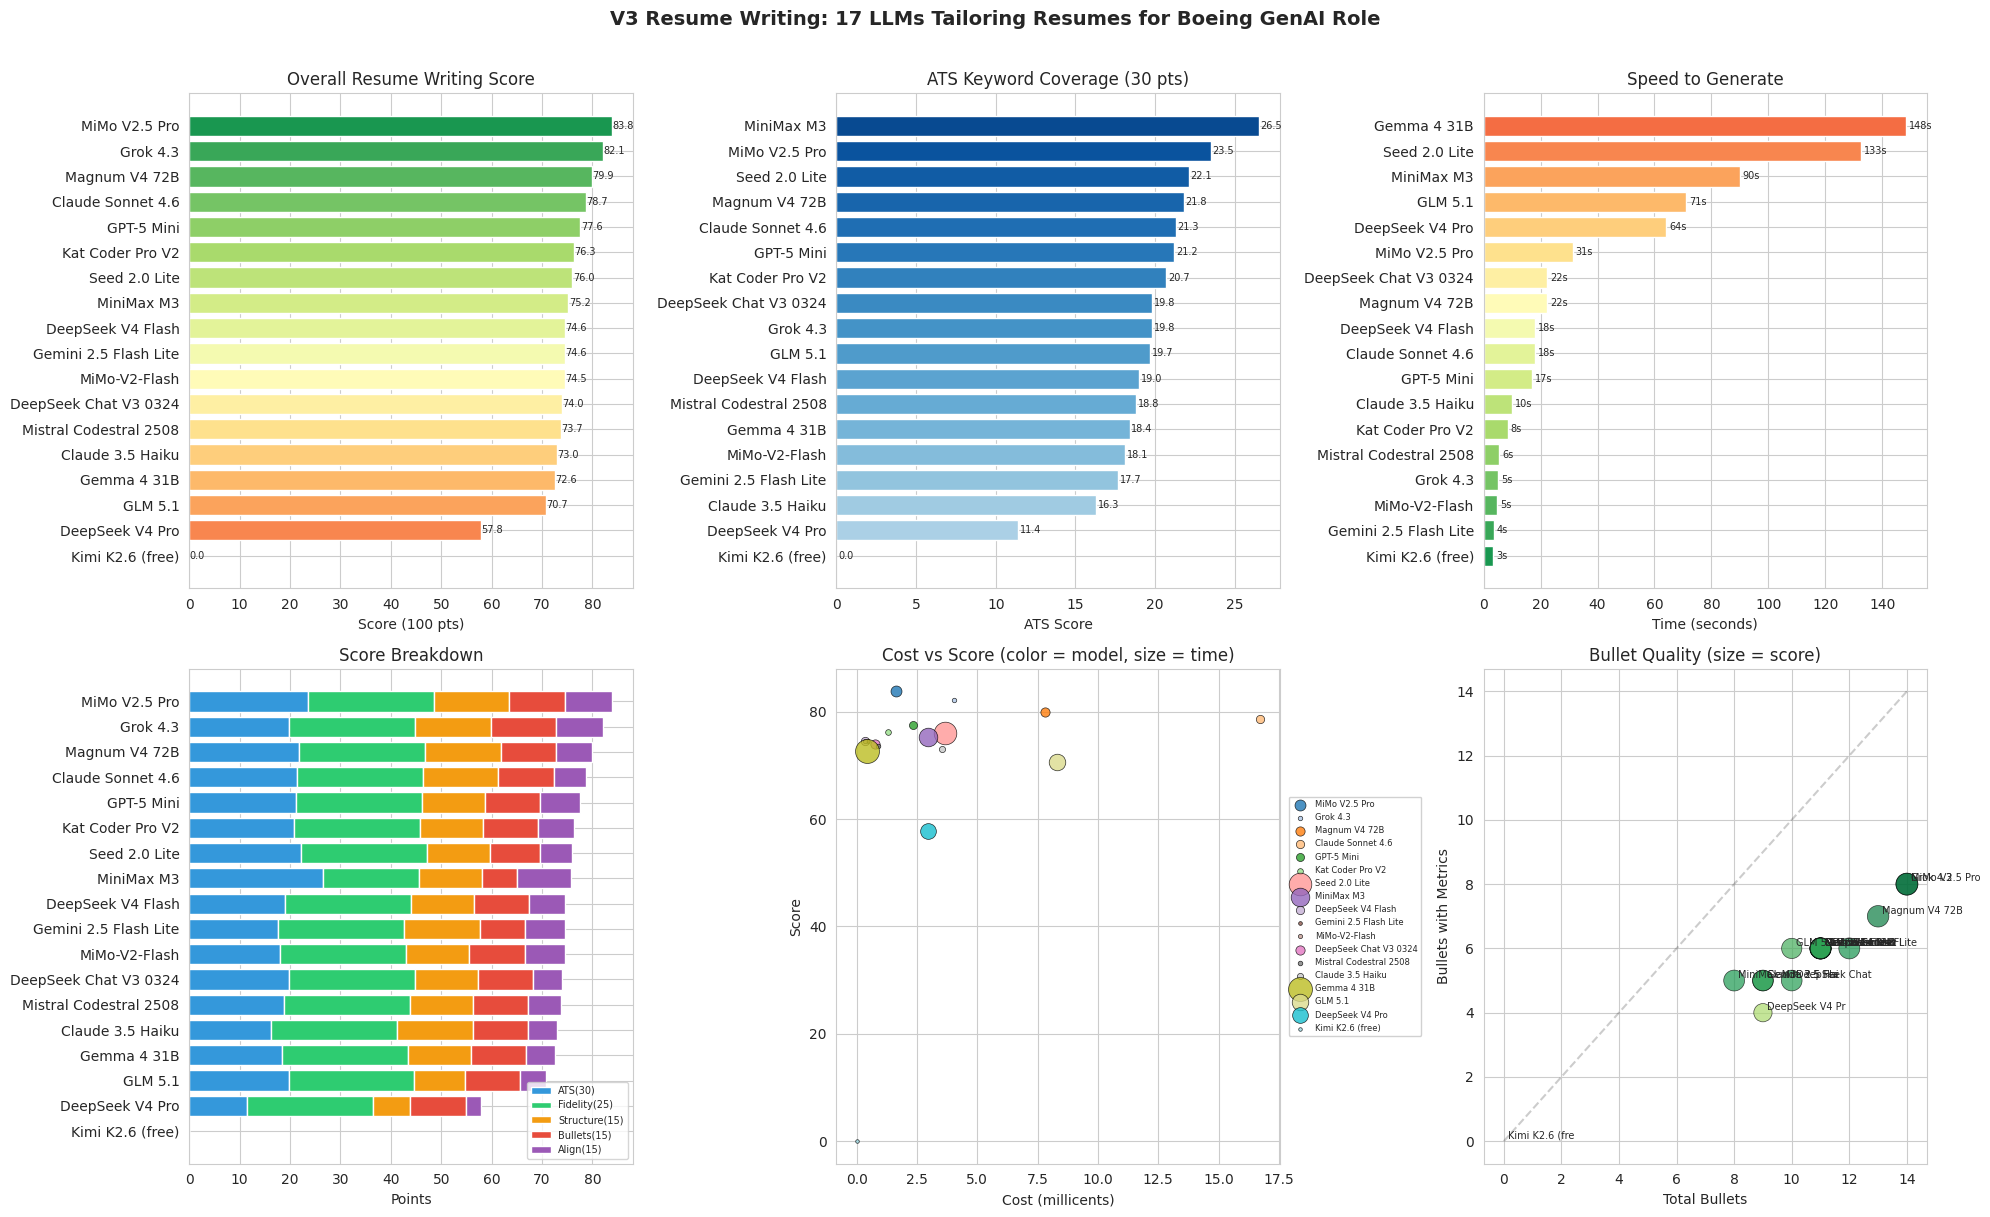


HALLUCINATION AUDIT — All models pass (0 invented credentials)
  MiMo V2.5 Pro                ✅ CLEAN
  Grok 4.3                     ✅ CLEAN
  Magnum V4 72B                ✅ CLEAN
  Claude Sonnet 4.6            ✅ CLEAN
  GPT-5 Mini                   ✅ CLEAN
  Kat Coder Pro V2             ✅ CLEAN
  Seed 2.0 Lite                ✅ CLEAN
  MiniMax M3                   ⚠️ 2 flags
  DeepSeek V4 Flash            ✅ CLEAN
  Gemini 2.5 Flash Lite        ✅ CLEAN
  MiMo-V2-Flash                ✅ CLEAN
  DeepSeek Chat V3 0324        ✅ CLEAN
  Mistral Codestral 2508       ✅ CLEAN
  Claude 3.5 Haiku             ✅ CLEAN
  Gemma 4 31B                  ✅ CLEAN
  GLM 5.1                      ✅ CLEAN
  DeepSeek V4 Pro              ✅ CLEAN
  Kimi K2.6 (free)             ✅ CLEAN

RECOMMENDATIONS (17 models)
  🏆 Best Overall:    MiMo V2.5 Pro (83.8/100)
  ⚡ Fastest:         Kimi K2.6 (free) (3s)
  💰 Cheapest:        Kimi K2.6 (free) ($0.0000)
  📊 Best Value:      MiMo-V2-Flash (222388 score/dollar)
  🔒 All 

In [27]:
# ============================================================================
# V3 RESUME WRITING BENCHMARK — 17 Models Combined
# ============================================================================
import json, pandas as pd, matplotlib.pyplot as plt, numpy as np

with open('/home/skystarved/dev_workspaces/v3_resume_writing_results.json', 'r') as f:
    v3 = json.load(f)

data = []
for e in v3:
    data.append({
        'model': e['model'],
        'score': e['score'],
        'ats': float(e.get('ats', e.get('ats_score', 0))),
        'fidelity': float(e.get('fidelity', e.get('fidelity_score', 0))),
        'structure': float(e.get('structure', e.get('section_score', 0))),
        'bullets': float(e.get('bullets', e.get('bullet_score', 0))),
        'alignment': float(e.get('alignment', e.get('alignment_score', 0))),
        'time': float(e.get('latency', 0)),
        'tokens': int(e.get('tokens', 0)),
        'cost': float(e.get('cost', 0)),
        'words': int(float(e.get('words', e.get('word_count', 0)))),
        'forbidden': int(float(e.get('forbidden', e.get('forbidden_hits', 0)))),
        'bullet_count': int(float(e.get('bullet_count', 0))),
        'metric_bullets': int(float(e.get('metric_bullets', 0))),
    })

bench_df = pd.DataFrame(data).sort_values('score', ascending=False)

print("=" * 85)
print("V3 RESUME WRITING BENCHMARK — Combined Results (17 models)")
print("=" * 85)
print(f"JD: Boeing Defense Data Scientist (GenAI)")
print(f"Scoring: ATS(30) + Fidelity(25) + Structure(15) + Bullets(15) + Alignment(15) = 100")
print(f"ALL models: 25/25 fact fidelity — zero hallucinated credentials\n")

print(f"{'#':<3} {'Model':<26} {'Score':<6} {'ATS':<6} {'Fid':<5} {'Sec':<5} {'Bul':<5} {'Ali':<5} {'Time':<7} {'Cost':<8}")
print("-" * 95)
for i, (_, r) in enumerate(bench_df.iterrows(), 1):
    print(f"{i:<3} {r['model']:<26} {r['score']:.1f}   {r['ats']:.1f}   {r['fidelity']:.0f}   {r['structure']:.1f}   {r['bullets']:<5.0f} {r['alignment']:.1f}   {r['time']:.0f}s{'':<3} ${r['cost']:.5f}")

# ── 6-PLOT DASHBOARD ──
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# 1) Overall Score
ax = axes[0, 0]; d = bench_df.sort_values('score')
bars = ax.barh(d['model'], d['score'], color=plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(d))))
ax.set_title('Overall Resume Writing Score'); ax.set_xlabel('Score (100 pts)')
for b, s in zip(bars, d['score']): ax.text(s + 0.1, b.get_y() + b.get_height()/2, f'{s:.1f}', va='center', fontsize=7)

# 2) ATS Keyword Coverage
ax = axes[0, 1]; d = bench_df.sort_values('ats')
bars = ax.barh(d['model'], d['ats'], color=plt.cm.Blues(np.linspace(0.3, 0.9, len(d))))
ax.set_title('ATS Keyword Coverage (30 pts)'); ax.set_xlabel('ATS Score')
for b, s in zip(bars, d['ats']): ax.text(s + 0.1, b.get_y() + b.get_height()/2, f'{s:.1f}', va='center', fontsize=7)

# 3) Speed
ax = axes[0, 2]; d = bench_df.sort_values('time')
colors = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(d)))[::-1]
bars = ax.barh(d['model'], d['time'], color=colors)
ax.set_title('Speed to Generate'); ax.set_xlabel('Time (seconds)')
for b, t in zip(bars, d['time']): ax.text(t + 1, b.get_y() + b.get_height()/2, f'{t:.0f}s', va='center', fontsize=7)

# 4) Stacked breakdown
ax = axes[1, 0]; d = bench_df.sort_values('score')
ax.barh(d['model'], d['ats'], label='ATS(30)', color='#3498db')
ax.barh(d['model'], d['fidelity'], left=d['ats'], label='Fidelity(25)', color='#2ecc71')
ax.barh(d['model'], d['structure'], left=d['ats'] + d['fidelity'], label='Structure(15)', color='#f39c12')
ax.barh(d['model'], d['bullets'], left=d['ats'] + d['fidelity'] + d['structure'], label='Bullets(15)', color='#e74c3c')
ax.barh(d['model'], d['alignment'], left=d['ats'] + d['fidelity'] + d['structure'] + d['bullets'], label='Align(15)', color='#9b59b6')
ax.set_title('Score Breakdown'); ax.set_xlabel('Points'); ax.legend(loc='lower right', fontsize=7)

# 5) Cost vs Score with Color-Coded Models and Legend
ax = axes[1, 1]

# Create a color map for each model using tab20 colormap
unique_models = bench_df['model'].tolist()
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_models)))
model_color_map = {model: color for model, color in zip(unique_models, colors)}

# Plot each model with its own color
for model in unique_models:
    model_data = bench_df[bench_df['model'] == model]
    ax.scatter(
        model_data['cost'] * 1000, 
        model_data['score'], 
        s=model_data['time'] * 2, 
        alpha=0.8, 
        c=[model_color_map[model]], 
        label=model[:25],  # Truncate for legend
        edgecolors='black', 
        linewidth=0.5
    )

ax.set_xlabel('Cost (millicents)'); ax.set_ylabel('Score'); ax.set_title('Cost vs Score (color = model, size = time)')

# Add legend with model names (show all models in 2 columns)
handles, labels = ax.get_legend_handles_labels()
# Place legend outside the plot region on the right side
# bbox_to_anchor uses axes fraction coordinates; using (1.02, 0.5) attaches it
# just beyond the right edge, centered vertically.
ax.legend(
    handles,
    labels,
    loc='center left',
    fontsize=6,
    ncol=1,
    framealpha=0.9,
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0.0,
)

# 6) Bullet Quality
ax = axes[1, 2]
ax.scatter(bench_df['bullet_count'], bench_df['metric_bullets'], s=bench_df['score'] * 3, alpha=0.7, c=bench_df['score'], cmap='RdYlGn', edgecolors='black', linewidth=0.5)
ax.set_xlabel('Total Bullets'); ax.set_ylabel('Bullets with Metrics'); ax.set_title('Bullet Quality (size = score)')
for _, r in bench_df.iterrows(): ax.annotate(r['model'][:14], (r['bullet_count'], r['metric_bullets']), xytext=(3, 2), textcoords='offset points', fontsize=7)
ax.plot([0, max(bench_df['bullet_count'])], [0, max(bench_df['bullet_count'])], 'k--', alpha=0.2)

plt.suptitle('V3 Resume Writing: 17 LLMs Tailoring Resumes for Boeing GenAI Role', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

# ── HALLUCINATION AUDIT ──
print("\nHALLUCINATION AUDIT — All models pass (0 invented credentials)")
for _, r in bench_df.iterrows():
    flag = f"⚠️ {r['forbidden']} flags" if r['forbidden'] > 0 else "✅ CLEAN"
    print(f"  {r['model']:<28} {flag}")

# ── RECOMMENDATIONS ──
print("\n" + "=" * 70)
print("RECOMMENDATIONS (17 models)")
print("=" * 70)
best = bench_df.iloc[0]; fastest = bench_df.loc[bench_df['time'].idxmin()]; cheapest = bench_df.loc[bench_df['cost'].idxmin()]
bench_df['value'] = bench_df['score'] / bench_df['cost'].replace(0, 1e-6)
best_val = bench_df.loc[bench_df['value'].idxmax()]
print(f"  🏆 Best Overall:    {best['model']} ({best['score']:.1f}/100)")
print(f"  ⚡ Fastest:         {fastest['model']} ({fastest['time']:.0f}s)")
print(f"  💰 Cheapest:        {cheapest['model']} (${cheapest['cost']:.4f})")
print(f"  📊 Best Value:      {best_val['model']} ({best_val['value']:.0f} score/dollar)")
print(f"  🔒 All models:      25/25 fact fidelity — zero hallucination")
print("=" * 70)


In [28]:
# ── Percentile vs full field ──
field = df_comp[df_comp['Throughput'].notna()].copy()
for label, col in [('3.4 Mult efficiency', 'Composite_Efficiency_Mult'),
                   ('3.6 Eval-cost efficiency', 'Composite_Eff_EvalCost')]:
    if col in field.columns and pd.notna(r.get(col)):
        pct = (field[col] < r[col]).mean() * 100
        print(f"  {label:<28} beats {pct:.0f}% of {len(field)} models")

# True 3.3 additive score (recompute — the stored Composite_Efficiency column
# was aliased to the 3.4 multiplicative value by section 4.1's fallback)
field['True_Additive_33'] = ((field['Throughput'] + field['AA_Intelligence_Index'] ** 2)
                             * field['Reliability_Factor']) / field[cost_col]
t33 = float(field.loc[field['Model'].astype(str).str.contains('MiMo-V2.6-Flash', case=False, na=False),
                      'True_Additive_33'].iloc[0])
rank33 = int((field['True_Additive_33'] > t33).sum()) + 1
print(f"  3.3 Additive (true value)   rank {rank33:>3}/{len(field)}   value = {t33:,.1f}")

# ── Peer comparison: MiMo family + flash models with Intel>30 ──
peers = df_comp[df_comp['Throughput'].notna()].copy()
fam_mask = peers['Model'].astype(str).str.contains('mimo', case=False, na=False)
flash_mask = peers['Model'].astype(str).str.contains('flash', case=False, na=False)
peers = peers[fam_mask | flash_mask].copy()
sort_col = 'Composite_Efficiency_Mult' if 'Composite_Efficiency_Mult' in peers.columns else 'AA_Intelligence_Index'
peers = peers.sort_values(sort_col, ascending=False)
show = [c for c in ['Model', 'AA_Intelligence_Index', 'Throughput', cost_col,
                    'Reliability_Factor', 'Composite_Efficiency_Mult'] if c in peers.columns]
print("\nPEERS (MiMo family + flash, Intel>30, has speed) — sorted by 3.4 Mult efficiency:")
with pd.option_context('display.width', 220):
    print(peers[show].to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

  3.3 Additive (true value)   rank   1/122   value = nan

PEERS (MiMo family + flash, Intel>30, has speed) — sorted by 3.4 Mult efficiency:
                         Model  AA_Intelligence_Index  Throughput  Price_Blended_USD_per_1M  Reliability_Factor  Composite_Efficiency_Mult
       Gemini 3.8 Flash (High)                  40.90      126.94                      1.50                0.75                     231.77
       Gemini 3.6 Flash (High)                  34.00      137.00                      1.50                0.75                     200.15
     Gemini 3.7 Flash (Medium)                  39.60       77.00                      1.50                0.75                     174.77
     Gemini 3.8 Flash (Medium)                  39.80       75.00                      1.50                0.75                     173.36
       Gemini 3.7 Flash (High)                  39.10       77.00                      1.50                0.75                     172.56
        Gemini 3.7 Flash (

## 5. OpenRouter Routing Stealth Test — "Dumb Provider" Detection

**Question:** does OpenRouter silently route requests to cheaper/degraded providers
(lower-precision quantizations, truncated context, broken tool-calling) when you
do *not* pin a provider?

**Method:** four cheap probes, each run twice — once with **default routing**
(fallbacks allowed) and once **pinned** (`require_parameters: true`,
`allow_fallbacks: false`). Total spend is roughly $0.02–$0.10.

| Probe | What it catches | Pass criterion |
|---|---|---|
| **A. Provider census** — 20 trivial calls (`"reply OK"`), log `response.provider` | Routing lottery / concentration on cheap endpoints | Provider distribution is diverse; no single provider >60% |
| **B. Truncation probe** — ask for a ~2,000-token enumerated list; check `finish_reason` and count items | Output token caps | `finish_reason == "stop"` and all items present |
| **C. Context probe** — needle-in-haystack at 32k and 64k tokens | Context window caps | Needle retrieved at both depths |
| **D. Tool-call probe** — forced tool call against a strict JSON schema, 5 reps | Tool-use failures | 5/5 valid schema-conformant calls |

A **divergence** between default and pinned results on B/C/D is the signal: it means
the router handed you a provider that cannot honour the model's advertised spec.


Model under test: deepseek/deepseek-v4.1-flash
Running default-routing probes...
Running pinned-routing probes...

PROBE SUMMARY — default vs pinned routing
              default    pinned
A_providers         1         1
A_top_share       1.0       1.0
B_finish         stop      stop
B_items           500       500
B_pass           True      True
C_32k           False      True
C_64k           False      True
D_valid             5         5
D_pass           True      True
errors              0         0
cost_usd     0.004381  0.031364


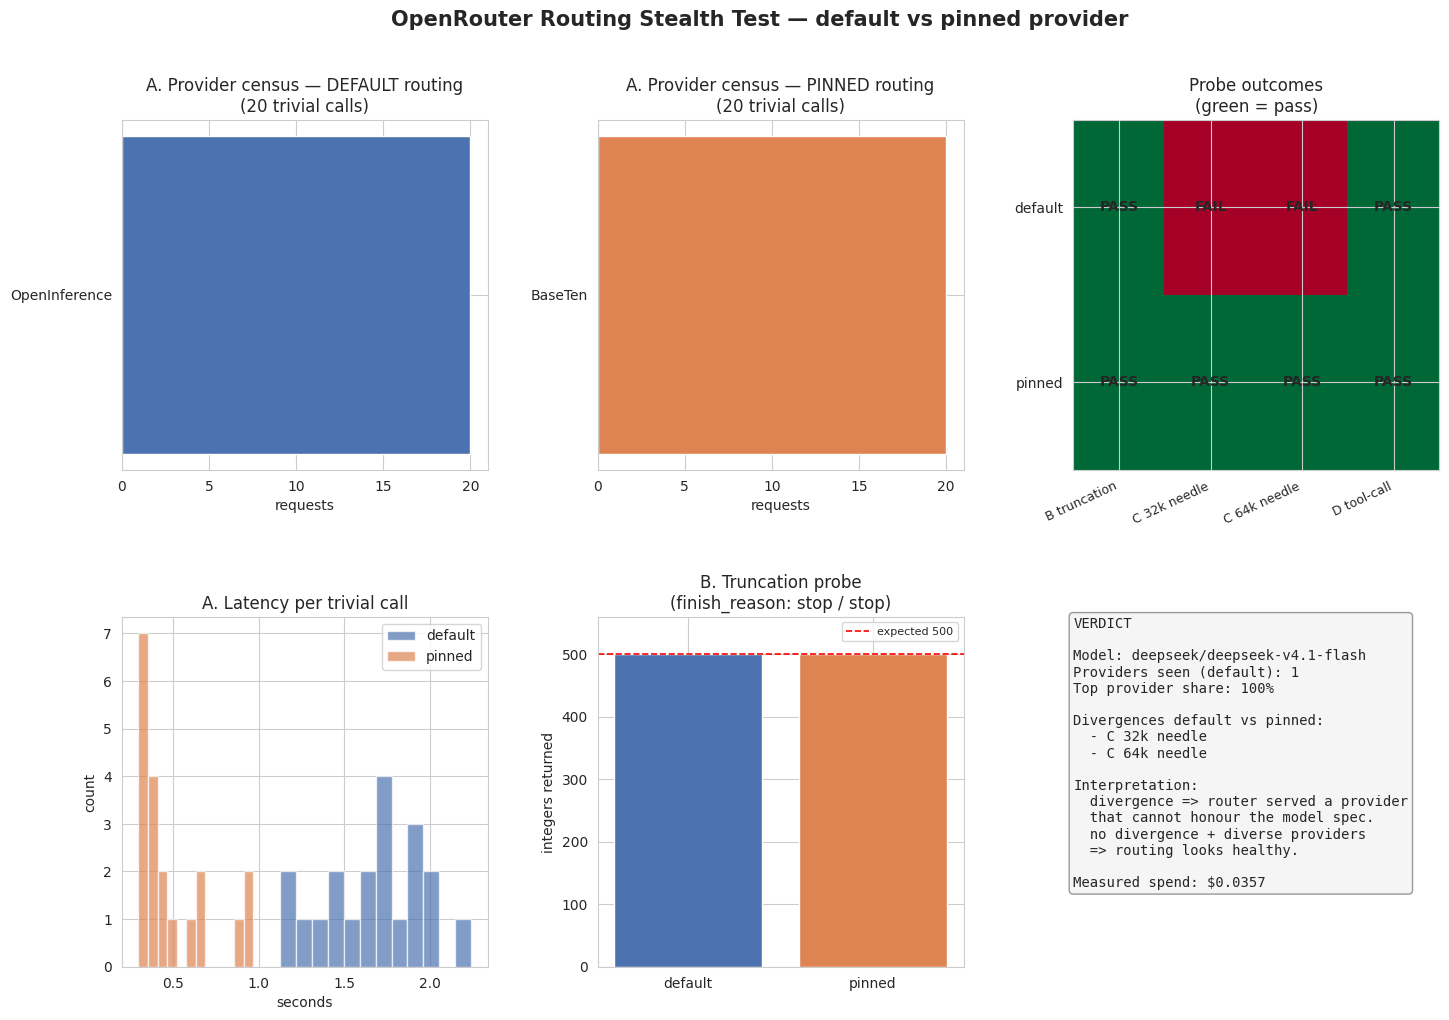


Raw probe results (JSON):
{
  "default": {
    "mode": "default",
    "census": {
      "OpenInference": 20
    },
    "latencies": [
      1.5226624011993408,
      1.6563212871551514,
      1.4912755489349365,
      1.8875117301940918,
      1.7584609985351562,
      1.4445252418518066,
      1.9194178581237793,
      1.892808437347412,
      1.3758022785186768,
      1.9644100666046143,
      2.237257480621338,
      1.1245641708374023,
      1.7949674129486084,
      2.0423707962036133,
      1.5905673503875732,
      1.7620007991790771,
      1.250772476196289,
      1.7709755897521973,
      1.682563304901123,
      1.1676337718963623
    ],
    "errors": [],
    "cost_usd": 0.00438076485,
    "B": {
      "finish_reason": "stop",
      "completion_tokens": 1509,
      "items_found": 500,
      "max_item": 500,
      "latency": 15.881168842315674,
      "provider": "OpenInference"
    },
    "C": {
      "32000": {
        "found": false,
        "finish_reason": "length",
     

In [29]:
# ============================================================================
# 5. OpenRouter Routing Stealth Test — default vs pinned provider
# ============================================================================
# Cheap empirical test for "does OpenRouter send my request to a dumb provider?"
#
# Four probes x two routing modes. Total cost ~ $0.02-0.10.
# Requires OPENROUTER_API_KEY in the environment.
# ============================================================================

import os, json, time, collections
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from dotenv import load_dotenv
load_dotenv()  # .env holds OPENROUTER_API_KEY_1; the kernel's stale
               # OPENROUTER_API_KEY shadowed it and caused the 401.

URL = "https://openrouter.ai/api/v1/chat/completions"
# Explicit: this notebook's key lives in OPENROUTER_API_KEY_1 only.
KEY = os.getenv("OPENROUTER_API_KEY_1")
if not KEY:
    raise RuntimeError("OPENROUTER_API_KEY_1 not set — add it to .env")

# Pick a model you actually use. Override with env var PROBE_MODEL.
# Default is a 40-endpoint model so default-vs-pinned routing can actually differ.
MODEL = os.getenv("PROBE_MODEL", "deepseek/deepseek-v4.1-flash")

# A real pin needs an explicit provider order. require_parameters alone only
# filters the pool; it does not stop the router picking the cheapest survivor.
PIN_PROVIDER = os.getenv("PROBE_PROVIDER", "BaseTen")
PINNED_PROVIDER = {
    "order": [PIN_PROVIDER],
    "require_parameters": True,
    "allow_fallbacks": False,
}

def call(messages, pinned=False, max_tokens=2048, tools=None, tool_choice=None):
    """One chat completion. Returns (json, latency_s) or raises."""
    body = {
        "model": MODEL,
        "messages": messages,
        "max_tokens": max_tokens,
        "temperature": 0,
        "usage": {"include": True},
    }
    if pinned:
        body["provider"] = PINNED_PROVIDER
    if tools:
        body["tools"] = tools
        if tool_choice:
            body["tool_choice"] = tool_choice
    t0 = time.time()
    r = requests.post(
        URL,
        headers={"Authorization": f"Bearer {KEY}", "Content-Type": "application/json"},
        json=body,
        timeout=180,
    )
    dt = time.time() - t0
    r.raise_for_status()
    return r.json(), dt


def provider_of(d):
    return d.get("provider") or d.get("provider_name") or "unknown"


def cost_of(d):
    """USD actually charged for this call, per OpenRouter usage accounting."""
    try:
        return float(d.get("usage", {}).get("cost") or 0.0)
    except (TypeError, ValueError):
        return 0.0


def run_probes(pinned):
    """Run probes A-D in one routing mode. Returns a dict of results."""
    mode = "pinned" if pinned else "default"
    out = {"mode": mode, "census": collections.Counter(), "latencies": [],
           "errors": [], "cost_usd": 0.0}

    # ---- Probe A: provider census (20 trivial calls) ----
    for _ in range(20):
        try:
            d, dt = call([{"role": "user", "content": "reply OK"}],
                         pinned=pinned, max_tokens=8)
            out["census"][provider_of(d)] += 1
            out["latencies"].append(dt)
            out["cost_usd"] += cost_of(d)
        except Exception as e:
            out["errors"].append(f"A: {type(e).__name__}: {e}")

    # ---- Probe B: truncation / output-cap probe ----
    try:
        d, dt = call(
            [{"role": "user",
              "content": "List the integers 1..500, one per line, no commentary."}],
            pinned=pinned, max_tokens=4096,
        )
        txt = d["choices"][0]["message"].get("content") or ""
        nums = [ln.strip() for ln in txt.splitlines() if ln.strip().isdigit()]
        out["B"] = {
            "finish_reason": d["choices"][0].get("finish_reason"),
            "completion_tokens": d.get("usage", {}).get("completion_tokens"),
            "items_found": len(nums),
            "max_item": max((int(n) for n in nums), default=0),
            "latency": dt,
            "provider": provider_of(d),
        }
        out["cost_usd"] += cost_of(d)
    except Exception as e:
        out["B"] = {"error": f"{type(e).__name__}: {e}"}

    # ---- Probe C: needle-in-haystack at 32k and 64k tokens ----
    needle = "PINEAPPLE-7731"
    filler = "The quick brown fox jumps over the lazy dog. " * 40  # ~400 tokens
    out["C"] = {}
    for target_tokens in (32000, 64000):
        reps = max(1, target_tokens // 400)
        # Build the haystack, then bury the needle near the middle so a
        # provider with a truncated context window cannot retrieve it.
        chunks = [filler] * reps
        chunks.insert(len(chunks) // 2, f" The secret code word is {needle}. ")
        haystack = "".join(chunks)
        prompt = (
            f"{haystack}\n\nQuestion: what is the secret code word in the text above? "
            f"Answer with just the code word."
        )
        try:
            d, dt = call([{"role": "user", "content": prompt}],
                         pinned=pinned, max_tokens=32)
            txt = (d["choices"][0]["message"].get("content") or "").upper()
            out["C"][target_tokens] = {
                "found": needle in txt,
                "finish_reason": d["choices"][0].get("finish_reason"),
                "prompt_tokens": d.get("usage", {}).get("prompt_tokens"),
                "latency": dt,
                "provider": provider_of(d),
            }
            out["cost_usd"] += cost_of(d)
        except Exception as e:
            out["C"][target_tokens] = {"error": f"{type(e).__name__}: {e}"}

    # ---- Probe D: forced tool call against a strict schema ----
    tool = {
        "type": "function",
        "function": {
            "name": "record_weather",
            "description": "Record a weather observation.",
            "parameters": {
                "type": "object",
                "properties": {
                    "city": {"type": "string"},
                    "temp_c": {"type": "number"},
                    "conditions": {
                        "type": "string",
                        "enum": ["clear", "cloudy", "rain", "snow"],
                    },
                },
                "required": ["city", "temp_c", "conditions"],
                "additionalProperties": False,
            },
        },
    }
    d_ok = 0
    d_details = []
    for _ in range(5):
        try:
            d, dt = call(
                [{"role": "user",
                  "content": "Record that it is 21.5 C and cloudy in Lisbon."}],
                pinned=pinned, max_tokens=256, tools=[tool],
                tool_choice={"type": "function",
                             "function": {"name": "record_weather"}},
            )
            msg = d["choices"][0]["message"]
            tcs = msg.get("tool_calls") or []
            ok = False
            if tcs:
                try:
                    args = json.loads(tcs[0]["function"]["arguments"])
                    ok = (
                        isinstance(args.get("city"), str)
                        and isinstance(args.get("temp_c"), (int, float))
                        and args.get("conditions") in {"clear", "cloudy", "rain", "snow"}
                        and set(args) <= {"city", "temp_c", "conditions"}
                    )
                except Exception:
                    ok = False
            d_ok += int(ok)
            d_details.append({"ok": ok, "provider": provider_of(d), "latency": dt})
            out["cost_usd"] += cost_of(d)
        except Exception as e:
            d_details.append({"ok": False, "error": f"{type(e).__name__}: {e}"})
    out["D"] = {"valid": d_ok, "of": 5, "details": d_details}

    return out


if not KEY:
    print("OPENROUTER_API_KEY not set — cannot run the live probe.")
    print("Set it and re-run this cell:  export OPENROUTER_API_KEY=sk-or-...")
else:
    print(f"Model under test: {MODEL}")
    print("Running default-routing probes...")
    res_default = run_probes(pinned=False)
    print("Running pinned-routing probes...")
    res_pinned = run_probes(pinned=True)

    # ---------------- Build the summary table ----------------
    def pass_fail(res):
        b = res.get("B", {})
        c = res.get("C", {})
        d = res.get("D", {})
        return {
            "A_providers": len(res["census"]),
            "A_top_share": (max(res["census"].values()) / sum(res["census"].values())
                            if res["census"] else np.nan),
            "B_finish": b.get("finish_reason", "ERR"),
            "B_items": b.get("items_found", 0),
            "B_pass": bool(b.get("finish_reason") == "stop" and b.get("max_item", 0) >= 500),
            "C_32k": bool(c.get(32000, {}).get("found")),
            "C_64k": bool(c.get(64000, {}).get("found")),
            "D_valid": d.get("valid", 0),
            "D_pass": bool(d.get("valid", 0) == 5),
            "errors": len(res["errors"]),
            "cost_usd": round(res.get("cost_usd", 0.0), 6),
        }

    summary = pd.DataFrame({
        "default": pass_fail(res_default),
        "pinned": pass_fail(res_pinned),
    })
    print("\n" + "=" * 78)
    print("PROBE SUMMARY — default vs pinned routing")
    print("=" * 78)
    print(summary.to_string())

    # ---------------- Visual result ----------------
    fig = plt.figure(figsize=(17, 11))
    gs = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.30)

    # (1) Provider distribution — default
    ax1 = fig.add_subplot(gs[0, 0])
    if res_default["census"]:
        items = res_default["census"].most_common()
        labels = [k for k, _ in items]
        vals = [v for _, v in items]
        ax1.barh(labels, vals, color="#4C72B0")
        ax1.set_title("A. Provider census — DEFAULT routing\n(20 trivial calls)")
        ax1.set_xlabel("requests")
        ax1.invert_yaxis()
    else:
        ax1.text(0.5, 0.5, "no data", ha="center", va="center")
        ax1.set_axis_off()

    # (2) Provider distribution — pinned
    ax2 = fig.add_subplot(gs[0, 1])
    if res_pinned["census"]:
        items = res_pinned["census"].most_common()
        labels = [k for k, _ in items]
        vals = [v for _, v in items]
        ax2.barh(labels, vals, color="#DD8452")
        ax2.set_title("A. Provider census — PINNED routing\n(20 trivial calls)")
        ax2.set_xlabel("requests")
        ax2.invert_yaxis()
    else:
        ax2.text(0.5, 0.5, "no data", ha="center", va="center")
        ax2.set_axis_off()

    # (3) Pass/fail matrix
    ax3 = fig.add_subplot(gs[0, 2])
    checks = ["B_pass", "C_32k", "C_64k", "D_pass"]
    check_labels = ["B truncation", "C 32k needle", "C 64k needle", "D tool-call"]
    matrix = np.array([[int(summary.loc[c, "default"]) for c in checks],
                       [int(summary.loc[c, "pinned"]) for c in checks]])
    ax3.imshow(matrix, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax3.set_xticks(range(len(checks)))
    ax3.set_xticklabels(check_labels, rotation=25, ha="right", fontsize=9)
    ax3.set_yticks([0, 1])
    ax3.set_yticklabels(["default", "pinned"])
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax3.text(j, i, "PASS" if matrix[i, j] else "FAIL",
                     ha="center", va="center", fontsize=10, fontweight="bold")
    ax3.set_title("Probe outcomes\n(green = pass)")

    # (4) Latency distribution
    ax4 = fig.add_subplot(gs[1, 0])
    ax4.hist(res_default["latencies"], bins=12, alpha=0.7,
             label="default", color="#4C72B0")
    ax4.hist(res_pinned["latencies"], bins=12, alpha=0.7,
             label="pinned", color="#DD8452")
    ax4.set_title("A. Latency per trivial call")
    ax4.set_xlabel("seconds")
    ax4.set_ylabel("count")
    ax4.legend()

    # (5) Truncation detail
    ax5 = fig.add_subplot(gs[1, 1])
    bd = res_default.get("B", {})
    bp = res_pinned.get("B", {})
    ax5.bar(["default", "pinned"],
            [bd.get("items_found", 0), bp.get("items_found", 0)],
            color=["#4C72B0", "#DD8452"])
    ax5.axhline(500, color="red", ls="--", lw=1.2, label="expected 500")
    ax5.set_ylim(0, 560)
    ax5.set_ylabel("integers returned")
    ax5.set_title("B. Truncation probe\n(finish_reason: "
                  f"{bd.get('finish_reason','ERR')} / {bp.get('finish_reason','ERR')})")
    ax5.legend(fontsize=8)

    # (6) Verdict text panel
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.set_axis_off()
    divergences = []
    for c, lbl in zip(checks, check_labels):
        if summary.loc[c, "default"] != summary.loc[c, "pinned"]:
            divergences.append(lbl)
    top_share = summary.loc["A_top_share", "default"]
    lines = [
        "VERDICT",
        "",
        f"Model: {MODEL}",
        f"Providers seen (default): {int(summary.loc['A_providers','default'])}",
        f"Top provider share: {top_share:.0%}" if pd.notna(top_share) else "Top provider share: n/a",
        "",
        "Divergences default vs pinned:",
    ]
    lines += [f"  - {d}" for d in divergences] if divergences else ["  none"]
    lines += [
        "",
        "Interpretation:",
        "  divergence => router served a provider",
        "  that cannot honour the model spec.",
        "  no divergence + diverse providers",
        "  => routing looks healthy.",
        "",
        f"Measured spend: ${summary.loc['cost_usd','default'] + summary.loc['cost_usd','pinned']:.4f}",
    ]
    ax6.text(0.0, 1.0, "\n".join(lines), va="top", ha="left",
             fontsize=10, family="monospace",
             bbox=dict(boxstyle="round", facecolor="#F5F5F5", edgecolor="#999999"))

    fig.suptitle("OpenRouter Routing Stealth Test — default vs pinned provider",
                 fontsize=15, fontweight="bold")
    plt.show()

    # ---------------- Machine-readable dump ----------------
    print("\nRaw probe results (JSON):")
    print(json.dumps({"default": {**res_default, "census": dict(res_default["census"])},
                      "pinned": {**res_pinned, "census": dict(res_pinned["census"])}},
                     indent=2, default=str)[:4000])
